# Calorías de un plato a partir de una foto

### Redes preentrenadas, margen de error y prueba en una cafetería no vista (Nutrition5k)

**Autor:** Matías Martínez Moreno

---

## La idea y el problema

Calcular las calorías de un plato a ojo falla mucho. En el estudio que presentó el dataset Nutrition5k, personas sin formación se equivocaron en promedio 53 % al estimar la masa de un plato, y nutricionistas, 41 %. Las aplicaciones de celular tampoco lo resuelven: un estudio del NIH presentado en NUTRITION 2026 (resultados preliminares) comparó cuatro apps comerciales que estiman calorías desde una foto (MyFitnessPal, LoseIt!, CalAI y Appediet) con 102 comidas preparadas en una cocina metabólica, y las cuatro subestimaron las calorías en cerca de un tercio (de 250 a 345 kcal por comida), sobre todo por la grasa (≈ 30 g).

Este notebook entrena redes que miran la foto de un plato, tomada desde arriba, y estiman cinco cantidades: **calorías, masa, grasa, carbohidratos y proteína**, cada una con un intervalo del 90 %. Además se mide cuándo y por qué fallan fuera del lugar donde se entrenaron.

Se parte de un resultado publicado (Thames et al., 2021), se usan redes preentrenadas (DINOv2, ConvNeXt, EfficientNetV2, ResNet) y se prueba el sistema en una muestra externa: 238 platos de una segunda cafetería que el trabajo original no utilizó. El uso al que apunta es el de comedores con cámara fija (hospitales, casinos, universidades) y el de apoyo a nutricionistas y a personas con diabetes u obesidad, siempre con el margen de error a la vista.


## Qué se busca

1. **¿Se confirma el resultado publicado?** Una red preentrenada, evaluada con el mismo protocolo y la misma métrica que Nutrition5k, ¿alcanza o supera el error de los trabajos publicados? (En las conclusiones calculadas, objetivo 1.)
2. **¿Se aporta algo?** ¿Qué agrega cada componente (receta de entrenamiento, profundidad medida o estimada desde la foto, ensamble, entrenar más tiempo, aumento de datos) y cuáles de esas diferencias son reales y no ruido? (Objetivo 2.)
3. **¿Qué tan confiable es?** ¿Cuánto error, sesgo y cobertura de los intervalos hay en otra cafetería y en otra vista de cámara, cuántos platos pesados del lugar nuevo hacen falta para corregirlos y dónde falla el modelo? (Objetivo 3.)


## El resultado en breve

Error de calorías como porcentaje de la media real (PMAE; menos es mejor) en el test oficial de Nutrition5k (507 platos con foto cenital) y en la cafetería externa (228 platos). Entre corchetes, el intervalo del 95 % del bootstrap por cadenas.

| | Test oficial | Cafe 2 (otra cafetería) |
|---|---|---|
| *Publicado · Thames et al. 2021, fotogramas laterales* | 26,1 % | no evaluado |
| *Publicado · Thames et al. 2021, foto cenital + profundidad (4.º canal)* | 18,8 % | no evaluado |
| *Publicado · Thames et al. 2021, foto cenital + volumen* | 16,5 % | no evaluado |
| *Publicado · Han et al. 2023, ResNet-101, foto cenital* | 17,9 % | no evaluado |
| *Publicado · Shao et al. 2023, RGB-D* | 15,0 % | no evaluado |
| *Publicado · Han et al. 2023, DPF-Nutrition, solo foto* | 14,7 % | no evaluado |
| **Este trabajo · ensamble solo foto** | 15,4 % [13,8–17,0] | 26,0 % [22,5–29,8] |
| **Este trabajo · foto + profundidad estimada** | 15,2 % [13,5–16,9] | 26,1 % [22,7–29,9] |
| **Este trabajo · foto + sensor de profundidad** | **13,8 %** [12,3–15,4] | 29,5 % [26,0–33,4] |

**Lo que funcionó**
- Con el sensor, el error (13,8 %, 35,2 kcal) queda por debajo de los 18,8 % de Thames con foto cenital y los 17,9 % de ResNet-101; frente a DPF-Nutrition (14,7 %) y Shao (15,0 %) la diferencia cae dentro del margen. Solo con la foto (15,4 %) el resultado empata con DPF-Nutrition.
- La masa se estima con 9,5 % de error con el sensor, frente al 41–53 % de las personas a ojo.
- Reentrenar la red completa fue indispensable: con la red congelada el error se queda entre 23 y 25 %.
- Pesar 20 platos del lugar nuevo corrige el sesgo y lleva la cobertura de los intervalos de 64 % a 90 %.

**Lo que no funcionó**
- En otra cafetería el error sube a 26–29,5 %. El sensor de profundidad, que ayuda en casa (−1,6 puntos), perjudica fuera (+3,5 puntos): subestima la masa en cerca de 14 %.
- Los intervalos del 90 % cubren el 94 % de los platos del test, pero solo el 64 % (con sensor) y el 81 % (solo foto) en la otra cafetería.
- La profundidad estimada desde la foto mejora apenas 0,2 puntos en el test y nada en la Cafe 2; el aumento de datos fuerte y entrenar 80 minutos en lugar de 45 no cambian el error de forma distinguible del ruido.
- Reentrenar con 10 platos de la cafetería nueva no ayuda; con 40 baja el error (con sensor, de 29,9 a 23,8 %), pero con solo 3 particiones por tamaño.


## Cómo leer las cifras

- **PMAE** es el error absoluto medio dividido por la media real, en porcentaje: el cálculo del script oficial del dataset (`compute_eval_statistics.py`), replicado y verificado contra él. **MAE** es el error absoluto medio en la unidad de la variable (kcal o g).
- **Intervalos del 95 %** de las cifras: bootstrap por **cadenas** de escaneos, porque los escaneos del mismo plato no son independientes (los 507 platos del test son ≈ 260 cadenas). Una diferencia entre modelos se considera real solo si el intervalo de la diferencia (bootstrap pareado, sección 23) no cruza el 0.
- **Grupos de platos:** TR (entrenamiento), VS (validación para escoger modelos), VC (validación de calibración, solo para los intervalos), TE (test oficial) y C2 (Cafe 2, la cafetería externa). El test y la Cafe 2 se miden una sola vez, con todo decidido antes con VS y VC.
- **Etiquetas de las tablas:** «v1» marca los modelos de una corrida previa cuyas predicciones se reutilizan, y «v2», los entrenados en este notebook.
- Después de cada resultado hay una celda **Lectura** con los números de la salida que tiene justo arriba. Las salidas (tablas, gráficas, registros) se conservan tal como salieron de la ejecución en Kaggle, incluidos los títulos que genera el propio código.


## Datos y créditos

**Nutrition5k.** Thames, Q., Karpur, A., Norris, W., Xia, F., Panait, L., Weyand, T. y Sim, J. (Google Research), *Nutrition5k: Towards Automatic Nutritional Understanding of Generic Food*, CVPR 2021. Unos 5 000 platos reales de dos cafeterías de Google, pesados ingrediente por ingrediente, con foto cenital, mapa de profundidad del sensor Intel RealSense y videos con cámaras laterales. Licencia **CC BY 4.0**. Repositorio: https://github.com/google-research-datasets/nutrition5k · descarga: bucket público `gs://nutrition5k_dataset` (sin registro). Las fotos de platos que aparecen en las figuras pertenecen a este dataset.

**Fotogramas laterales.** Se leen de un espejo en Kaggle de los videos de Nutrition5k (`zygmuntyt/nutrition5k-dataset-side-angle-images`); los datos de origen son los de Nutrition5k, bajo CC BY 4.0.

**Cafe 2.** Son 238 platos de la segunda cafetería, incluidos en Nutrition5k pero sin usar en el artículo original. Sus totales vienen en cero, y las etiquetas se reconstruyeron sumando los ingredientes, regla que se verificó en la Cafe 1.

**Modelos preentrenados.** DINOv2 (Oquab et al., 2023), ConvNeXt (Liu et al., 2022), EfficientNetV2 (Tan y Le, 2021), ResNet (He et al., 2016) y Depth Anything V2 (Yang et al., 2024), descargados con `timm` y `transformers` desde Hugging Face. Las referencias completas están al final.


## Cómo correrlo

Se ejecuta en Kaggle sin tocar el código:

1. *Settings → Accelerator:* **GPU T4 x2**. *Settings → Internet:* **On**.
2. *Add Input:*
   - **`zygmuntyt/nutrition5k-dataset-side-angle-images`** (fotogramas laterales, público);
   - opcional: un dataset propio con las predicciones de una corrida previa (carpeta `predicciones` con la estructura que genera este mismo notebook en `outputs/`). Sin él, el notebook anota la omisión y continúa, y los ensambles usan solo los modelos entrenados en la ejecución.
3. *Save Version → Save & Run All.* La ejecución publicada tardó 9,35 h y Kaggle corta a las 12 h. Los resultados quedan en *Output*, carpeta `outputs/`.

Los datos de Nutrition5k se descargan solos desde el bucket público. Antes del entrenamiento largo hay una **prueba de humo** que recorre todo el flujo con pocos platos.

**Opcional:** un dataset con fotos propias cuyo nombre contenga `mis-platos` activa la sección «Prueba con fotos propias». En la ejecución publicada no se agregaron.


## Cómo está organizado

La **Parte I** define las herramientas, con una explicación corta de cada concepto. La **Parte II** las ejecuta y muestra las gráficas:

| Bloque de la Parte II | Qué se hace | Pregunta |
|---|---|---|
| Método y datos | esquema del método, etiquetas, Cafe 2, profundidad del sensor y estimada, vista lateral, fuga por escaneos repetidos | base |
| Punto de partida | resultados de la corrida previa: cinco redes, ablación y diagnóstico de la Cafe 2 | 1 y 2 |
| Arquitectura e hiperparámetros | esquema del modelo, parámetros y motivo de cada valor | 1 y 2 |
| Experimento de profundidad | sensor, sensor con aumento de altura y profundidad estimada, con entrenamientos más largos | 2 y 3 |
| Evaluación final | ensambles en el test, la Cafe 2 y la vista lateral; control con ensamble de semillas; comparación con lo publicado; sesgo (Bland-Altman); comparaciones pareadas | 1, 2 y 3 |
| Confianza y fallas | intervalos del 90 %, adaptación y reentrenamiento con pocos platos, errores por tipo de plato, Grad-CAM, prueba de estrés y fotos propias | 3 |
| Cierre | hardware y tiempos, conclusiones calculadas con la ejecución, limitaciones y usos prácticos | – |

**Técnicas tomadas de la literatura**

| Técnica | De dónde sale | Para qué se usa |
|---|---|---|
| Bootstrap por cadenas | Lian (2026) y el bootstrap por grupos | Intervalos de confianza honestos: los escaneos repetidos de un plato salen juntos en cada remuestreo. |
| Bland-Altman | Bland y Altman (1986); el mismo análisis del estudio del NIH | Sesgo (¿subestima o sobreestima?) y límites de acuerdo en kcal y en gramos de grasa. |
| Factor de escala con pocos platos | Lian (2026) | Corregir el sesgo de una cafetería nueva con *k* platos pesados. |
| Reentrenar solo la cabeza o la red completa | *Linear probing* frente a *fine-tuning*: Kumar et al. (2022) | Qué conviene reentrenar cuando el lugar nuevo da muy pocos datos. |
| Prueba de estrés de la foto | ImageNet-C: Hendrycks y Dietterich (2019) | Sensibilidad a la luz, al desenfoque, a la compresión, al giro y a la distancia de la cámara. |
| Aumento fuerte (giros, balance de blancos, desenfoque) | AugMix: Hendrycks et al. (2020) | Si entrenar con fotos alteradas da un modelo más robusto. Un solo modelo, comparado uno a uno. |
| Ensamble de semillas como control | Caruana et al. (2004) advierten que la selección voraz puede sobreajustarse a la validación | Verificar que el ensamble escogido no esté inflado. |


# Parte I · Herramientas

## 0. Configuración

Todos los parámetros están en `CFG`. Hay dos relojes: ningún entrenamiento largo puede terminar después de las **9,75 h**, y el cierre (ensamble, test, reajuste con pocos platos, figuras y guardado) termina antes de las **11 h**. Kaggle corta la sesión a las 12 h, así que queda al menos una hora de margen.

In [1]:
# ============================================================
# 0. Librerías, configuración y utilidades generales
# ============================================================
import os, sys, time, json, math, random, shutil, re, gc, copy, warnings, traceback, subprocess, threading, queue
import urllib.request, urllib.parse
from pathlib import Path
from contextlib import contextmanager, nullcontext
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
cv2.setNumThreads(1)
T0 = time.time()                     # inicio de la corrida (lo usan los relojes)

CFG = dict(
    semilla=42,
    limite_horas=11.0,               # tope total: a esta hora todo debe estar guardado (Kaggle corta a las 12 h)
    corte_entreno_horas=9.75,        # ningún entrenamiento largo puede terminar después de esta hora
    gcs='https://storage.googleapis.com/nutrition5k_dataset/nutrition5k_dataset',
    lateral_kaggle='zygmuntyt/nutrition5k-dataset-side-angle-images',
    tam_cenital=(336, 448),          # alto × ancho de entrada (la foto original es 480 × 640)
    tam_lateral=(252, 448),          # los fotogramas laterales son 1080 × 1920 (16:9)
    plano_mm=359.0,                  # distancia de la cámara al plato según el paper: 35,9 cm
    area_px_cm2=5.957e-3,            # área que cubre un píxel de 480 × 640 a esa distancia (paper, §4.4)
    frac_val=0.20,                   # platos de entrenamiento que se separan (mitad selección, mitad calibración)
    lote=32, epocas_max=60, warmup_epocas=1, wd=0.05, ema=0.998, paciencia=12, lr_cabeza=1e-3, clip=2.0,
    frames_por_plato=4,              # fotogramas laterales por plato en cada época
    min_largo={'dinov2_b': 80, 'convnext_s': 60},   # minutos por entrenamiento en la v2 (en la v1: 45 y 40)
    min_lateral=90, min_conjunto=150,
    aum_prof_mm=10.0, aum_prof_escala=0.10,         # aumento de altura: ±10 mm y ±10 %
    da_modelo='depth-anything/Depth-Anything-V2-Small-hf',   # licencia Apache-2.0
    da_tam=(518, 686),               # resolución de trabajo de Depth Anything (múltiplos de 14)
    alpha=0.10,                      # intervalos del 90 %
    bootstrap=2000, max_ensamble=8,
    k_local=[0, 5, 10, 20, 40], rep_local=500,       # adaptación con pocos platos de la Cafe 2 (por cadenas)
    k_ajuste=[10, 20, 40], rep_ajuste=3,             # reentrenar con k platos de la Cafe 2: tamaños y repeticiones
    ajuste_pasos=40, ajuste_reserva_min=35,          # pasos de cada reajuste; no empieza uno si quedan menos de 35 min
)

# Redes preentrenadas (timm). La v2 entrena DINOv2 y ConvNeXt-S; las otras tres vienen de la v1.
BACKBONES = {
    'resnet50':   dict(timm='resnet50.tv2_in1k', nombre='ResNet-50', tipo='cnn', lr=3e-4, min=30, pre='ImageNet-1k'),
    'effv2s':     dict(timm='tf_efficientnetv2_s.in21k_ft_in1k', nombre='EfficientNetV2-S', tipo='cnn', lr=3e-4, min=35, pre='ImageNet-21k'),
    'convnext_t': dict(timm='convnext_tiny.fb_in22k_ft_in1k', nombre='ConvNeXt-T', tipo='cnn', lr=1.5e-4, min=30, pre='ImageNet-22k'),
    'convnext_s': dict(timm='convnext_small.fb_in22k_ft_in1k_384', nombre='ConvNeXt-S', tipo='cnn', lr=1e-4, min=40, pre='ImageNet-22k'),
    'dinov2_b':   dict(timm='vit_base_patch14_reg4_dinov2.lvd142m', nombre='DINOv2 ViT-B/14', tipo='vit', lr=3e-5, min=45,
                       pre='LVD-142M (autosupervisado)'),
}
BB_V2 = ['dinov2_b', 'convnext_s']

OBJ = ['kcal', 'masa', 'grasa', 'carb', 'prot']
OBJ_ES = ['Calorías', 'Masa', 'Grasa', 'Carbohidratos', 'Proteína']
UNID = ['kcal', 'g', 'g', 'g', 'g']
CAMARAS = ['A', 'B', 'C', 'D']
PROF_ES = {False: 'Solo foto', 'sensor': 'Sensor (plano fijo)', 'sensor_aum': 'Sensor + aumento de altura',
           'estimada': 'Profundidad estimada'}

# Resultados publicados (PMAE en %: calorías, masa, grasa, carbohidratos, proteína)
LITERATURA = [
    dict(nombre='Thames 2021 · lateral (JFT)', vista='lateral', pmae=[26.1, 18.8, 34.2, 31.9, 29.5], mae_kcal=70.6),
    dict(nombre='Thames 2021 · cenital RGB-D', vista='cenital_d', pmae=[18.8, 18.9, 18.1, 23.8, 20.9], mae_kcal=47.6),
    dict(nombre='Thames 2021 · cenital volumen', vista='cenital_d', pmae=[16.5, 13.7, 25.5, 22.0, 31.1], mae_kcal=41.3),
    dict(nombre='Han 2023 · ResNet-101', vista='cenital', pmae=[17.9, 13.6, 26.5, 23.0, 24.5], mae_kcal=46.0),
    dict(nombre='Han 2023 · DPF-Nutrition', vista='cenital', pmae=[14.7, 10.6, 22.6, 20.7, 20.2], mae_kcal=37.9),
    dict(nombre='Shao 2023 · RGB-D Nutrition', vista='cenital_d', pmae=[15.0, 10.8, 23.5, 22.4, 21.0], mae_kcal=38.5),
]
PAPER_BASELINE = dict(pmae=[60.2, 58.5, 67.6, 62.1, 62.1], mae=[150.8, 124.6, 8.2, 12.5, 10.5])

# ---------- Carpetas ----------
EN_KAGGLE = Path('/kaggle/working').exists()
WORK = Path('/kaggle/working') if EN_KAGGLE else Path.cwd()
OUT, FIG, TAB, PRED = WORK / 'outputs', WORK / 'outputs' / 'figuras', WORK / 'outputs' / 'tablas', WORK / 'outputs' / 'predicciones'
for p in (OUT, FIG, TAB, PRED, OUT / 'corridas'):
    p.mkdir(parents=True, exist_ok=True)

def libre_gb(p):
    try:
        return shutil.disk_usage(p).free / 1e9
    except Exception:
        return 0.0

# Los datos crudos van fuera de /kaggle/working para que no se publiquen como output
_cands = [p for p in (Path('/kaggle/temp'), Path('/tmp')) if p.exists()]
DATA = (max(_cands, key=libre_gb) if _cands else WORK) / 'n5k_datos'
DATA.mkdir(parents=True, exist_ok=True)

# ---------- Hardware ----------
N_GPU = torch.cuda.device_count()
DEVS = [torch.device(f'cuda:{i}') for i in range(N_GPU)] or [torch.device('cpu')]
DEV = DEVS[0]
torch.backends.cudnn.benchmark = True

def fijar_semilla(s):
    s = int(s)
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

fijar_semilla(CFG['semilla'])

# ---------- Relojes y registro de fases ----------
def minutos():
    return (time.time() - T0) / 60

def quedan_min():
    return CFG['limite_horas'] * 60 - minutos()

def cabe_entreno(min_necesarios):
    """¿Alcanza a terminar un entrenamiento de esta duración antes del corte de entrenamiento?"""
    return minutos() + min_necesarios <= CFG['corte_entreno_horas'] * 60

class SinTiempo(Exception):
    pass

REPORTE = {'fases': {}, 'avisos': [], 'entorno': {}, 'datos': {}}
RES = {}                             # resultado de cada entrenamiento (v1 y v2), por nombre
ACTIVO = dict(dinov2_b=True, convnext_s=True, sensor=True, estimada=True, lateral=True, conjunto=True,
              gradcam=True, v1=True, ajuste=True, estres=True, fuerte=True)
_CANDADO = threading.Lock()

def _a_json(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, np.bool_): return bool(o)
    return str(o)

def guardar_json(obj, ruta):
    with open(ruta, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=1, default=_a_json)

def aviso(msg):
    print('AVISO:', msg)
    with _CANDADO:
        REPORTE['avisos'].append(msg)

@contextmanager
def fase(nombre, opcional=False):
    """Mide el tiempo de cada fase. Si una fase opcional falla, se registra y el notebook sigue."""
    t = time.time()
    print(f'\n{"=" * 78}\n{nombre}   (minuto {minutos():.0f}, quedan {quedan_min():.0f} min)\n{"=" * 78}')
    try:
        yield
    except Exception as e:
        REPORTE['fases'][nombre] = {'min': (time.time() - t) / 60, 'ok': False, 'error': f'{type(e).__name__}: {e}'}
        guardar_json(REPORTE, OUT / 'reporte_corrida.json')
        if not opcional:
            raise
        if not isinstance(e, SinTiempo):
            traceback.print_exc()
        aviso(f'La fase "{nombre}" no se completó: {type(e).__name__}: {e}')
        return
    REPORTE['fases'][nombre] = {'min': (time.time() - t) / 60, 'ok': True}
    guardar_json(REPORTE, OUT / 'reporte_corrida.json')

# ---------- Estilo de las gráficas ----------
COL = dict(azul='#1d4e89', celeste='#3c91e6', naranja='#f18f01', rojo='#c0392b',
           verde='#2e8b57', morado='#6c4f9b', gris='#8a8a8a', amarillo='#e1b12c')
PALETA = [COL[k] for k in ('azul', 'naranja', 'verde', 'rojo', 'morado', 'celeste', 'amarillo', 'gris')]
COL_PROF = {False: COL['azul'], 'sensor': COL['gris'], 'sensor_aum': COL['naranja'], 'estimada': COL['verde']}
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.alpha': 0.25, 'grid.linestyle': '-', 'legend.frameon': False, 'axes.prop_cycle': plt.cycler(color=PALETA),
})

def guardar_fig(fig, nombre):
    fig.savefig(FIG / f'{nombre}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def etiquetar_barras(ax, barras, fmt='{:.1f}', dy=0.3, size=8.5):
    for b in barras:
        h = b.get_height()
        if np.isfinite(h):
            ax.text(b.get_x() + b.get_width() / 2, h + dy, fmt.format(h).replace('.', ',').replace('-', '−'),
                    ha='center', va='bottom', fontsize=size)

def coma(x, d=1):
    """Número con coma decimal y signo menos tipográfico, como se escribe en español."""
    x = float(x)
    if round(x, d) == 0:
        x = 0.0                                          # evita «−0,0»
    return f'{x:.{d}f}'.replace('.', ',').replace('-', '−')

def con_signo(x, d=1):
    """Como coma(), pero con «+» delante de los positivos."""
    return ('+' if round(float(x), d) > 0 else '') + coma(x, d)

from matplotlib.patches import FancyBboxPatch

def caja(ax, x, y, w, h, texto, color, fs=9, color_texto='white'):
    """Rectángulo redondeado con texto centrado (coordenadas de 0 a 1 dentro del eje)."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.006,rounding_size=0.012',
                                fc=color, ec='none', transform=ax.transAxes))
    ax.text(x + w / 2, y + h / 2, texto, ha='center', va='center', fontsize=fs, color=color_texto,
            transform=ax.transAxes, linespacing=1.35)

def flecha(ax, x1, y1, x2, y2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='-|>', color='#555555', lw=1.5, shrinkA=0, shrinkB=0))

pd.set_option('display.max_colwidth', 160)

print(f'Datos en: {DATA} ({libre_gb(DATA):.0f} GB libres) | GPU: {N_GPU} | CPU: {os.cpu_count()}')

Datos en: /tmp/n5k_datos (1126 GB libres) | GPU: 2 | CPU: 4


## 1. Entorno

Se revisa que estén activas la GPU e Internet; si falta algo, se detiene con un mensaje que dice qué activar. Las redes preentrenadas se bajan con `timm`, y Depth Anything con `transformers`, ambas desde Hugging Face.

In [2]:
def bajar(url, intentos=4, timeout=60):
    """Descarga una URL con reintentos (el bucket de Google a veces responde lento)."""
    for k in range(intentos):
        try:
            with urllib.request.urlopen(url, timeout=timeout) as r:
                return r.read()
        except Exception:
            if k == intentos - 1:
                raise
            time.sleep(2 * (k + 1))

def verificar_entorno():
    info = {'python': sys.version.split()[0], 'torch': torch.__version__,
            'gpus': [torch.cuda.get_device_name(i) for i in range(N_GPU)], 'cpus': os.cpu_count(),
            'carpeta_datos': str(DATA), 'disco_libre_gb': round(libre_gb(DATA), 1)}
    try:
        import psutil
        info['ram_gb'] = round(psutil.virtual_memory().total / 1e9, 1)
    except Exception:
        pass
    if N_GPU == 0:
        raise RuntimeError('No hay GPU. En el panel derecho: Settings → Accelerator → "GPU T4 x2".')
    try:
        bajar(CFG['gcs'] + '/README', intentos=2, timeout=20)
    except Exception:
        raise RuntimeError('No hay Internet. En Settings activa "Internet on" (requiere el teléfono verificado en Kaggle).')
    try:
        import timm
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True)
        import timm
    info['timm'] = timm.__version__
    try:
        import transformers
        info['transformers'] = transformers.__version__
    except Exception as e:
        info['transformers'] = f'no disponible ({e})'
    return info

## 2. Datos y etiquetas

**De dónde salen.** Del bucket público de Google (`gs://nutrition5k_dataset`), sin registro: metadatos, particiones oficiales, script de evaluación y fotos cenitales con profundidad (≈ 3 GB).

**Etiquetas.** Cada fila del CSV trae el total del plato y cada ingrediente con su masa y sus nutrientes, calculados con la base del USDA.

**Cafe 2, la muestra externa.** Son 238 platos de otra cafetería que el paper nunca usó. Sus totales vienen en cero, pero cada ingrediente sí trae sus valores. En la Cafe 1 el total es exactamente la suma de los ingredientes, así que con esa regla se reconstruyen las etiquetas de la Cafe 2.

**Fuga entre particiones.** Cada plato se fotografió varias veces mientras se servía: hasta 8 escaneos casi iguales. Por eso la validación se separa por **cadenas** de escaneos y no por foto.

Grupos: **TR** entrenamiento · **VS** validación para escoger modelos · **VC** validación de calibración (solo para los intervalos) · **TE** test oficial · **C2** Cafe 2.

**Etiquetas imposibles.** Se marcan los platos con más de 9 kcal por gramo (más que la grasa pura) o con masas de varios kilos. Se quitan solo del entrenamiento; en el test no se toca nada.

In [3]:
GRUPOS = ['TR', 'VS', 'VC', 'TE', 'C2']
GRUPO_ES = {'TR': 'Entrenamiento', 'VS': 'Validación (selección)', 'VC': 'Validación (calibración)',
            'TE': 'Test oficial', 'C2': 'Cafe 2 (externa)'}
# Ingredientes que casi no se ven en la foto pero aportan muchas calorías
INVISIBLES = ('oil', 'butter', 'dressing', 'vinaigrette', 'mayonnaise', 'aioli', 'pesto', 'syrup', 'honey', 'gravy', 'cream sauce')

def leer_metadatos(texto, cafe):
    """Una fila por plato: totales del CSV, suma de los ingredientes y masa de cada ingrediente."""
    filas = []
    for linea in texto.splitlines():
        c = linea.strip().split(',')
        if len(c) < 6:
            continue
        ingr = c[6:]
        suma, nombres, masas, k_inv = np.zeros(5), [], {}, 0.0
        for i in range(0, len(ingr) - 6, 7):
            g, k, f, cb, p = (float(x or 0) for x in ingr[i + 2:i + 7])
            suma += [k, g, f, cb, p]                         # mismo orden que OBJ
            nombre = ingr[i + 1].strip() or '(sin nombre)'
            nombres.append(nombre)
            masas[ingr[i]] = masas.get(ingr[i], 0.0) + g
            if any(w in nombre.lower() for w in INVISIBLES):
                k_inv += k
        filas.append(dict(dish_id=c[0], cafe=cafe, tot_csv=np.array([float(x or 0) for x in c[1:6]]),
                          suma=suma, ingredientes=nombres, masas=masas, n_ingr=len(nombres),
                          frac_invisible=k_inv / max(suma[0], 1.0)))
    return filas

def listar_carpetas(prefijo):
    """Lista las subcarpetas de un prefijo del bucket con la API JSON de Google Cloud Storage."""
    out, tok = [], None
    while True:
        q = {'delimiter': '/', 'prefix': prefijo, 'fields': 'prefixes,nextPageToken', 'maxResults': 1000}
        if tok:
            q['pageToken'] = tok
        url = 'https://storage.googleapis.com/storage/v1/b/nutrition5k_dataset/o?' + urllib.parse.urlencode(q)
        d = json.loads(bajar(url))
        out += [p.rstrip('/').split('/')[-1] for p in d.get('prefixes', [])]
        tok = d.get('nextPageToken')
        if not tok:
            return out

def cadenas_incrementales(df, max_seg=600, tol=0.05):
    """Une escaneos seguidos (≤ 10 min) en los que el plato nuevo contiene al anterior con las mismas masas."""
    t = df.dish_id.str.split('_').str[1].astype(np.int64).values
    cad, g, prev = np.zeros(len(df), int), 0, None
    for i in np.argsort(t, kind='stable'):
        if prev is not None:
            a, b = df.masas.iat[prev], df.masas.iat[i]
            contiene = (len(b) > len(a) and set(a) <= set(b)
                        and all(abs(b[k] - a[k]) <= max(1.0, tol * a[k]) for k in a))
            if not (t[i] - t[prev] <= max_seg and contiene):
                g += 1
        cad[i], prev = g, i
    return cad

def preparar_metadatos():
    raiz = CFG['gcs']
    arch = ['metadata/dish_metadata_cafe1.csv', 'metadata/dish_metadata_cafe2.csv', 'dish_ids/dish_ids_cafe2.txt',
            'dish_ids/splits/rgb_train_ids.txt', 'dish_ids/splits/rgb_test_ids.txt',
            'dish_ids/splits/depth_train_ids.txt', 'dish_ids/splits/depth_test_ids.txt',
            'scripts/compute_eval_statistics.py']
    for a in arch:
        p = DATA / a
        if not p.exists():
            p.parent.mkdir(parents=True, exist_ok=True)
            p.write_bytes(bajar(f'{raiz}/{a}'))
    ids = lambda a: set(l.strip() for l in (DATA / a).read_text().splitlines() if l.strip())
    tr, te = ids('dish_ids/splits/rgb_train_ids.txt'), ids('dish_ids/splits/rgb_test_ids.txt')
    dte = ids('dish_ids/splits/depth_test_ids.txt')
    c2 = ids('dish_ids/dish_ids_cafe2.txt')
    filas = (leer_metadatos((DATA / arch[0]).read_text(encoding='utf-8'), 1)
             + leer_metadatos((DATA / arch[1]).read_text(encoding='utf-8'), 2))
    df = pd.DataFrame(filas)
    # Verificación: en la Cafe 1 el total del CSV debe ser la suma de los ingredientes
    c1 = df[df.cafe == 1]
    dif = np.abs(np.stack(c1.tot_csv.values) - np.stack(c1.suma.values))
    rel = dif / np.maximum(np.abs(np.stack(c1.tot_csv.values)), 1)
    verif = {OBJ[j]: dict(mediana_dif_rel=float(np.median(rel[:, j])), p99_dif_rel=float(np.percentile(rel[:, j], 99)))
             for j in range(5)}
    # Etiquetas: Cafe 1 con el total oficial; Cafe 2 reconstruida como suma de ingredientes
    Y = np.stack([r.tot_csv if r.cafe == 1 else r.suma for r in df.itertuples()]).astype(np.float64)
    df['split'] = np.where(df.dish_id.isin(tr), 'train', np.where(df.dish_id.isin(te), 'test',
                           np.where(df.dish_id.isin(c2), 'cafe2', 'otro')))
    # Cadenas de escaneos incrementales y validación separada por cadenas (igual que en la v1)
    df['cadena'] = cadenas_incrementales(df)
    rng = np.random.default_rng(CFG['semilla'])
    en_tr = df.split.values == 'train'
    cuenta = Counter(df.cadena.values[en_tr])
    cads = np.array(sorted(cuenta)); rng.shuffle(cads)
    meta, acum, val = CFG['frac_val'] * en_tr.sum(), 0, []
    for c in cads:
        if acum >= meta:
            break
        val.append(c); acum += cuenta[c]
    vs, vc = set(val[0::2]), set(val[1::2])
    grupo = np.full(len(df), 'XX', dtype=object)
    grupo[en_tr] = 'TR'
    grupo[en_tr & df.cadena.isin(vs).values] = 'VS'
    grupo[en_tr & df.cadena.isin(vc).values] = 'VC'
    grupo[df.split.values == 'test'] = 'TE'
    grupo[df.split.values == 'cafe2'] = 'C2'
    df['grupo'] = grupo
    cad_tr, cad_te = set(df.cadena[df.split == 'train']), set(df.cadena[df.split == 'test'])
    df['test_depth'] = df.dish_id.isin(dte)
    dens = Y[:, 0] / np.maximum(Y[:, 1], 1)
    df['sospechoso'] = (dens > 9.0) | (Y[:, 1] > 2000) | (Y[:, 0] > 3000) | (Y[:, 1] <= 0)
    info = dict(verificacion_suma=verif, cadenas_cruzan_train_test=len(cad_tr & cad_te),
                platos_train=int(en_tr.sum()), cadenas_train=len(cuenta), cadena_max=int(max(Counter(df.cadena).values())))
    return df, Y, info

## 3. Fotos cenitales y profundidad del sensor

Cada plato trae `rgb.png` (480 × 640) y `depth_raw.png`, el mapa del sensor Intel RealSense: cada píxel dice a qué distancia está esa superficie.

**De profundidad a altura.** Lo que importa es cuánto sobresale la comida, así que la altura en mm es `359 − profundidad`, porque la cámara está a 35,9 cm. Los primeros platos del dataset vienen en mm y el resto en décimas de mm; el código detecta las unidades y las corrige.

**Volumen aproximado** (paper, §4.4): suma de las alturas mayores de 3 mm por el área de un píxel. Incluye el borde del plato, así que es solo una aproximación.

In [4]:
def procesar_cenital(did):
    """Baja la foto y la profundidad de un plato; devuelve (rgb, altura, 4 rasgos de volumen, ¿estaba en mm?)."""
    try:
        base = f"{CFG['gcs']}/imagery/realsense_overhead/{did}"
        rgb = cv2.imdecode(np.frombuffer(bajar(f'{base}/rgb.png'), np.uint8), cv2.IMREAD_COLOR)
        dep = cv2.imdecode(np.frombuffer(bajar(f'{base}/depth_raw.png'), np.uint8), cv2.IMREAD_UNCHANGED)
        if rgb is None or dep is None:
            return did, None
        rgb = np.ascontiguousarray(rgb[:, :, ::-1])                   # OpenCV lee en BGR
        d = dep.astype(np.float32)
        validos = d > 0
        en_mm = bool(validos.any() and np.median(d[validos]) < 1000)  # unidades: mm o décimas de mm
        d_mm = d if en_mm else d / 10.0
        alt = np.where(validos, np.clip(CFG['plano_mm'] - d_mm, 0, 255), 0).astype(np.float32)
        comida = alt > 3
        a_px = CFG['area_px_cm2'] * (480 * 640) / (d.shape[0] * d.shape[1])
        vol = float((alt[comida] / 10).sum() * a_px)
        area = float(comida.sum() * a_px)
        hmed = float(alt[comida].mean()) if comida.any() else 0.0
        hp90 = float(np.percentile(alt[comida], 90)) if comida.any() else 0.0
        H, W = CFG['tam_cenital']
        rgb_r = cv2.resize(rgb, (W, H), interpolation=cv2.INTER_AREA)
        alt_r = cv2.resize(alt, (W, H), interpolation=cv2.INTER_NEAREST)
        return did, (rgb_r.transpose(2, 0, 1), np.round(alt_r).astype(np.uint8)[None],
                     np.array([vol, area, hmed, hp90], np.float32), en_mm)
    except Exception:
        return did, None

def cargar_cenitales(ids, hilos=24):
    res, t = {}, time.time()
    with ThreadPoolExecutor(hilos) as ex:
        for k, (did, r) in enumerate(ex.map(procesar_cenital, ids), 1):
            if r is not None:
                res[did] = r
            if k % 500 == 0:
                print(f'  {k}/{len(ids)} platos cenitales ({(time.time() - t) / 60:.1f} min)')
    return res

def rasgos_crudos(alt):
    """4 números por plato a partir del mapa de altura (mm): log del volumen, log del área, altura media y altura máxima."""
    H, W = alt.shape[-2:]
    a_px = CFG['area_px_cm2'] * (480 * 640) / (H * W)
    comida = (alt > 3).float()
    n = comida.sum((1, 2, 3))
    s = (alt * comida).sum((1, 2, 3))
    vol, area = s / 10 * a_px, n * a_px
    hmax = F.avg_pool2d(alt, 8).amax((1, 2, 3))                 # máximo suavizado: robusto a píxeles sueltos
    return torch.stack([torch.log1p(vol), torch.log1p(area), s / n.clamp(min=1) / 10, hmax / 10], 1)

def rasgos_volumen(alt):
    """Rasgos de volumen estandarizados con la media y la desviación del entrenamiento."""
    r = rasgos_crudos(alt.float())
    return (r - torch.as_tensor(VOL_MU, device=r.device)) / torch.as_tensor(VOL_SD, device=r.device)

## 4. Profundidad estimada desde la foto (Depth Anything V2)

Un celular normal no tiene sensor de profundidad. **Depth Anything V2** (Yang et al., 2024) es una red que estima la profundidad *relativa* de cualquier foto: qué está más cerca y qué más lejos, aunque no en milímetros. Es un modelo de regresión densa (un DINOv2 con un decodificador DPT), no un modelo generativo. Es la idea del mejor método publicado solo con foto (DPF-Nutrition), que estima la profundidad en vez de medirla.

Se usa la variante Small (25 M de parámetros, licencia Apache-2.0). Cada mapa se normaliza dentro de su propia foto (percentiles 2 y 98 → 0 a 255). Así no depende de la altura de la cámara ni del grosor del plato, que es justo lo que falló con el sensor en la Cafe 2.

In [5]:
def cargar_da(dev):
    from transformers import AutoModelForDepthEstimation
    return AutoModelForDepthEstimation.from_pretrained(CFG['da_modelo']).to(dev).eval().half()

@torch.no_grad()
def estimar_profundidad(rgb_u8, dev, lote=16):
    """rgb uint8 (N, 3, H, W) → profundidad relativa uint8 (N, 1, H, W): 255 = lo más cercano a la cámara."""
    m = cargar_da(dev)
    media = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
    desv = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)
    N, _, H, W = rgb_u8.shape
    out = np.zeros((N, 1, H, W), np.uint8)
    for k in range(0, N, lote):
        x = torch.from_numpy(rgb_u8[k:k + lote]).to(dev).float() / 255
        x = F.interpolate(x, size=CFG['da_tam'], mode='bilinear', align_corners=False)
        x = ((x - media) / desv).to(next(m.parameters()).dtype)
        d = m(pixel_values=x).predicted_depth.float()[:, None]          # profundidad inversa relativa
        d = F.interpolate(d, size=(H, W), mode='bilinear', align_corners=False)
        plano = d.flatten(1)
        lo, hi = torch.quantile(plano, 0.02, dim=1), torch.quantile(plano, 0.98, dim=1)
        d = (d - lo.view(-1, 1, 1, 1)) / (hi - lo).clamp(min=1e-6).view(-1, 1, 1, 1)
        out[k:k + lote] = (d.clamp(0, 1) * 255).round().byte().cpu().numpy()
    del m
    if dev.type == 'cuda':
        torch.cuda.empty_cache()
    return out

## 5. Fotogramas laterales

Cuatro cámaras giran alrededor del plato, entre 30° y 60° sobre la horizontal; es la vista más parecida a una foto con el celular. Se usan los 20 fotogramas por plato del dataset de Kaggle. Se decodifican a un cuarto del tamaño, se reducen a 252 × 448 y se guardan en memoria como JPEG (≈ 1,3 GB). Los fotogramas casi uniformes (negros o de video corrupto) se descartan.

In [6]:
def encontrar_lateral():
    """Busca en /kaggle/input una carpeta con subcarpetas dish_*/frames_sampled30."""
    raices = [Path('/kaggle/input')]
    for _ in range(5):
        nuevas = []
        for r in raices:
            try:
                hijos = [h for h in r.iterdir() if h.is_dir()]
            except Exception:
                continue
            platos = [h for h in hijos if h.name.startswith('dish_')]
            if platos and any((h / 'frames_sampled30').exists() for h in platos[:30]):
                return r
            if not platos:
                nuevas += hijos[:60]
        raices = nuevas
    return None

def obtener_lateral():
    r = encontrar_lateral()
    if r is None:
        try:                                                  # si no se agregó como Input, se intenta bajar
            import kagglehub
            p = Path(kagglehub.dataset_download(CFG['lateral_kaggle']))
            raices = [p] + [h for h in p.rglob('*') if h.is_dir() and not h.name.startswith('dish_')][:20]
            for q in raices:
                if any(h.name.startswith('dish_') for h in q.iterdir() if h.is_dir()):
                    r = q
                    break
        except Exception as e:
            aviso(f'No se pudo bajar el dataset lateral: {type(e).__name__}: {e}')
    return r

def _leer_fotogramas(args):
    """Proceso aparte: lee los fotogramas de un plato, los reduce y los vuelve a codificar en JPEG."""
    did, carpeta = args
    H, W = CFG['tam_lateral']
    out = []
    for f in sorted(Path(carpeta).glob('camera_*_frame_*.jpeg')):
        img = cv2.imread(str(f), cv2.IMREAD_REDUCED_COLOR_4)     # decodifica directo a 1/4 del tamaño
        if img is None:
            continue
        img = cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA)
        ok, enc = cv2.imencode('.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, 90])
        if ok:
            partes = f.stem.split('_')                            # camera_A_frame_003
            out.append((partes[1], int(partes[-1]), float(img.std()), enc.tobytes()))
    return did, out

def cachear_laterales(raiz, ids_validos, procesos=None):
    from multiprocessing import Pool
    tareas = [(d, str(raiz / d / 'frames_sampled30')) for d in ids_validos if (raiz / d / 'frames_sampled30').exists()]
    trozos, plato, cam, num, desv = [], [], [], [], []
    t = time.time()
    with Pool(procesos or os.cpu_count()) as pool:
        for k, (did, fr) in enumerate(pool.imap_unordered(_leer_fotogramas, tareas, chunksize=8), 1):
            for c, n, s, b in fr:
                trozos.append(b); plato.append(did); cam.append(CAMARAS.index(c) if c in CAMARAS else 0)
                num.append(n); desv.append(s)
            if k % 1000 == 0:
                print(f'  {k}/{len(tareas)} platos laterales ({(time.time() - t) / 60:.1f} min)')
    off = np.zeros(len(trozos) + 1, np.int64)
    off[1:] = np.cumsum([len(b) for b in trozos])
    buf = np.frombuffer(b''.join(trozos), np.uint8)
    return buf, off, np.array(plato), np.array(cam), np.array(num), np.array(desv, np.float32)

def decodificar(i):
    """Un fotograma lateral de la caché → arreglo RGB uint8 (alto, ancho, 3)."""
    img = cv2.imdecode(LAT_BUF[LAT_OFF[i]:LAT_OFF[i + 1]], cv2.IMREAD_COLOR)
    return img[:, :, ::-1]

POOL_DEC = ThreadPoolExecutor(max(2, os.cpu_count() or 2))   # OpenCV libera el GIL al decodificar

## 6. Fuentes de datos y aumento de datos

Una *fuente* entrega lotes de una vista. Las fotos cenitales viven en la GPU (un lote es una indexación); los fotogramas laterales se decodifican en paralelo con varios hilos.

**Aumento que respeta la escala.** La cámara cenital está siempre a la misma distancia, así que el tamaño aparente de la comida *es* la porción. Por eso no hay zoom ni recortes, solo volteos, desplazamientos de ±3 % y cambios leves de color.

**Aumento de altura (nuevo).** A los mapas del sensor se les suma un desplazamiento aleatorio de ±10 mm y se escalan ±10 %. Simula platos más gruesos o más delgados y pequeños errores del sensor, para que el modelo no aprenda de memoria la altura de los platos de una sola cafetería.

**Aumento fuerte (una variante).** Un solo modelo se entrena además con giros de ±15°, cambios de balance de blancos (±10 % por canal, como otra luz) y desenfoque leve en el 30 % de las fotos. Tampoco cambia el tamaño de la comida. Se compara uno a uno con el mismo modelo sin esos cambios, y en la prueba de estrés: es la idea de AugMix (Hendrycks et al., 2020), que entrena con fotos alteradas para que la red sea más robusta. No se aplica a todos para no mezclar efectos con la comparación frente a la corrida previa.

In [7]:
DATOS_GPU = {}

def datos_cenitales(dev):
    """Copia (una vez por GPU) las fotos, alturas, profundidades estimadas y etiquetas cenitales."""
    k = str(dev)
    with _CANDADO:
        if k not in DATOS_GPU:
            d = dict(rgb=torch.from_numpy(CEN_RGB).to(dev), alt=torch.from_numpy(CEN_ALT).to(dev),
                     y=torch.from_numpy(Y_CEN).float().to(dev))
            if CEN_EST is not None:
                d['est'] = torch.from_numpy(CEN_EST).to(dev)
            DATOS_GPU[k] = d
    return DATOS_GPU[k]

class FuenteCenital:
    vista = 'cenital'

    def __init__(self, filas):                       # filas: grupo → índices en los arreglos cenitales
        self.g = filas

    def indices(self, grupo, limpiar=False):
        i = self.g[grupo]
        return i[~SOSP_CEN[i]] if limpiar else i

    def n_pasos(self, lote, limpiar):
        return max(1, len(self.indices('TR', limpiar)) // lote)

    def lotes(self, rng, lote, limpiar):
        i = self.indices('TR', limpiar)
        while True:
            p = rng.permutation(i)
            for k in range(0, max(1, len(p) - lote + 1), lote):
                yield p[k:k + lote]

    def tomar(self, idx, dev, canal=None):
        """canal: 'alt' (altura del sensor, mm), 'est' (profundidad estimada) o None (solo la foto)."""
        d = datos_cenitales(dev)
        it = torch.as_tensor(np.asarray(idx), device=dev)
        extra = d[canal][it].float() if canal in ('alt', 'est') else None
        return d['rgb'][it].float().div_(255), extra, None, d['y'][it]

    def rapido(self, grupo):
        return self.g[grupo]

class FuenteLateral:
    vista = 'lateral'

    def __init__(self, filas, rapidos):              # filas: grupo → índices de fotogramas
        self.g, self.rap = filas, rapidos
        self.por_plato = {}
        for grupo, idx in filas.items():
            d = defaultdict(list)
            for i in idx:
                d[LAT_PLATO[i]].append(i)
            self.por_plato[grupo] = {p: np.array(v) for p, v in d.items()}

    def indices(self, grupo, limpiar=False):
        i = self.g[grupo]
        return i[~SOSP[LAT_PLATO[i]]] if limpiar else i

    def _platos_tr(self, limpiar):
        return [v for p, v in self.por_plato['TR'].items() if not (limpiar and SOSP[p])]

    def n_pasos(self, lote, limpiar):
        return max(1, sum(min(CFG['frames_por_plato'], len(v)) for v in self._platos_tr(limpiar)) // lote)

    def lotes(self, rng, lote, limpiar):
        grupos = self._platos_tr(limpiar)
        while True:                                  # en cada época: k fotogramas al azar de cada plato
            sel = np.concatenate([rng.choice(v, min(CFG['frames_por_plato'], len(v)), replace=False) for v in grupos])
            p = rng.permutation(sel)
            for k in range(0, max(1, len(p) - lote + 1), lote):
                yield p[k:k + lote]

    def tomar(self, idx, dev, canal=None):
        arr = np.stack(list(POOL_DEC.map(decodificar, np.asarray(idx))))
        rgb = torch.from_numpy(arr).to(dev, non_blocking=True).permute(0, 3, 1, 2).float().div_(255)
        y = torch.from_numpy(Y[LAT_PLATO[np.asarray(idx)]]).float().to(dev)
        return rgb, None, None, y

    def rapido(self, grupo):
        return self.rap[grupo]

def aumentar(rgb, extra, modo, vista, gen, aum_altura=False):
    """Aumento en GPU que no cambia la escala: volteos, desplazamiento pequeño, color y (opcional) altura.
    modo='fuerte' (una variante, sección 21): además, giros de ±15°, balance de blancos ±10 % y desenfoque leve."""
    if modo == 'ninguno':
        return rgb, extra
    B, dev = rgb.shape[0], rgb.device
    u = lambda *s: torch.rand(*s, device=dev, generator=gen)
    completo, fuerte = modo in ('completo', 'fuerte'), modo == 'fuerte'
    sx = torch.where(u(B) < 0.5, -1.0, 1.0)                      # volteo horizontal
    sy = torch.ones(B, device=dev)
    if completo and vista == 'cenital':
        sy = torch.where(u(B) < 0.5, -1.0, 1.0)                  # volteo vertical (solo vista cenital)
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0], theta[:, 1, 1] = sx, sy
    if completo:
        theta[:, 0, 2] = (u(B) * 2 - 1) * 0.06                   # ±3 % del ancho
        theta[:, 1, 2] = (u(B) * 2 - 1) * 0.06
    if fuerte:                                                   # giro de ±15° que no cambia el tamaño de la comida
        H, W = rgb.shape[-2:]
        a = (u(B) * 2 - 1) * math.radians(15)
        cos, sin = torch.cos(a), torch.sin(a)
        theta[:, 0, 0], theta[:, 0, 1] = cos * sx, -sin * sy * H / W
        theta[:, 1, 0], theta[:, 1, 1] = sin * sx * W / H, cos * sy
    x = rgb if extra is None else torch.cat([rgb, extra], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode='bilinear', padding_mode='border', align_corners=False)
    rgb, extra = x[:, :3], (x[:, 3:] if extra is not None else None)
    if completo:
        b = 0.85 + 0.3 * u(B, 1, 1, 1)                           # brillo
        c = 0.85 + 0.3 * u(B, 1, 1, 1)                           # contraste
        s = 0.80 + 0.4 * u(B, 1, 1, 1)                           # saturación
        rgb = rgb * b
        m = rgb.mean((1, 2, 3), keepdim=True)
        rgb = (rgb - m) * c + m
        gris = (0.299 * rgb[:, :1] + 0.587 * rgb[:, 1:2] + 0.114 * rgb[:, 2:3])
        rgb = ((rgb - gris) * s + gris).clamp_(0, 1)
    if fuerte:
        rgb = (rgb * (0.9 + 0.2 * u(B, 3, 1, 1))).clamp_(0, 1)   # balance de blancos: ganancia de ±10 % por canal
        borrosa = u(B, 1, 1, 1) < 0.3                            # desenfoque leve en el 30 % de las fotos
        rgb = torch.where(borrosa, desenfocar(rgb, 1.0), rgb)
    if aum_altura and extra is not None:
        dz = (u(B, 1, 1, 1) * 2 - 1) * CFG['aum_prof_mm']      # plato más grueso o más delgado
        sz = 1 + (u(B, 1, 1, 1) * 2 - 1) * CFG['aum_prof_escala']
        extra = torch.where(extra > 0, (extra * sz + dz).clamp(0, 255), extra)
    return rgb, extra

## 7. Modelo: red preentrenada + cabeza nutricional

**Aprendizaje por transferencia.** Con unos 2 200 platos no alcanza para entrenar desde cero. Se parte de una red que ya aprendió a ver con millones de imágenes y se reentrena completa (*ajuste fino*), con una tasa de aprendizaje baja para no borrar lo que sabe.

| Red | Qué es | Preentrenamiento |
|---|---|---|
| **DINOv2 ViT-B/14** | *Vision transformer*: corta la foto en parches de 14 × 14 píxeles y, en cada capa, cada parche se compara con todos los demás y toma información de los más parecidos (la **atención**). Se entrenó sin etiquetas, pidiendo que dos recortes de la misma imagen den representaciones parecidas. Fue la mejor red de la corrida previa. | LVD-142M (142 M de imágenes) |
| **ConvNeXt-S** | CNN «modernizada» (kernels 7 × 7, LayerNorm, GELU). Se usa para Grad-CAM, que funciona bien con mapas convolucionales. | ImageNet-22k (14 M) |

El ViT se preentrenó con imágenes de 518 × 518; para que acepte 336 × 448 (y los 252 × 448 de la vista lateral) se interpola su tabla de posiciones, que le dice a cada parche dónde está.

**Cabeza.** El vector de la red pasa por una capa de 512 neuronas (GELU + *dropout*) y salen 5 números positivos gracias a *softplus*, ln(1 + eᶻ), una versión suave de ReLU. Arranca prediciendo el promedio del entrenamiento. La corrida previa mostró que la cabeza directa funciona igual o mejor que la factorizada, así que aquí se usa la directa.

**Canal de profundidad.** La primera convolución pasa de 3 a 4 canales. Los pesos nuevos arrancan en **cero**, de modo que al inicio la red es idéntica a la preentrenada y aprende sola cuánto usar la profundidad. Con el sensor, además, se calculan 4 rasgos de volumen *a partir del mapa ya aumentado* y se unen al vector antes de la cabeza.

In [8]:
def crear_backbone(clave, in_chans=3, pretrained=True):
    import timm
    b = BACKBONES[clave]
    kw = dict(pretrained=pretrained, num_classes=0)
    if b['tipo'] == 'vit':
        kw.update(img_size=CFG['tam_cenital'], dynamic_img_size=True)   # acepta otros tamaños (vista lateral)
    m = timm.create_model(b['timm'], **kw)
    if in_chans != 3:
        ampliar_primera_conv(m, in_chans)
    return m

def ampliar_primera_conv(m, in_chans):
    """Primera convolución de 3 → in_chans canales; los pesos nuevos arrancan en cero."""
    nombre = m.pretrained_cfg.get('first_conv')
    nombre = nombre[0] if isinstance(nombre, (list, tuple)) else nombre
    partes = nombre.split('.')
    padre = m
    for p in partes[:-1]:
        padre = getattr(padre, p)
    conv = getattr(padre, partes[-1])
    nueva = copy.deepcopy(conv)                      # conserva la clase (p. ej. Conv2dSame de EfficientNet)
    w = conv.weight.detach()
    extra = torch.zeros(w.shape[0], in_chans - 3, *w.shape[2:], dtype=w.dtype)
    nueva.weight = nn.Parameter(torch.cat([w, extra], 1))
    nueva.in_channels = in_chans
    setattr(padre, partes[-1], nueva)

class Cabeza(nn.Module):
    def __init__(self, d_in, n_vol=0, modo='directa', drop=0.2):
        super().__init__()
        self.modo = modo
        self.vol = nn.Sequential(nn.Linear(n_vol, 32), nn.GELU()) if n_vol else None
        self.mlp = nn.Sequential(nn.Linear(d_in + (32 if n_vol else 0), 512), nn.GELU(), nn.Dropout(drop))
        self.out = nn.Linear(512, 5)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)      # arranca prediciendo el promedio
        # softplus(0) = ln 2, por eso se divide por ln 2
        self.register_buffer('esc', torch.tensor(MEDIAS, dtype=torch.float32) / math.log(2))
        self.register_buffer('dens', torch.tensor(DENS_MEDIA, dtype=torch.float32) / math.log(2))

    def forward(self, f, v=None):
        if self.vol is not None:
            f = torch.cat([f, self.vol(v.to(f.dtype))], 1)
        z = self.out(self.mlp(f)).float()
        if self.modo == 'directa':
            return F.softplus(z) * self.esc
        masa = F.softplus(z[:, 1]) * self.esc[1]                         # gramos del plato
        d = F.softplus(z[:, [0, 2, 3, 4]]) * self.dens                    # kcal/g, grasa/g, carb/g, prot/g
        return torch.stack([masa * d[:, 0], masa, masa * d[:, 1], masa * d[:, 2], masa * d[:, 3]], 1)

class ModeloNutricion(nn.Module):
    """prof: False (solo foto), 'sensor', 'sensor_aum' (sensor + aumento de altura) o 'estimada' (Depth Anything)."""

    def __init__(self, clave, prof=False, modo='directa', pretrained=True):
        super().__init__()
        self.clave, self.prof = clave, prof
        self.sensor = prof in ('sensor', 'sensor_aum')
        self.canal = 'alt' if self.sensor else ('est' if prof == 'estimada' else None)
        self.bb = crear_backbone(clave, 4 if prof else 3, pretrained)
        self.cab = Cabeza(self.bb.num_features, 4 if self.sensor else 0, modo)
        cfg = self.bb.pretrained_cfg
        self.register_buffer('media', torch.tensor(cfg.get('mean', (0.485, 0.456, 0.406))).view(1, 3, 1, 1))
        self.register_buffer('desv', torch.tensor(cfg.get('std', (0.229, 0.224, 0.225))).view(1, 3, 1, 1))
        self.cnn = BACKBONES[clave]['tipo'] == 'cnn'

    def preparar(self, rgb, extra=None):
        """Foto en [0, 1] y canal extra → (tensor normalizado para la red, rasgos de volumen o None)."""
        x, v = (rgb - self.media) / self.desv, None
        if self.prof:
            if self.sensor:
                v = rasgos_volumen(extra)
                x = torch.cat([x, extra / 40.0], 1)                      # 40 mm ≈ 1 unidad
            else:
                x = torch.cat([x, extra / 128.0], 1)                     # profundidad estimada 0-255 → 0-2
        return (x.contiguous(memory_format=torch.channels_last) if self.cnn else x), v

    def forward(self, x, v=None):
        return self.cab(self.bb(x), v)

## 8. Entrenamiento

Misma receta de la corrida previa, que su ablación respaldó:
- **Pérdida:** cada error absoluto se divide por la media de su objetivo, así la pérdida es la suma de los PMAE (la métrica que se reporta) y es robusta a etiquetas atípicas.
- **Optimización:** AdamW con una tasa baja para la red y una más alta para la cabeza; calentamiento en la primera época y decaimiento coseno después.
- **Estabilidad:** promedio móvil exponencial de los pesos (EMA): como el *momentum*, pero sobre los pesos, y suaviza el ruido de los últimos pasos. Además, precisión mixta (fp16) y recorte de la norma del gradiente.
- **Micro-lotes:** si un lote de 32 no cabe en la memoria de la GPU, se parte en trozos y se acumulan los gradientes antes de actualizar; el resultado es el mismo que con el lote completo.
- **Early stopping** con la validación VS.

**Épocas según el tiempo.** Cada entrenamiento tiene un presupuesto en minutos: se mide la primera época y se fija cuántas caben. Aquí los presupuestos son más largos (80 min para DINOv2 en vez de 45 en la corrida previa).

**Dos GPU.** Cada GPU entrena un modelo distinto al mismo tiempo, en su propio hilo.

In [9]:
def autocast(dev):
    return torch.autocast('cuda', dtype=torch.float16) if dev.type == 'cuda' else nullcontext()

def escalador(dev):
    try:
        return torch.amp.GradScaler('cuda', enabled=dev.type == 'cuda')
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=dev.type == 'cuda')

def perdida(pred, y, tipo):
    e = (pred - y).abs()
    if tipo == 'paper':                           # Thames et al. 2021, ec. 2 (unidades crudas)
        return (e[:, 0] + e[:, 1] + e[:, 2:].mean(1)).mean()
    return (e / torch.as_tensor(MEDIAS, device=e.device, dtype=e.dtype)).sum(1).mean()

def grupos_param(modelo, lr_bb, lr_cab, wd):
    g = {k: [] for k in ('bb_d', 'bb_n', 'cab_d', 'cab_n')}
    for n, p in modelo.named_parameters():
        if not p.requires_grad:
            continue
        pre = 'bb' if n.startswith('bb.') else 'cab'
        g[pre + ('_n' if p.ndim <= 1 else '_d')].append(p)
    out = []
    for k, ps in g.items():
        if ps:
            lr = lr_bb if k.startswith('bb') else lr_cab
            out.append(dict(params=ps, lr=lr, lr0=lr, weight_decay=wd if k.endswith('_d') else 0.0))
    return out

@torch.no_grad()
def actualizar_ema(ema, modelo, decay):
    pe, pm = list(ema.parameters()), [p.detach() for p in modelo.parameters()]
    torch._foreach_mul_(pe, decay)
    torch._foreach_add_(pe, pm, alpha=1 - decay)
    for be, bm in zip(ema.buffers(), modelo.buffers()):
        be.copy_(bm)

@torch.no_grad()
def predecir(modelo, fuente, filas, dev, tta=True, lote=48):
    """Predicción por lotes; en la vista cenital promedia la imagen y sus volteos (TTA)."""
    modelo.eval()
    filas = np.asarray(filas)
    flips = [(), (-1,), (-2,), (-2, -1)] if fuente.vista == 'cenital' else [(), (-1,)]
    flips = flips if tta else [()]
    out = []
    for k in range(0, len(filas), lote):
        rgb, extra, _, _ = fuente.tomar(filas[k:k + lote], dev, modelo.canal)
        acc = 0
        for dims in flips:
            r = rgb.flip(dims) if dims else rgb
            a = (extra.flip(dims) if dims else extra) if extra is not None else None
            with autocast(dev):
                x, v = modelo.preparar(r, a)
                acc = acc + modelo(x, v).float()
        out.append((acc / len(flips)).cpu().numpy())
    return np.concatenate(out).astype(np.float32) if out else np.zeros((0, 5), np.float32)

def pmae(y, p):
    """PMAE por objetivo: 100 · MAE / media del valor real (métrica oficial de Nutrition5k)."""
    y, p = np.asarray(y, np.float64), np.asarray(p, np.float64)
    return 100 * np.abs(p - y).mean(0) / y.mean(0)

def mae(y, p):
    return np.abs(np.asarray(p, np.float64) - np.asarray(y, np.float64)).mean(0)

def y_de(fuente, filas):
    filas = np.asarray(filas)
    return Y_CEN[filas] if fuente.vista == 'cenital' else Y[LAT_PLATO[filas]]

def entrenar(t, dev, fuentes=None, max_pasos=None, epocas=None, verbose=True):
    """Entrena un modelo según la receta t y devuelve su historia y sus predicciones."""
    t0 = time.time()
    if dev.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(dev)      # para reportar la memoria máxima de cada entrenamiento
    fuentes = fuentes or FUENTES
    fs = [fuentes[n] for n in t['fuentes']]
    rng = np.random.default_rng(t['semilla'] * 1000 + len(t['nombre']))
    gen = torch.Generator(device=dev); gen.manual_seed(int(t['semilla']))
    torch.manual_seed(int(t['semilla']))
    b = BACKBONES[t['bb']]
    ajuste = bool(t.get('ajuste'))                   # reajuste corto con pocos platos de un lugar nuevo (sección 25)
    modelo = ModeloNutricion(t['bb'], t['prof'], t['cabeza'], pretrained=t.get('init') is None)
    if t.get('init') is not None:                    # arranca de un modelo ya entrenado, no de los pesos de timm
        modelo.load_state_dict({k: v_.float() if v_.is_floating_point() else v_ for k, v_ in t['init'].items()})
    if t.get('congelar'):                            # red congelada: solo se reentrena la cabeza
        for p in modelo.bb.parameters():
            p.requires_grad_(False)
    modelo = modelo.to(dev)
    if modelo.cnn:
        modelo = modelo.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(grupos_param(modelo, t.get('lr', b['lr']), t.get('lr_cab', CFG['lr_cabeza']), CFG['wd']),
                            betas=(0.9, 0.999))
    scaler = escalador(dev)
    ema = copy.deepcopy(modelo).eval() if t['ema'] else None
    if ema is not None:
        for p in ema.parameters():
            p.requires_grad_(False)
    lote = CFG['lote']
    micro = t.get('micro', lote)
    pasos_ep = max(f.n_pasos(lote, t['limpiar']) for f in fs)
    if max_pasos:
        pasos_ep = min(pasos_ep, max_pasos)
    iters = [f.lotes(rng, lote, t['limpiar']) for f in fs]
    warm = CFG['warmup_epocas'] * pasos_ep
    total = epocas * pasos_ep if epocas else None    # sin épocas fijas, se fija al terminar la primera época
    limite_s = t['min'] * 60
    hist, mejor, mejor_ep, estado, sin_mejora, paso, E = [], np.inf, 0, None, 0, 0, epocas or CFG['epocas_max']
    aum_alt = t['prof'] == 'sensor_aum'
    ep = 0
    while ep < E:
        ep += 1
        modelo.train()
        t_ep, suma = time.time(), 0.0
        for _ in range(pasos_ep):
            if paso < warm:
                fac = 0.01 + 0.99 * paso / max(1, warm)
            elif total:
                fac = 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(1.0, (paso - warm) / max(1, total - warm))))
            else:
                fac = 1.0
            for g in opt.param_groups:
                g['lr'] = g['lr0'] * fac
            lotes = [next(it) for it in iters]
            while True:                               # si no cabe en memoria, se parte el lote y se repite el paso
                try:
                    opt.zero_grad(set_to_none=True)
                    perd = 0.0
                    for f, idx in zip(fs, lotes):
                        for k in range(0, len(idx), micro):
                            ch = idx[k:k + micro]
                            rgb, extra, _, y = f.tomar(ch, dev, modelo.canal)
                            rgb, extra = aumentar(rgb, extra, t['aug'], f.vista, gen, aum_alt)
                            with autocast(dev):
                                x, v = modelo.preparar(rgb, extra)
                                pred = modelo(x, v)
                            l = perdida(pred.float(), y, t['perdida']) * (len(ch) / len(idx)) / len(fs)
                            scaler.scale(l).backward()
                            perd += float(l.detach())
                    break
                except torch.cuda.OutOfMemoryError:
                    opt.zero_grad(set_to_none=True)
                    rgb = extra = y = x = v = pred = l = None
                    gc.collect(); torch.cuda.empty_cache()
                    if micro <= 2:
                        raise
                    micro //= 2
                    aviso(f'{t["nombre"]}: sin memoria, micro-lote → {micro}')
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), CFG['clip'])
            scaler.step(opt); scaler.update()
            paso += 1
            if ema is not None:
                actualizar_ema(ema, modelo, min(CFG['ema'], (1 + paso) / (10 + paso)))
            suma += perd
        # ---- validación (VS, sin TTA, subconjunto rápido en la vista lateral) ----
        m_eval = ema if ema is not None else modelo
        val = {}
        if not ajuste:                               # el reajuste no tiene validación: se quedan los pesos finales
            for f in fs:
                filas = f.rapido('VS')
                val[f.vista] = pmae(y_de(f, filas), predecir(m_eval, f, filas, dev, tta=False))
        crit = float(np.mean([v_.mean() for v_ in val.values()])) if val else 100 * suma / pasos_ep / 5
        fila = dict(epoca=ep, perdida=suma / pasos_ep, val=crit, lr=opt.param_groups[0]['lr'], min=(time.time() - t0) / 60)
        for vista, v_ in val.items():
            fila.update({f'val_{vista}_{o}': float(v_[j]) for j, o in enumerate(OBJ)})
        hist.append(fila)
        if ajuste:
            mejor, mejor_ep = crit, ep
        elif crit < mejor - 1e-4:
            mejor, mejor_ep, sin_mejora = crit, ep, 0
            estado = {k: v_.detach().to('cpu', copy=True) for k, v_ in m_eval.state_dict().items()}
        else:
            sin_mejora += 1
        if ep == 1 and not epocas:                    # cuántas épocas caben en el presupuesto
            dur = time.time() - t_ep
            E = int(np.clip((limite_s * 0.88 - (time.time() - t0)) / max(dur, 1e-3) + 1, 3, CFG['epocas_max']))
            total = E * pasos_ep
        if verbose and (ep == 1 or ep % 5 == 0 or ep == E):
            print(f'  [{t["nombre"]} · {dev}] época {ep}/{E}  pérdida {fila["perdida"]:.3f}  val {crit:.2f} %  '
                  f'({fila["min"]:.1f} min)')
        if (sin_mejora >= CFG['paciencia'] or (minutos() > CFG['corte_entreno_horas'] * 60 and not ajuste)
                or (not epocas and time.time() - t0 > 1.15 * limite_s)):
            break
    if ajuste:
        estado = {k: v_.detach().to('cpu', copy=True) for k, v_ in m_eval.state_dict().items()}
    # ---- mejores pesos → predicciones en todos los conjuntos (TTA en la vista cenital) ----
    modelo.load_state_dict(estado)
    pred = {}
    vistas = ['cenital'] + ([] if t['prof'] or not t.get('pred_lateral', True) else ['lateral'])
    for vista in vistas:
        f = fuentes.get(vista)
        if f is None:
            continue
        for g in ('VS', 'VC', 'TE', 'C2'):
            filas = f.indices(g) if not max_pasos else f.rapido(g)
            pred[(vista, g)] = predecir(modelo, f, filas, dev, tta=(vista == 'cenital'))
    mem = torch.cuda.max_memory_allocated(dev) / 1e9 if dev.type == 'cuda' else 0.0
    r = dict(nombre=t['nombre'], t=t, hist=hist, mejor_epoca=mejor_ep, epocas=ep, val=mejor, micro=micro,
             min=(time.time() - t0) / 60, pred=pred, smoke=bool(max_pasos), v1=False, mem_gb=mem,
             # los pesos se conservan si el modelo ve la foto cenital (Grad-CAM, fotos propias y guardado); en fp16
             estado=({k: (v_.half() if v_.is_floating_point() else v_) for k, v_ in estado.items()}
                     if 'cenital' in t['fuentes'] and not ajuste else None))
    del modelo, ema, opt
    gc.collect()
    if dev.type == 'cuda':
        with torch.cuda.device(dev):
            torch.cuda.empty_cache()
    return r

def receta(nombre, bb, semilla=1, fuentes=('cenital',), prof=False, cabeza='directa', perdida_='pmae',
           aug='completo', ema=True, limpiar=True, minutos_=None, etapa='', **extra):
    return dict(nombre=nombre, bb=bb, semilla=semilla, fuentes=list(fuentes), prof=prof, cabeza=cabeza,
                perdida=perdida_, aug=aug, ema=ema, limpiar=limpiar,
                min=minutos_ or CFG['min_largo'].get(bb, BACKBONES[bb]['min']), etapa=etapa, **extra)

def nombre_archivo(n):
    return re.sub(r'[^A-Za-z0-9]+', '_', n)

def guardar_corrida(r):
    np.savez_compressed(PRED / f'{nombre_archivo(r["nombre"])}.npz',
                        **{f'{v}_{g}': p for (v, g), p in r['pred'].items()})
    guardar_json({k: r.get(k) for k in ('nombre', 't', 'hist', 'mejor_epoca', 'epocas', 'val', 'micro', 'min', 'mem_gb')},
                 OUT / 'corridas' / f'{nombre_archivo(r["nombre"])}.json')

def correr_trabajos(trabajos, fuentes=None, registrar=True, **kw):
    """Reparte los entrenamientos entre las GPU: cada GPU toma el siguiente de la cola.
    registrar=False (reajustes con pocos platos): no entran a RES ni al ensamble, y cada trabajo trae sus datos en t['_fuentes']."""
    cola = queue.Queue()
    for t in trabajos:
        cola.put(t)
    hechos = []

    def trabajador(dev):
        if dev.type == 'cuda':
            torch.cuda.set_device(dev)
        while True:
            try:
                t = cola.get_nowait()
            except queue.Empty:
                return
            if registrar and t['nombre'] in RES and not kw.get('max_pasos'):
                continue
            if registrar and not kw.get('max_pasos') and not cabe_entreno(t['min'] + 3):
                aviso(f'Sin tiempo para "{t["nombre"]}" ({t["min"]} min): se omite')
                continue
            if not registrar and not kw.get('max_pasos') and quedan_min() < CFG['ajuste_reserva_min']:
                aviso(f'Sin tiempo para el reajuste "{t["nombre"]}": se omite')
                continue
            try:
                if registrar:
                    print(f'→ {t["nombre"]} en {dev} (minuto {minutos():.0f})')
                r = entrenar(t, dev, fuentes=t.get('_fuentes', fuentes), **kw)
                with _CANDADO:
                    if registrar and not r['smoke']:
                        RES[t['nombre']] = r
                    hechos.append(r)
                if registrar and not r['smoke']:
                    guardar_corrida(r)
                if registrar:
                    print(f'✓ {t["nombre"]}: val {r["val"]:.2f} % en {r["min"]:.1f} min ({r["epocas"]} épocas)')
            except Exception as e:
                traceback.print_exc()
                aviso(f'Falló "{t["nombre"]}": {type(e).__name__}: {e}')
                with _CANDADO:
                    hechos.append(dict(nombre=t['nombre'], error=f'{type(e).__name__}: {e}'))
                gc.collect()
                if dev.type == 'cuda':
                    torch.cuda.empty_cache()

    hilos = [threading.Thread(target=trabajador, args=(d,)) for d in DEVS]
    for h in hilos:
        h.start()
    for h in hilos:
        h.join()
    guardar_json(REPORTE, OUT / 'reporte_corrida.json')
    return hechos

## 9. Reutilizar la corrida previa

Las predicciones de la corrida previa se guardaron por modelo y por grupo (VS, VC, TE y C2). Como las particiones se construyen igual (misma semilla y mismas reglas), cada fila corresponde al mismo plato. Además se verifica: el ensamble de la corrida previa, recalculado con estas predicciones, debe dar exactamente el mismo error que reportó. Si no coincide, esas predicciones se ignoran.

Las predicciones laterales de la corrida previa no se reutilizan: el orden de los fotogramas cambia entre corridas.

In [10]:
def _buscar_predicciones(raiz):
    for dirpath, dirnames, filenames in os.walk(raiz):
        dirnames[:] = [d for d in dirnames if not d.startswith('dish_')]        # no entra al dataset lateral
        if dirpath.count(os.sep) - str(raiz).count(os.sep) > 6:
            dirnames[:] = []
        if Path(dirpath).name == 'predicciones' and any(f.endswith('.npz') for f in filenames):
            return Path(dirpath)
    return None

def buscar_v1(raiz=Path('/kaggle/input')):
    """Carpeta 'predicciones' de la v1 dentro de /kaggle/input (dataset calorias-v1-outputs).
    Si Kaggle dejó el zip sin descomprimir, lo descomprime (sin los .pt) en la carpeta de datos."""
    raiz = Path(raiz)
    if not raiz.exists():
        return None
    c = _buscar_predicciones(raiz)
    if c is not None:
        return c
    import zipfile
    for dirpath, dirnames, filenames in os.walk(raiz):
        dirnames[:] = [d for d in dirnames if not d.startswith('dish_')]
        for f in filenames:
            if f.endswith('.zip'):
                try:
                    with zipfile.ZipFile(Path(dirpath) / f) as z:
                        nombres = [n for n in z.namelist() if not n.endswith('.pt')]
                        if any('/predicciones/' in '/' + n for n in nombres):
                            z.extractall(DATA / 'v1', members=nombres)
                            return _buscar_predicciones(DATA / 'v1')
                except Exception:
                    continue
    return None

def cargar_v1(carpeta):
    """Lee las predicciones cenitales de la v1, las reordena según los platos de la v2 y verifica que coincidan."""
    base = carpeta.parent
    res = json.load(open(base / 'results.json', encoding='utf-8'))
    orden_v1 = {g: PLATOS.dish_id.values[PLATOS.cenital_bucket.values & (GRUPO == g)] for g in ('VS', 'VC', 'TE', 'C2')}
    runs = {}
    for npz in sorted(carpeta.glob('*.npz')):
        jj = base / 'corridas' / (npz.stem + '.json')
        if not jj.exists():
            continue
        j = json.load(open(jj, encoding='utf-8'))
        z = np.load(npz)
        pred = {}
        for g, ids_v1 in orden_v1.items():
            a = z[f'cenital_{g}'] if f'cenital_{g}' in z.files else None
            if a is None or len(a) != len(ids_v1):
                pred = None
                break
            pos = {d: i for i, d in enumerate(ids_v1)}
            ids_v2 = PLATOS.dish_id.values[CEN_PLATO[FUENTES['cenital'].indices(g)]]
            pred[('cenital', g)] = a[[pos[d] for d in ids_v2]]
        if pred is None:
            continue
        t = dict(j['t'])
        t['prof'] = 'sensor' if t.get('prof') is True else (t.get('prof') or False)
        n = 'v1 · ' + j['nombre']
        runs[n] = dict(nombre=n, t=t, pred=pred, val=j['val'], hist=j['hist'], epocas=j['epocas'],
                       mejor_epoca=j['mejor_epoca'], min=j['min'], micro=j.get('micro'), v1=True, estado=None, smoke=False)
    # Verificación: el ensamble de la v1 recalculado debe dar lo mismo que reportó
    difs = []
    for clave, e in res.get('ensambles', {}).items():
        if 'lateral' in clave.lower():
            continue
        miembros = ['v1 · ' + m for m in e['miembros']]
        if not all(m in runs for m in miembros):
            continue
        p = np.mean([runs[m]['pred'][('cenital', 'TE')] for m in miembros], 0)
        rep = [f for f in res['final'] if f['modelo'] == f'Ensamble · {clave}' and f['conjunto'] == GRUPO_ES['TE']]
        if rep:
            difs.append(abs(pmae(Y_CEN[FUENTES['cenital'].indices('TE')], p)[0] - rep[0]['PMAE_kcal']))
    if not difs or max(difs) > 0.01:
        raise RuntimeError(f'Las predicciones de la v1 no coinciden con lo que reportó (diferencias: {difs})')
    return runs, res, max(difs)

## 10. Métricas, ensamble, intervalos y adaptación local

- **Métrica oficial.** `compute_eval_statistics.py` calcula, por objetivo, el MAE y `100 · MAE / media real` (PMAE). Se replica y se verifica con el propio script.
- **Ensamble voraz** (Caruana et al., 2004). Se arranca con el mejor modelo en VS y se agrega el que más baja el error del promedio, hasta que ninguno ayude.
- **Intervalos conformales** (Angelopoulos y Bates, 2023). Con los platos de VC se mide el error relativo `|real − pred| / (pred + c)` y se toma su cuantil del 90 %. Eso da un margen proporcional al tamaño del plato que, *si los datos nuevos se parecen a los de calibración*, contiene el valor real 9 de cada 10 veces.
- **Adaptación con pocos platos locales.** Una cafetería nueva pesa *k* platos distintos. Con ellos se calcula un factor de corrección por objetivo (la mediana de real / predicho, en escala logarítmica) y se mide el error en el resto de sus platos.
  - El factor se *encoge* hacia 1 en proporción *k* / (*k* + 10), para que unos pocos platos raros no muevan todas las predicciones. Lian (2026) usa la misma idea con un encogimiento fijo de 0,75.
  - Para el intervalo hay dos opciones. La primera recalcula el cuantil conformal solo con los *k* platos (si *k* ≥ 10): tiene garantía, pero con pocos platos sale muy ancho. La segunda conserva el cuantil de la Cafe 1 y lo **escala** según cuánto más grandes son los errores en el lugar nuevo (cociente de medianas, nunca menor que 1): es más estable, pero no tiene garantía.
  - Los *k* platos salen de *k* cadenas distintas y se evalúa solo en las demás cadenas; si no, otro escaneo del mismo plato quedaría en la evaluación (fuga). Se repite 500 veces.
- **Reentrenar con pocos platos.** En vez de solo corregir la escala, se reentrena el modelo con los *k* platos de dos maneras: solo la cabeza, con la red congelada (*linear probing*), o la red completa con una tasa baja (*fine-tuning*). Kumar et al. (2022) mostraron que, cuando cambian los datos, el ajuste fino completo puede deformar lo que la red ya sabía y generalizar peor que la cabeza sola. Aquí se mide cuál conviene.
- **Bootstrap por cadenas.** Para los intervalos del 95 % del PMAE se remuestrean 2 000 veces las **cadenas** de escaneos, no los platos, porque los escaneos del mismo plato no son independientes: en el test, 507 platos son solo ≈ 260 cadenas. Remuestrear platos sueltos daría intervalos demasiado estrechos. Lian (2026) recomienda lo mismo.
- **Bland-Altman** (Bland y Altman, 1986). Para cada plato se grafica la diferencia (predicho − real) contra el promedio de los dos.
  - La media de las diferencias es el **sesgo**: si es negativo, el modelo subestima.
  - La media ± 1,96 desviaciones son los **límites de acuerdo**, donde cae el 95 % de los errores.
  - Es el análisis con el que el NIH evaluó las apps comerciales, así que permite compararse con ellas.

In [11]:
def agrupar_por_plato(pred, filas):
    """Promedia las predicciones por fotograma de cada plato → (platos, predicción por plato)."""
    platos = LAT_PLATO[np.asarray(filas)]
    u, inv = np.unique(platos, return_inverse=True)
    out = np.zeros((len(u), 5))
    np.add.at(out, inv, pred)
    return u, out / np.bincount(inv)[:, None]

def filas_de(vista, g):
    return FUENTES[vista].indices(g)

def y_conjunto(vista, g, por_plato=True):
    f = filas_de(vista, g)
    if vista == 'cenital':
        return Y_CEN[f]
    return Y[np.unique(LAT_PLATO[f])] if por_plato else Y[LAT_PLATO[f]]

def pred_conjunto(r, vista, g, por_plato=True):
    p = r['pred'].get((vista, g))
    if p is None:
        return None
    if vista == 'lateral' and por_plato:
        return agrupar_por_plato(p, filas_de(vista, g))[1]
    return p

def tabla_metricas(nombre, y, p):
    fila = {'modelo': nombre, 'n': len(y)}
    pm, ma = pmae(y, p), mae(y, p)
    for j, o in enumerate(OBJ):
        fila[f'PMAE_{o}'] = pm[j]; fila[f'MAE_{o}'] = ma[j]
    fila['PMAE_medio'] = pm.mean()
    return fila

def ensamble_voraz(cands, y, max_m=None):
    """cands: nombre → predicción en VS. Devuelve los miembros escogidos y el PMAE medio del promedio."""
    max_m = max_m or CFG['max_ensamble']
    elegidos, actual, mejor = [], None, np.inf
    while len(elegidos) < max_m:
        mejor_c = None
        for n, p in cands.items():
            if n in elegidos:
                continue
            q = p if actual is None else (actual * len(elegidos) + p) / (len(elegidos) + 1)
            s = pmae(y, q).mean()
            if s < mejor - 1e-4:
                mejor, mejor_c, mejor_q = s, n, q
        if mejor_c is None:
            break
        elegidos.append(mejor_c); actual = mejor_q
    return elegidos, mejor

def cuantil_conformal(y, p, alpha, c):
    s = np.abs(y - p) / (p + c)
    n = len(s)
    k = min(n, int(np.ceil((n + 1) * (1 - alpha))))
    return np.sort(s, 0)[k - 1]

def intervalo(p, q, c):
    w = q * (p + c)
    return np.maximum(p - w, 0), p + w

def particion_local(cad, k, rng):
    """k cadenas distintas al azar y un escaneo de cada una (k platos pesados); se evalúa en las demás cadenas."""
    u = np.unique(cad)
    k = min(k, len(u) - 1)
    elegidas = rng.choice(u, k, replace=False)
    cal = np.array([rng.choice(np.flatnonzero(cad == c)) for c in elegidas], dtype=int)
    return cal, np.flatnonzero(~np.isin(cad, elegidas))

def fuente_local(cal, resto):
    """Fuente cenital para reentrenar con los k platos de un lugar nuevo (TR) y predecir en el resto (grupo C2)."""
    vacio = np.zeros(0, int)
    return FuenteCenital({'TR': cal, 'VS': cal, 'VC': vacio, 'TE': vacio, 'C2': resto})

def factor_local(y_cal, p_cal, c):
    """Corrección multiplicativa por objetivo: mediana del log(real / predicho), encogida hacia 1 con pocos platos."""
    k = len(y_cal)
    return np.exp(k / (k + 10) * np.median(np.log((y_cal + c) / (p_cal + c)), 0)) if k else np.ones(5)

def adaptacion_local(y, p, q_vc, s_vc, c, ks, reps, cad, semilla=0):
    """Una cafetería nueva pesa k platos (de k cadenas distintas): corrige el sesgo y el intervalo; mide en las otras cadenas.
    Intervalo 1: cuantil conformal con los k platos (si alcanzan). Intervalo 2: el de la Cafe 1 escalado (s_vc: mediana de VC)."""
    rng = np.random.default_rng(semilla)
    n, filas = len(y), []
    for k in ks:
        for _ in range(reps if k else 1):
            cal, resto = particion_local(cad, k, rng) if k else (np.zeros(0, int), np.arange(n))
            pc = p * factor_local(y[cal], p[cal], c)
            q = cuantil_conformal(y[cal], pc[cal], CFG['alpha'], c) if len(cal) >= int(np.ceil(1 / CFG['alpha'])) else q_vc
            q_esc = q_vc
            if len(cal) >= 5:                        # cuánto más grandes son los errores aquí que en la Cafe 1
                s_loc = np.median(np.abs(y[cal] - pc[cal]) / (pc[cal] + c), 0)
                q_esc = q_vc * np.maximum(1.0, s_loc / s_vc)
            lo, hi = intervalo(pc[resto], q, c)
            lo2, hi2 = intervalo(pc[resto], q_esc, c)
            dentro = lambda a, b: 100 * np.mean((y[resto, 0] >= a[:, 0]) & (y[resto, 0] <= b[:, 0]))
            pm = pmae(y[resto], pc[resto])
            filas.append(dict(k=k, pmae_kcal=pm[0], pmae_masa=pm[1], pmae_carb=pm[3],
                              cobertura_kcal=dentro(lo, hi), ancho_kcal=np.mean(hi[:, 0] - lo[:, 0]),
                              cobertura_esc_kcal=dentro(lo2, hi2), ancho_esc_kcal=np.mean(hi2[:, 0] - lo2[:, 0])))
    return pd.DataFrame(filas)

def remuestreos(grupos, B, semilla=0):
    """B remuestreos por grupos: se sortean cadenas con reemplazo y entran todos sus escaneos."""
    rng = np.random.default_rng(semilla)
    _, inv = np.unique(np.asarray(grupos), return_inverse=True)
    miembros = [np.flatnonzero(inv == u) for u in range(inv.max() + 1)]
    for _ in range(B):
        yield np.concatenate([miembros[j] for j in rng.integers(0, len(miembros), len(miembros))])

def bootstrap_pmae(y, p, ref=None, B=None, semilla=0, grupos=None):
    """IC 95 % del PMAE (y de la diferencia con ref). grupos: cadena de cada fila; None = cada plato por separado."""
    B = B or CFG['bootstrap']
    grupos = np.arange(len(y)) if grupos is None else grupos
    vals, difs = np.zeros((B, 5)), np.zeros((B, 5))
    for b, i in enumerate(remuestreos(grupos, B, semilla)):
        vals[b] = pmae(y[i], p[i])
        if ref is not None:
            difs[b] = vals[b] - pmae(y[i], ref[i])
    ic = np.percentile(vals, [2.5, 97.5], 0)
    icd = np.percentile(difs, [2.5, 97.5], 0) if ref is not None else None
    return ic, icd

def cadenas_de(vista, g):
    """Cadena de escaneos de cada fila de y_conjunto(vista, g) (en la vista lateral, de cada plato)."""
    f = filas_de(vista, g)
    return PLATOS.cadena.values[CEN_PLATO[f]] if vista == 'cenital' else PLATOS.cadena.values[np.unique(LAT_PLATO[f])]

def bland_altman(y, p, grupos=None, B=None):
    """Sesgo (predicho − real) en unidades y en %, límites de acuerdo del 95 %, pendiente del sesgo
    (¿crece con el tamaño del plato?) e IC 95 % del sesgo en % por bootstrap de cadenas."""
    y, p = np.asarray(y, np.float64), np.asarray(p, np.float64)
    d, m = p - y, (p + y) / 2
    sesgo, sd = d.mean(), d.std(ddof=1)
    rel = [100 * (p[i].sum() / y[i].sum() - 1) for i in remuestreos(np.arange(len(y)) if grupos is None else grupos,
                                                                     B or CFG['bootstrap'], semilla=3)]
    return dict(sesgo=sesgo, sesgo_pct=100 * (p.sum() / y.sum() - 1), lim_bajo=sesgo - 1.96 * sd, lim_alto=sesgo + 1.96 * sd,
                pendiente=float(np.polyfit(m, d, 1)[0]) if len(y) > 2 else np.nan,
                sesgo_pct_bajo=np.percentile(rel, 2.5), sesgo_pct_alto=np.percentile(rel, 97.5))

def evaluar_oficial(ids, y, p, nombre):
    """Corre el script oficial de Nutrition5k y devuelve la mayor diferencia con nuestro cálculo."""
    carpeta = DATA / 'oficial'; carpeta.mkdir(exist_ok=True)
    gt, pr, js = carpeta / f'{nombre}_real.csv', carpeta / f'{nombre}_pred.csv', carpeta / f'{nombre}.json'
    gt.write_text(''.join(f'{d},' + ','.join(f'{v:.6f}' for v in fila) + '\n' for d, fila in zip(ids, y)))
    pr.write_text(''.join(f'{d},' + ','.join(f'{v:.6f}' for v in fila) + '\n' for d, fila in zip(ids, p)))
    subprocess.run([sys.executable, str(DATA / 'scripts' / 'compute_eval_statistics.py'), str(gt), str(pr), str(js)],
                   check=True, capture_output=True)
    of = json.loads(js.read_text())
    campos = ['calories', 'mass', 'fat', 'carb', 'protein']
    yr, pr_ = np.round(np.asarray(y), 6), np.round(np.asarray(p), 6)
    nuestro_pm, nuestro_ma = pmae(yr, pr_), mae(yr, pr_)
    dif = max(max(abs(of[f'{c}_MAE_%'] - nuestro_pm[j]), abs(of[f'{c}_MAE'] - nuestro_ma[j])) for j, c in enumerate(campos))
    return of, dif

## 11. Grad-CAM y prueba de estrés

**Grad-CAM** (Selvaraju et al., 2017) muestra qué zonas de la imagen usó la red para su predicción: pondera cada canal del último mapa convolucional por el gradiente de la salida (por ejemplo, las calorías) y suma. En la corrida previa salió vacío con DINOv2: su predicción sale solo del token de clase, así que en la salida del último bloque los tokens de los parches no reciben gradiente. Por eso aquí se usa ConvNeXt-S, que conserva un mapa espacial hasta el final.

**Prueba de estrés.** Se inspira en ImageNet-C (Hendrycks y Dietterich, 2019), que mide cuánto empeora una red cuando la foto se degrada. A las fotos del test se les aplica una alteración a la vez y se vuelve a predecir con el mismo modelo, sin reentrenarlo:
- **luz:** 30 % más oscura o más clara, y luz cálida o fría (balance de blancos);
- **calidad:** desenfoque y compresión JPEG fuerte, como la de una foto reenviada por chat;
- **encuadre:** giro de 10° y **cámara 10 % más cerca o más lejos**.

La distancia es la prueba clave para un celular. La cámara de Nutrition5k está siempre a 35,9 cm, y el modelo aprendió a medir la porción por el tamaño aparente de la comida: si la cámara se acerca 10 %, la comida ocupa 21 % más área en la foto.

In [12]:
def gradcam(modelo, rgb, extra, objetivo=0):
    modelo.eval()
    x, v = modelo.preparar(rgb, extra)
    with torch.enable_grad():
        feats = modelo.bb.forward_features(x)
        feats.retain_grad()
        pooled = modelo.bb.forward_head(feats, pre_logits=True)
        out = modelo.cab(pooled, v)[:, objetivo].sum()
        out.backward()
    a, g = feats.detach().float(), feats.grad.float()
    if a.ndim == 3:                                           # ViT: tokens → cuadrícula de parches
        npre = getattr(modelo.bb, 'num_prefix_tokens', 1)
        a, g = a[:, npre:], g[:, npre:]
        h, w = x.shape[2] // 14, x.shape[3] // 14
        a = a.transpose(1, 2).reshape(a.shape[0], -1, h, w)
        g = g.transpose(1, 2).reshape(g.shape[0], -1, h, w)
    cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[2:], mode='bilinear', align_corners=False)[:, 0]
    cam = cam / (cam.amax((1, 2), keepdim=True) + 1e-8)
    return cam.cpu().numpy()

def modelo_desde(r, dev):
    t = r['t']
    m = ModeloNutricion(t['bb'], t['prof'], t['cabeza'], pretrained=False).to(dev)
    m.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in r['estado'].items()})
    return m.eval()

def desenfocar(x, sigma=2.0):
    """Desenfoque gaussiano con un núcleo separable de 4σ + 1 píxeles."""
    r = int(2 * sigma)
    k = torch.exp(-torch.arange(-r, r + 1, device=x.device, dtype=x.dtype) ** 2 / (2 * sigma ** 2))
    k = k / k.sum()
    C = x.shape[1]
    x = F.conv2d(F.pad(x, (r, r, 0, 0), mode='reflect'), k.view(1, 1, 1, -1).repeat(C, 1, 1, 1), groups=C)
    return F.conv2d(F.pad(x, (0, 0, r, r), mode='reflect'), k.view(1, 1, -1, 1).repeat(C, 1, 1, 1), groups=C)

def reencuadrar(x, zoom=1.0, grados=0.0):
    """Acerca (zoom > 1) o aleja la cámara y gira la foto; los bordes se rellenan repitiendo el borde."""
    B, _, H, W = x.shape
    a = math.radians(grados)
    theta = torch.tensor([[math.cos(a), -math.sin(a) * H / W, 0.0], [math.sin(a) * W / H, math.cos(a), 0.0]],
                         device=x.device, dtype=x.dtype) / zoom          # en coordenadas normalizadas de [−1, 1]
    grid = F.affine_grid(theta.expand(B, 2, 3), list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode='bilinear', padding_mode='border', align_corners=False)

def comprimir_jpeg(rgb_u8, calidad=20):
    """Fotos uint8 (N, 3, H, W) → las mismas después de guardarlas como JPEG de baja calidad (CPU, OpenCV)."""
    out = np.empty_like(rgb_u8)
    for i, im in enumerate(rgb_u8):
        _, enc = cv2.imencode('.jpg', np.ascontiguousarray(im.transpose(1, 2, 0)[:, :, ::-1]), [cv2.IMWRITE_JPEG_QUALITY, calidad])
        out[i] = cv2.imdecode(enc, cv2.IMREAD_COLOR)[:, :, ::-1].transpose(2, 0, 1)
    return out

def _tono(x, f):
    return (x * torch.tensor(f, device=x.device, dtype=x.dtype).view(1, 3, 1, 1)).clamp(0, 1)

PERTURBACIONES = {                                   # None = se aplica en CPU antes de pasar a la GPU
    'original': lambda x: x,
    '30 % más oscura': lambda x: x * 0.7,
    '30 % más clara': lambda x: (x * 1.3).clamp(0, 1),
    'luz cálida': lambda x: _tono(x, (1.10, 1.0, 0.85)),
    'luz fría': lambda x: _tono(x, (0.85, 1.0, 1.10)),
    'desenfoque (σ = 2 px)': lambda x: desenfocar(x, 2.0),
    'JPEG calidad 20': None,
    'girada 10°': lambda x: reencuadrar(x, grados=10),
    'cámara 10 % más cerca': lambda x: reencuadrar(x, zoom=1.1),
    'cámara 10 % más lejos': lambda x: reencuadrar(x, zoom=1 / 1.1),
}

@torch.no_grad()
def estres(modelo, filas, dev, lote=48):
    """Predicción del test (sin TTA) con cada alteración de la foto. Solo modelos sin canal de profundidad."""
    modelo.eval()
    filas, out = np.asarray(filas), {}
    for nombre, fn in PERTURBACIONES.items():
        preds = []
        for k in range(0, len(filas), lote):
            u8 = CEN_RGB[filas[k:k + lote]]
            x = torch.from_numpy(comprimir_jpeg(u8) if fn is None else u8).to(dev).float().div_(255)
            x = x if fn is None else fn(x)
            with autocast(dev):
                xx, v = modelo.preparar(x)
                preds.append(modelo(xx, v).float().cpu().numpy())
        out[nombre] = np.concatenate(preds)
    return out

# Parte II · Ejecución

## 12. El método de un vistazo

El esquema resume el flujo completo: qué datos entran, qué hace la red, cómo se combinan los modelos y dónde se evalúa. Las secciones que siguen recorren cada caja.

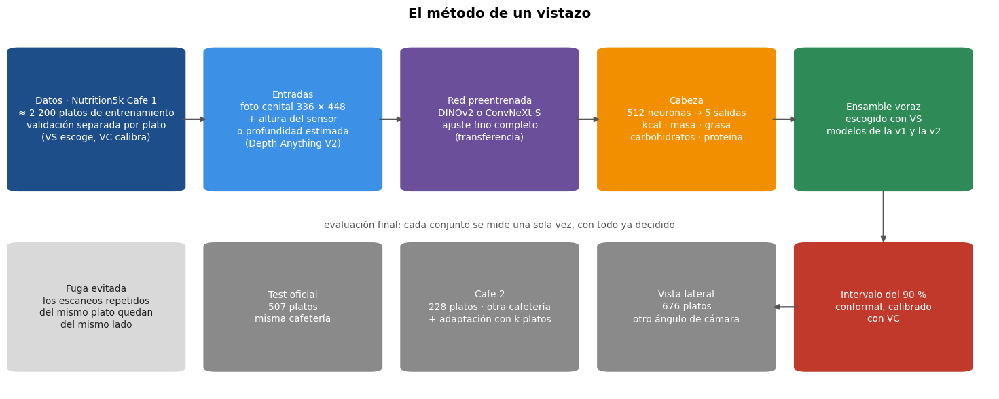

In [13]:
fig, ax = plt.subplots(figsize=(17, 6.4))
ax.axis('off')
y0, h, w = 0.55, 0.38, 0.17
fila1 = [('Datos · Nutrition5k Cafe 1\n≈ 2 200 platos de entrenamiento\nvalidación separada por plato\n(VS escoge, VC calibra)', COL['azul']),
         ('Entradas\nfoto cenital 336 × 448\n+ altura del sensor\no profundidad estimada\n(Depth Anything V2)', COL['celeste']),
         ('Red preentrenada\nDINOv2 o ConvNeXt-S\najuste fino completo\n(transferencia)', COL['morado']),
         ('Cabeza\n512 neuronas → 5 salidas\nkcal · masa · grasa\ncarbohidratos · proteína', COL['naranja']),
         ('Ensamble voraz\nescogido con VS\nmodelos de la v1 y la v2', COL['verde'])]
xs = [0.005 + 0.2 * i for i in range(5)]
for x, (t, c) in zip(xs, fila1):
    caja(ax, x, y0, w, h, t, c)
for x in xs[:-1]:
    flecha(ax, x + w + 0.003, y0 + h / 2, x + 0.2 - 0.003, y0 + h / 2)
caja(ax, xs[4], 0.06, w, 0.34, 'Intervalo del 90 %\nconformal, calibrado\ncon VC', COL['rojo'])
flecha(ax, xs[4] + w / 2, y0 - 0.005, xs[4] + w / 2, 0.40 + 0.005)
for x, (t, c) in zip(xs[1:4], [('Test oficial\n507 platos\nmisma cafetería', COL['gris']),
                               ('Cafe 2\n228 platos · otra cafetería\n+ adaptación con k platos', COL['gris']),
                               ('Vista lateral\n676 platos\notro ángulo de cámara', COL['gris'])]):
    caja(ax, x, 0.06, w, 0.34, t, c)
flecha(ax, xs[4] - 0.003, 0.23, xs[3] + w + 0.003, 0.23)
ax.text(0.5, 0.445, 'evaluación final: cada conjunto se mide una sola vez, con todo ya decidido',
        ha='center', fontsize=9, color='#555555', transform=ax.transAxes)
caja(ax, xs[0], 0.06, w, 0.34, 'Fuga evitada\nlos escaneos repetidos\ndel mismo plato quedan\ndel mismo lado', '#d9d9d9', color_texto='#222222')
ax.set_title('El método de un vistazo', fontsize=13)
guardar_fig(fig, '00_metodo')

## 13. Entorno y datos

In [14]:
with fase('1. Entorno'):
    REPORTE['entorno'] = verificar_entorno()
    for k, v in REPORTE['entorno'].items():
        print(f'{k:>18}: {v}')


1. Entorno   (minuto 0, quedan 660 min)
            python: 3.13.15
             torch: 2.11.0+cu128
              gpus: ['Tesla T4', 'Tesla T4']
              cpus: 4
     carpeta_datos: /tmp/n5k_datos
    disco_libre_gb: 1126.1
            ram_gb: 33.7
              timm: 1.0.29
      transformers: 5.16.1


In [15]:
with fase('2. Metadatos, etiquetas y particiones'):
    PLATOS, Y, INFO_META = preparar_metadatos()
    SOSP = PLATOS.sospechoso.values
    GRUPO = PLATOS.grupo.values
    REPORTE['datos']['metadatos'] = INFO_META
    print('Verificación «total = suma de ingredientes» en la Cafe 1 (diferencia relativa):')
    display(pd.DataFrame(INFO_META['verificacion_suma']).T.round(5))
    print(f"Platos de entrenamiento: {INFO_META['platos_train']} en {INFO_META['cadenas_train']} cadenas "
          f"(la más larga tiene {INFO_META['cadena_max']} escaneos). Cadenas que cruzan train/test oficiales: "
          f"{INFO_META['cadenas_cruzan_train_test']}")
    CON_CENITAL = set(listar_carpetas('nutrition5k_dataset/imagery/realsense_overhead/'))
    PLATOS['cenital_bucket'] = PLATOS.dish_id.isin(CON_CENITAL)
    tab = (PLATOS[PLATOS.grupo != 'XX'].groupby('grupo')
           .agg(platos=('dish_id', 'size'), con_foto_cenital=('cenital_bucket', 'sum'),
                cadenas=('cadena', 'nunique'), etiquetas_imposibles=('sospechoso', 'sum'))
           .reindex(GRUPOS))
    tab.index = [GRUPO_ES[g] for g in tab.index]
    display(tab)
    tab.to_csv(TAB / '01_grupos.csv')
    te_cen = set(PLATOS.dish_id[(PLATOS.grupo == 'TE') & PLATOS.cenital_bucket])
    te_dep = set(PLATOS.dish_id[PLATOS.test_depth])
    print(f'Test cenital: {len(te_cen)} platos; coincide con depth_test_ids.txt: {te_cen == te_dep}')
    REPORTE['datos']['test_cenital_igual_a_depth_test'] = te_cen == te_dep


2. Metadatos, etiquetas y particiones   (minuto 0, quedan 660 min)
Verificación «total = suma de ingredientes» en la Cafe 1 (diferencia relativa):


,mediana_dif_rel,p99_dif_rel
kcal,0.0,0.00000
masa,0.0,0.02655
grasa,0.0,0.00000
carb,0.0,0.00000
prot,0.0,0.00000


Platos de entrenamiento: 4059 en 2326 cadenas (la más larga tiene 8 escaneos). Cadenas que cruzan train/test oficiales: 2


,platos,con_foto_cenital,cadenas,etiquetas_imposibles
Entrenamiento,3246,2214,1848,7
Validación (selección),420,277,239,1
Validación (calibración),393,264,239,0
Test oficial,709,507,409,2
Cafe 2 (externa),238,228,139,0


Test cenital: 507 platos; coincide con depth_test_ids.txt: True


### Cómo son las etiquetas

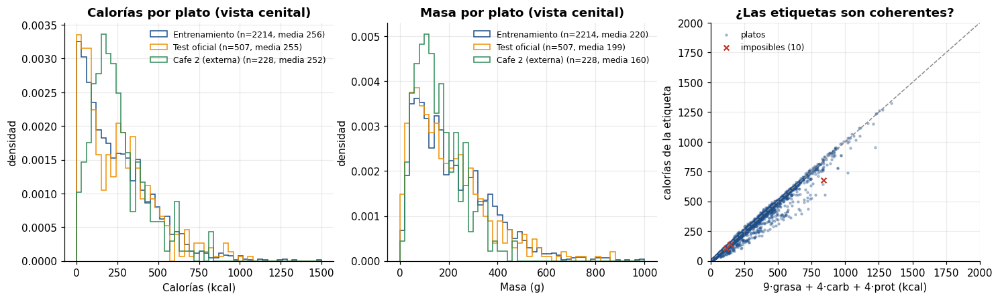

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, j, lim in [(axs[0], 0, 1500), (axs[1], 1, 1000)]:
    for g, c in [('TR', COL['azul']), ('TE', COL['naranja']), ('C2', COL['verde'])]:
        v = Y[(GRUPO == g) & PLATOS.cenital_bucket.values, j]
        ax.hist(np.clip(v, 0, lim), bins=50, range=(0, lim), density=True, histtype='step', lw=2, color=c,
                label=f'{GRUPO_ES[g]} (n={len(v)}, media {v.mean():.0f})')
    ax.set_xlabel(f'{OBJ_ES[j]} ({UNID[j]})'); ax.set_ylabel('densidad'); ax.legend(fontsize=8)
    ax.set_title(f'{OBJ_ES[j]} por plato (vista cenital)')
atw = 9 * Y[:, 2] + 4 * Y[:, 3] + 4 * Y[:, 4]                   # factores de Atwater
ok = GRUPO != 'XX'
axs[2].scatter(atw[ok & ~SOSP], Y[ok & ~SOSP, 0], s=4, alpha=0.3, color=COL['azul'], label='platos')
axs[2].scatter(atw[ok & SOSP], Y[ok & SOSP, 0], s=25, color=COL['rojo'], marker='x', label=f'imposibles ({(ok & SOSP).sum()})')
axs[2].plot([0, 2000], [0, 2000], color=COL['gris'], ls='--', lw=1)
axs[2].set_xlim(0, 2000); axs[2].set_ylim(0, 2000)
axs[2].set_xlabel('9·grasa + 4·carb + 4·prot (kcal)'); axs[2].set_ylabel('calorías de la etiqueta')
axs[2].set_title('¿Las etiquetas son coherentes?'); axs[2].legend(fontsize=8)
guardar_fig(fig, '01_etiquetas')

**Lectura:** las calorías y la masa están muy sesgadas a la derecha: hay muchos platos pequeños (de un solo ingrediente, por los escaneos incrementales) y pocos de más de 800 kcal. Entrenamiento y test tienen casi la misma media (256 y 255 kcal). La Cafe 2 tiene una media de calorías parecida (252 kcal) pero **mucha menos masa** (160 g frente a 220 g), o sea, comida más densa: huevos, tocino y papas en vez de ensaladas. A la derecha, casi todas las etiquetas cumplen la regla de Atwater (9 kcal por gramo de grasa y 4 por gramo de carbohidrato o proteína). Las que quedan por debajo de la diagonal suelen tener fibra o alcohol. Solo 10 platos son físicamente imposibles.

### Cafe 1 contra Cafe 2

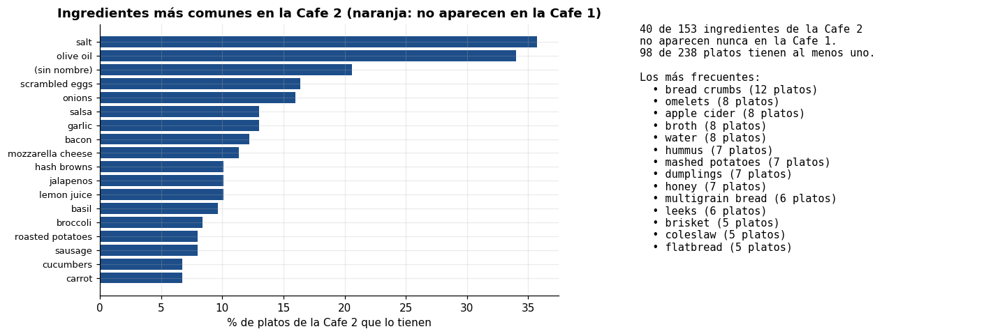

In [17]:
ing1 = Counter(n for l in PLATOS.ingredientes[PLATOS.cafe == 1] for n in set(l))
ing2 = Counter(n for l in PLATOS.ingredientes[PLATOS.cafe == 2] for n in set(l))
nuevos = {n: c for n, c in ing2.items() if n not in ing1}
PLATOS['ingr_nuevo'] = [any(n not in ing1 for n in l) if c == 2 else False for l, c in zip(PLATOS.ingredientes, PLATOS.cafe)]
REPORTE['datos']['cafe2'] = dict(ingredientes=len(ing2), ingredientes_nuevos=len(nuevos),
                                 platos_con_ingrediente_nuevo=int(PLATOS.ingr_nuevo.sum()))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.3, 1]})
top = ing2.most_common(18)
y_ = np.arange(len(top))[::-1]
axs[0].barh(y_, [c / (PLATOS.cafe == 2).sum() * 100 for _, c in top],
            color=[COL['naranja'] if n in nuevos else COL['azul'] for n, _ in top])
axs[0].set_yticks(y_); axs[0].set_yticklabels([n for n, _ in top], fontsize=8.5)
axs[0].set_xlabel('% de platos de la Cafe 2 que lo tienen')
axs[0].set_title('Ingredientes más comunes en la Cafe 2 (naranja: no aparecen en la Cafe 1)')
nuevos_top = sorted(nuevos.items(), key=lambda x: -x[1])[:14]
axs[1].axis('off')
axs[1].text(0, 1, f'{len(nuevos)} de {len(ing2)} ingredientes de la Cafe 2\nno aparecen nunca en la Cafe 1.\n'
            f'{int(PLATOS.ingr_nuevo.sum())} de {(PLATOS.cafe == 2).sum()} platos tienen al menos uno.\n\n'
            'Los más frecuentes:\n' + '\n'.join(f'  • {n} ({c} platos)' for n, c in nuevos_top),
            va='top', fontsize=10, family='monospace')
guardar_fig(fig, '02_cafe2')

**Lectura:** la Cafe 2 sirve sobre todo desayunos (huevos revueltos, tocino, *hash browns*, salsa). 40 de sus 153 ingredientes no aparecen nunca en la Cafe 1, y 98 de sus 238 platos tienen al menos uno de ellos. Uno de cada cinco platos trae un ingrediente sin nombre en los metadatos, pero sí con sus valores nutricionales, así que la etiqueta del plato sigue siendo válida. Es un cambio de dominio real: otro menú, otra vajilla y otra luz.

### Fotos cenitales y profundidad del sensor

In [18]:
with fase('3. Fotos cenitales y profundidad'):
    ids_cen = list(PLATOS.dish_id[PLATOS.cenital_bucket & PLATOS.grupo.isin(GRUPOS)])
    t = time.time()
    CEN = cargar_cenitales(ids_cen)
    falt = len(ids_cen) - len(CEN)
    print(f'{len(CEN)} de {len(ids_cen)} platos cenitales en {(time.time() - t) / 60:.1f} min ({falt} fallaron)')
    if falt > 0.03 * len(ids_cen):
        raise RuntimeError(f'Fallaron {falt} descargas cenitales: revisar la conexión al bucket de Google.')
    pos = {d: i for i, d in enumerate(PLATOS.dish_id)}
    orden = [d for d in ids_cen if d in CEN]
    CEN_PLATO = np.array([pos[d] for d in orden])
    CEN_RGB = np.stack([CEN[d][0] for d in orden])
    CEN_ALT = np.stack([CEN[d][1] for d in orden])
    CEN_VOL = np.stack([CEN[d][2] for d in orden])
    CEN_MM = np.array([CEN[d][3] for d in orden])
    del CEN; gc.collect()
    CEN_EST = None                                   # se llena en la fase 4 (profundidad estimada)
    Y_CEN = Y[CEN_PLATO]
    SOSP_CEN = SOSP[CEN_PLATO]
    GRUPO_CEN = GRUPO[CEN_PLATO]
    PLATOS['cenital'] = False
    PLATOS.loc[CEN_PLATO, 'cenital'] = True
    REPORTE['datos']['cenital'] = {g: int((GRUPO_CEN == g).sum()) for g in GRUPOS}
    REPORTE['datos']['profundidad_en_mm'] = int(CEN_MM.sum())
    print('Platos cenitales por grupo:', REPORTE['datos']['cenital'])
    print(f'Mapas de profundidad que venían en mm (y se corrigieron): {CEN_MM.sum()}')
    # Medias de entrenamiento (normalizan la pérdida y fijan el punto de partida de la cabeza)
    tr_ok = (GRUPO == 'TR') & ~SOSP
    MEDIAS = Y[tr_ok].mean(0).astype(np.float32)
    DENS_MEDIA = (Y[tr_ok][:, [0, 2, 3, 4]].sum(0) / Y[tr_ok][:, 1].sum()).astype(np.float32)
    # Rasgos de volumen: media y desviación del entrenamiento (con el mismo cálculo que usa el modelo)
    fil_tr = np.flatnonzero(GRUPO_CEN == 'TR')
    rc = torch.cat([rasgos_crudos(torch.from_numpy(CEN_ALT[fil_tr[k:k + 256]]).float()) for k in range(0, len(fil_tr), 256)])
    VOL_MU, VOL_SD = rc.mean(0).numpy(), (rc.std(0) + 1e-6).numpy()
    print('Medias de entrenamiento:', dict(zip(OBJ, MEDIAS.round(1))), '| por gramo:', DENS_MEDIA.round(3))


3. Fotos cenitales y profundidad   (minuto 0, quedan 660 min)
  500/3490 platos cenitales (0.3 min)
  1000/3490 platos cenitales (0.5 min)
  1500/3490 platos cenitales (0.7 min)
  2000/3490 platos cenitales (0.9 min)
  2500/3490 platos cenitales (1.2 min)
  3000/3490 platos cenitales (1.4 min)
3489 de 3490 platos cenitales en 1.7 min (1 fallaron)
Platos cenitales por grupo: {'TR': 2213, 'VS': 277, 'VC': 264, 'TE': 507, 'C2': 228}
Mapas de profundidad que venían en mm (y se corrigieron): 4
Medias de entrenamiento: {'kcal': np.float32(214.8), 'masa': np.float32(185.3), 'grasa': np.float32(10.6), 'carb': np.float32(17.0), 'prot': np.float32(14.8)} | por gramo: [1.16  0.057 0.092 0.08 ]


### ¿Por qué la profundidad falla en la Cafe 2?

Si el sensor midiera igual en las dos cafeterías, la relación entre el volumen medido y la masa real debería ser la misma. A la izquierda se compara esa relación; a la derecha, la densidad calórica de los platos.

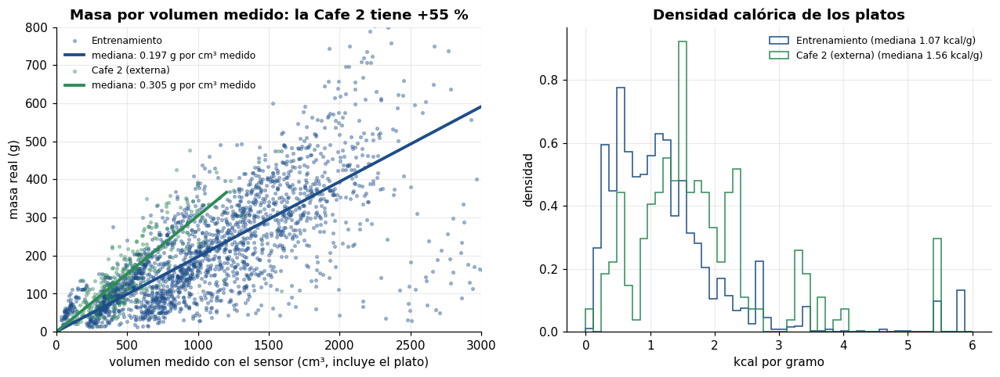

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
ratios = {}
for g, c in [('TR', COL['azul']), ('C2', COL['verde'])]:
    m = (GRUPO_CEN == g) & ~SOSP_CEN & (CEN_VOL[:, 0] > 20) & (Y_CEN[:, 1] > 10)
    axs[0].scatter(CEN_VOL[m, 0], Y_CEN[m, 1], s=6, alpha=0.35, color=c, label=GRUPO_ES[g])
    ratios[g] = float(np.median(Y_CEN[m, 1] / CEN_VOL[m, 0]))
    xs = np.linspace(0, np.percentile(CEN_VOL[m, 0], 98), 50)
    axs[0].plot(xs, ratios[g] * xs, color=c, lw=2.5, label=f'mediana: {ratios[g]:.3f} g por cm³ medido')
    d = Y_CEN[m, 0] / np.maximum(Y_CEN[m, 1], 1)
    axs[1].hist(np.clip(d, 0, 6), bins=50, range=(0, 6), density=True, histtype='step', lw=2, color=c,
                label=f'{GRUPO_ES[g]} (mediana {np.median(d):.2f} kcal/g)')
REPORTE['datos']['g_por_cm3'] = ratios
axs[0].set_xlabel('volumen medido con el sensor (cm³, incluye el plato)'); axs[0].set_ylabel('masa real (g)')
axs[0].set_xlim(0, 3000); axs[0].set_ylim(0, 800); axs[0].legend(fontsize=8)
axs[0].set_title(f'Masa por volumen medido: la Cafe 2 tiene {100 * (ratios["C2"] / ratios["TR"] - 1):+.0f} %')
axs[1].set_xlabel('kcal por gramo'); axs[1].set_ylabel('densidad'); axs[1].legend(fontsize=8)
axs[1].set_title('Densidad calórica de los platos')
guardar_fig(fig, '03_volumen_cafes')

**Lectura:** la masa por volumen medido es muy distinta entre las dos cafeterías: la mediana es de 0,197 g por cm³ en el entrenamiento y de 0,305 g por cm³ en la Cafe 2, un 55 % más. Su comida es además más densa en calorías (mediana de 1,56 kcal/g frente a 1,07). Un modelo que aprendió la relación de la Cafe 1 entre volumen y masa convierte el mismo volumen en menos gramos de los que hay, que es la dirección del sesgo observado con el sensor (subestima la masa de la Cafe 2).

## 14. Profundidad estimada con Depth Anything V2

In [20]:
with fase('4. Profundidad estimada (Depth Anything V2)', opcional=True):
    t = time.time()
    CEN_EST = estimar_profundidad(CEN_RGB, DEV)
    print(f'{len(CEN_EST)} mapas estimados en {(time.time() - t) / 60:.1f} min ({CEN_EST.nbytes / 1e9:.2f} GB)')
if CEN_EST is None:
    ACTIVO['estimada'] = False


4. Profundidad estimada (Depth Anything V2)   (minuto 2, quedan 658 min)


config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

3489 mapas estimados en 1.1 min (0.53 GB)


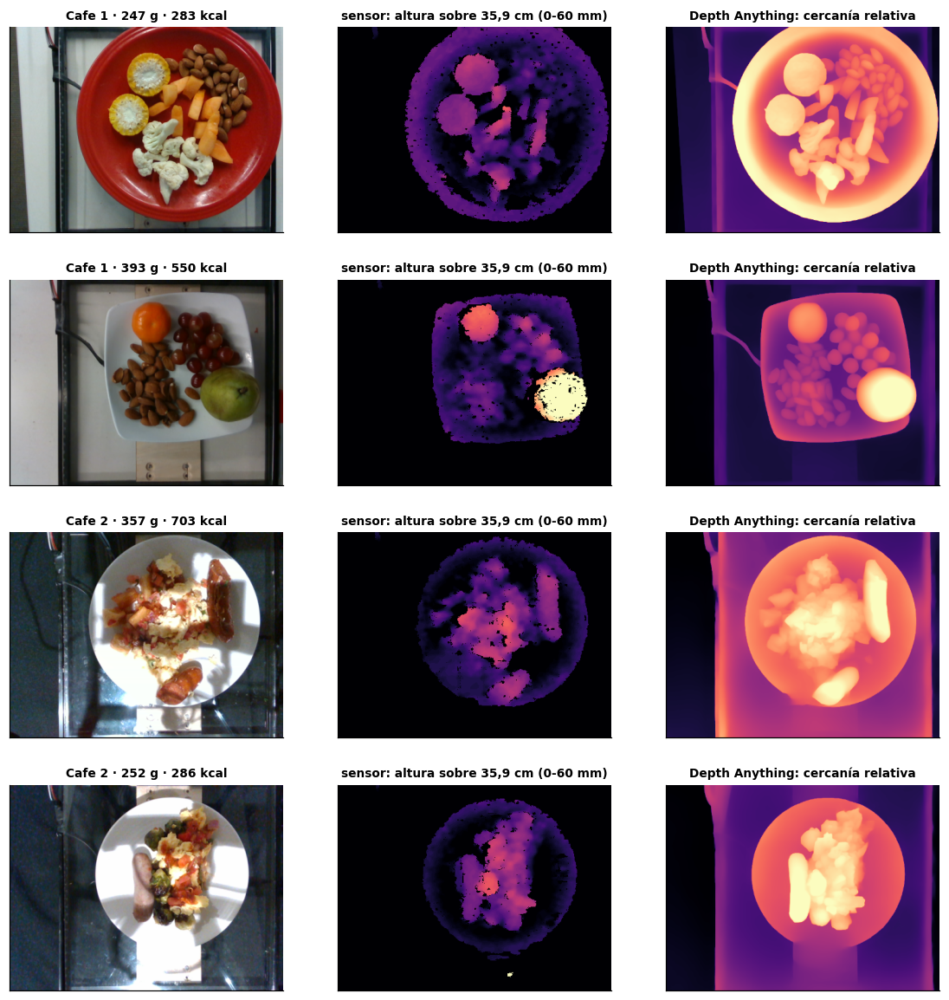

In [21]:
# El mismo plato visto por el sensor y por la red de profundidad (2 platos de cada cafetería)
rng_ej = np.random.default_rng(5)
sel = [*rng_ej.choice(np.flatnonzero((GRUPO_CEN == 'TE') & (Y_CEN[:, 1] > 150)), 2, replace=False),
       *rng_ej.choice(np.flatnonzero((GRUPO_CEN == 'C2') & (Y_CEN[:, 1] > 150)), 2, replace=False)]
ncol = 3 if CEN_EST is not None else 2
fig, axs = plt.subplots(len(sel), ncol, figsize=(4.2 * ncol, 3.3 * len(sel)))
for i, c in enumerate(sel):
    axs[i, 0].imshow(CEN_RGB[c].transpose(1, 2, 0))
    axs[i, 0].set_title(f'{"Cafe 2" if GRUPO_CEN[c] == "C2" else "Cafe 1"} · {Y_CEN[c, 1]:.0f} g · {Y_CEN[c, 0]:.0f} kcal', fontsize=9)
    axs[i, 1].imshow(CEN_ALT[c, 0], cmap='magma', vmin=0, vmax=60)
    axs[i, 1].set_title('sensor: altura sobre 35,9 cm (0-60 mm)', fontsize=9)
    if CEN_EST is not None:
        axs[i, 2].imshow(CEN_EST[c, 0], cmap='magma', vmin=0, vmax=255)
        axs[i, 2].set_title('Depth Anything: cercanía relativa', fontsize=9)
for a in axs.ravel():
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
guardar_fig(fig, '04_profundidades')

**Lectura:** el sensor entrega la altura en milímetros y deja el plato casi en negro, mientras que Depth Anything entrega una profundidad relativa, sin escala en milímetros, que además resalta el plato y la mesa. En las filas de la Cafe 2 el plato es blanco, plano y de otro tamaño que los de la Cafe 1, y los montones de comida (huevos, tocino) se distinguen en ambos mapas.

### Fotogramas laterales

In [22]:
with fase('5. Fotogramas laterales', opcional=True):
    RAIZ_LAT = obtener_lateral()
    if RAIZ_LAT is None:
        raise RuntimeError('No se encontró el dataset lateral: agrégalo con Add Input → '
                           'zygmuntyt/nutrition5k-dataset-side-angle-images')
    print('Dataset lateral en:', RAIZ_LAT)
    ids_lat = list(PLATOS.dish_id[PLATOS.grupo.isin(GRUPOS)])
    t = time.time()
    LAT_BUF, LAT_OFF, _lp, LAT_CAM, LAT_NUM, _ld = cachear_laterales(RAIZ_LAT, ids_lat)
    pos = {d: i for i, d in enumerate(PLATOS.dish_id)}
    LAT_PLATO = np.array([pos[d] for d in _lp])
    LAT_OK = _ld >= 12                                       # fuera los fotogramas casi uniformes
    print(f'{len(LAT_OFF) - 1} fotogramas de {len(set(_lp))} platos en {(time.time() - t) / 60:.1f} min '
          f'({LAT_BUF.nbytes / 1e9:.2f} GB); descartados por vacíos: {(~LAT_OK).sum()}')
    PLATOS['lateral'] = False
    PLATOS.loc[np.unique(LAT_PLATO[LAT_OK]), 'lateral'] = True
    REPORTE['datos']['lateral'] = {g: int(((GRUPO == g) & PLATOS.lateral.values).sum()) for g in GRUPOS}
    print('Platos laterales por grupo:', REPORTE['datos']['lateral'])
if 'LAT_OK' not in globals():
    ACTIVO['lateral'] = ACTIVO['conjunto'] = False
    PLATOS['lateral'] = False


5. Fotogramas laterales   (minuto 3, quedan 657 min)
Dataset lateral en: /kaggle/input/datasets/zygmuntyt/nutrition5k-dataset-side-angle-images
  1000/4793 platos laterales (14.3 min)
  2000/4793 platos laterales (27.7 min)
  3000/4793 platos laterales (42.6 min)
  4000/4793 platos laterales (56.1 min)
54845 fotogramas de 4793 platos en 71.5 min (1.32 GB); descartados por vacíos: 37
Platos laterales por grupo: {'TR': 3149, 'VS': 397, 'VC': 384, 'TE': 676, 'C2': 187}


In [23]:
with fase('6. Fuentes de datos'):
    FUENTES = {'cenital': FuenteCenital({g: np.flatnonzero(GRUPO_CEN == g) for g in GRUPOS})}
    if ACTIVO['lateral']:
        filas_lat = {g: np.flatnonzero((GRUPO[LAT_PLATO] == g) & LAT_OK) for g in GRUPOS}
        rap = {}
        for g, idx in filas_lat.items():                      # validación rápida: el fotograma 3 de cada cámara
            sel = idx[LAT_NUM[idx] == 3]
            rap[g] = sel if len(sel) else idx
        FUENTES['lateral'] = FuenteLateral(filas_lat, rap)
        print({g: len(v) for g, v in filas_lat.items()}, 'fotogramas por grupo')


6. Fuentes de datos   (minuto 75, quedan 585 min)
{'TR': 36715, 'VS': 4665, 'VC': 4354, 'TE': 7616, 'C2': 1458} fotogramas por grupo


### Ejemplos: el mismo plato desde arriba, en altura y de lado

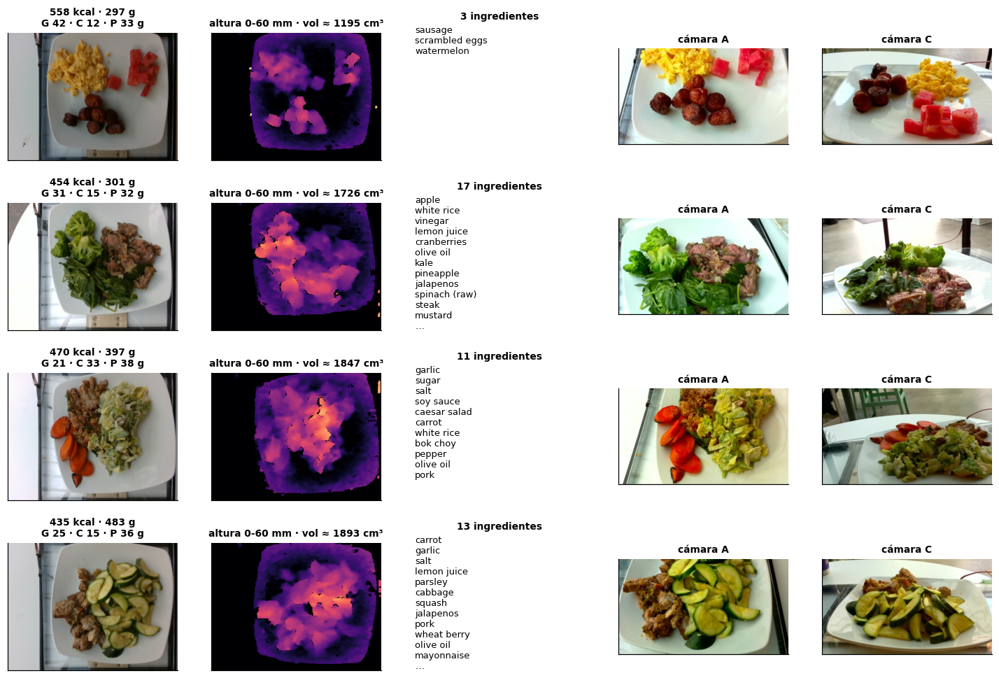

In [24]:
rng_ej = np.random.default_rng(3)
cand = np.flatnonzero((GRUPO_CEN == 'TR') & ~SOSP_CEN & (Y_CEN[:, 0] > 150))
if ACTIVO['lateral']:
    cand = np.array([c for c in cand if PLATOS.lateral.iat[CEN_PLATO[c]]])
ej = rng_ej.choice(cand, 4, replace=False)
ncol = 3 + (2 if ACTIVO['lateral'] else 0)
fig, axs = plt.subplots(4, ncol, figsize=(3.3 * ncol, 11))
for i, c in enumerate(ej):
    p = CEN_PLATO[c]
    axs[i, 0].imshow(CEN_RGB[c].transpose(1, 2, 0))
    axs[i, 0].set_title(f'{Y[p, 0]:.0f} kcal · {Y[p, 1]:.0f} g\nG {Y[p, 2]:.0f} · C {Y[p, 3]:.0f} · P {Y[p, 4]:.0f} g', fontsize=9)
    axs[i, 1].imshow(CEN_ALT[c, 0], cmap='magma', vmin=0, vmax=60)
    axs[i, 1].set_title(f'altura 0-60 mm · vol ≈ {CEN_VOL[c, 0]:.0f} cm³', fontsize=9)
    ingr = PLATOS.ingredientes.iat[p]
    axs[i, 2].axis('off')
    axs[i, 2].text(0, 1, '\n'.join(ingr[:12]) + ('\n…' if len(ingr) > 12 else ''), va='top', fontsize=8.5)
    axs[i, 2].set_title(f'{len(ingr)} ingredientes', fontsize=9)
    if ACTIVO['lateral']:
        fr = np.flatnonzero((LAT_PLATO == p) & LAT_OK)
        for k, cam in enumerate((0, 2)):
            sel = [f for f in fr if LAT_CAM[f] == cam]
            if sel:
                axs[i, 3 + k].imshow(decodificar(sel[len(sel) // 2]))
                axs[i, 3 + k].set_title(f'cámara {CAMARAS[cam]}', fontsize=9)
for a in axs.ravel():
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
guardar_fig(fig, '05_ejemplos')

**Lectura:** en el mapa de altura se distinguen bien los montones de comida (carne, arroz) del plato, que queda casi en negro. Pero un plato de 450 kcal puede tener 17 ingredientes, entre ellos aceite, vinagre y mostaza, que no se ven ni en la foto ni en la altura. Las vistas laterales muestran la comida tapada por otra, a cambio de la perspectiva: lo que está cerca de la cámara se ve más grande.

### Escaneos incrementales: por qué la validación se separa por cadenas

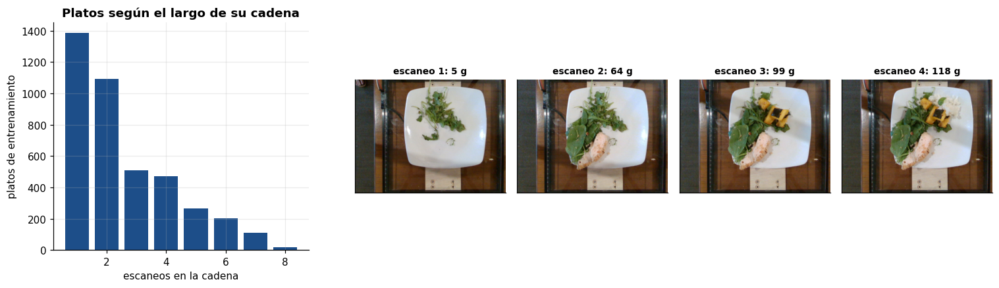

In [25]:
largos = Counter(Counter(PLATOS.cadena[PLATOS.split == 'train']).values())
cad_ej = [c for c, n in Counter(PLATOS.cadena[PLATOS.cenital]).items() if n >= 4]
fig = plt.figure(figsize=(16, 4.2))
ax0 = fig.add_axes([0.04, 0.12, 0.22, 0.75])
ks = sorted(largos)
ax0.bar(ks, [largos[k] * k for k in ks], color=COL['azul'])
ax0.set_xlabel('escaneos en la cadena'); ax0.set_ylabel('platos de entrenamiento')
ax0.set_title('Platos según el largo de su cadena')
if cad_ej:
    c = cad_ej[len(cad_ej) // 2]
    miembros = sorted([i for i in np.flatnonzero(PLATOS.cadena.values == c) if PLATOS.cenital.iat[i]],
                      key=lambda i: int(PLATOS.dish_id.iat[i].split('_')[1]))[:5]      # en orden de escaneo
    fila_cen = {p: i for i, p in enumerate(CEN_PLATO)}
    for k, p in enumerate(miembros):
        ax = fig.add_axes([0.30 + k * 0.14, 0.12, 0.13, 0.75])
        ax.imshow(CEN_RGB[fila_cen[p]].transpose(1, 2, 0)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f'escaneo {k + 1}: {Y[p, 1]:.0f} g', fontsize=9)
guardar_fig(fig, '06_cadenas')

**Lectura:** solo unos 1 400 de los 4 059 platos de entrenamiento son escaneos únicos; el resto pertenece a cadenas de 2 a 8 fotos del mismo plato (a la derecha, el mismo plato pasa de 5 a 118 g). Si la validación se separara al azar, el modelo vería en entrenamiento casi la misma foto que luego valida, y el error de validación saldría optimista. Separar por cadenas evita esa fuga.

### El aumento de datos sobre un plato

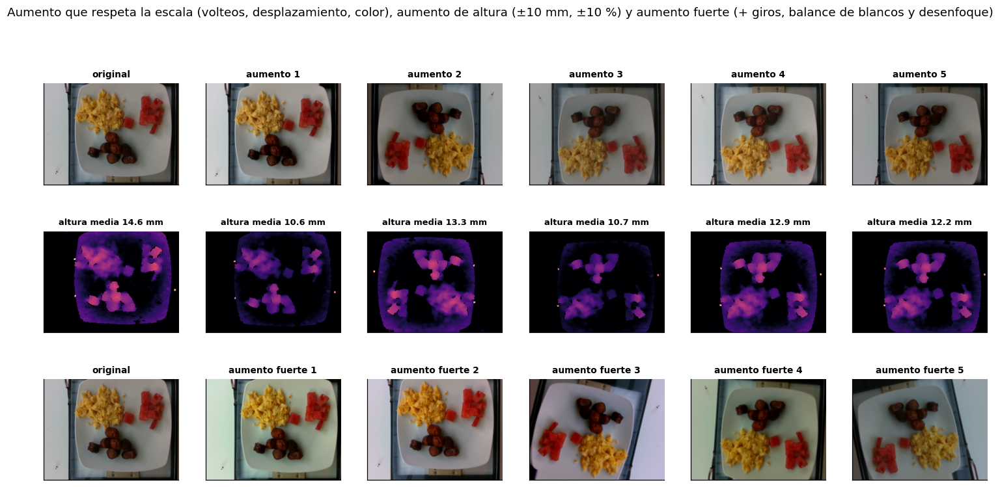

In [26]:
c = ej[0]
fuente = FUENTES['cenital']
rgb, alt, _, _ = fuente.tomar(np.array([c] * 6), DEV, 'alt')
g_ = torch.Generator(device=DEV); g_.manual_seed(0)
ra, aa = aumentar(rgb, alt, 'completo', 'cenital', g_, aum_altura=True)
rf, _ = aumentar(rgb, None, 'fuerte', 'cenital', g_)
fig, axs = plt.subplots(3, 6, figsize=(17, 7.6))
for k in range(6):
    axs[0, k].imshow((rgb if k == 0 else ra)[k].permute(1, 2, 0).cpu().numpy())
    a = (alt if k == 0 else aa)[k, 0].cpu().numpy()
    axs[1, k].imshow(a, cmap='magma', vmin=0, vmax=60)
    axs[2, k].imshow((rgb if k == 0 else rf)[k].permute(1, 2, 0).cpu().numpy())
    axs[0, k].set_title('original' if k == 0 else f'aumento {k}', fontsize=9)
    axs[1, k].set_title(f'altura media {a[a > 3].mean():.1f} mm' if (a > 3).any() else '', fontsize=8.5)
    axs[2, k].set_title('original' if k == 0 else f'aumento fuerte {k}', fontsize=9)
for a in axs.ravel():
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.suptitle('Aumento que respeta la escala (volteos, desplazamiento, color), aumento de altura (±10 mm, ±10 %) '
             'y aumento fuerte (+ giros, balance de blancos y desenfoque)', y=1.0)
guardar_fig(fig, '07_aumento')

**Lectura:** la comida nunca cambia de tamaño: solo se voltea, se mueve un poco y cambia levemente de color, porque el tamaño aparente es la información de la porción. En la fila del medio, la altura media del plato cambia de un aumento a otro: es el aumento de altura, que obliga al modelo a no depender de un valor exacto del sensor. La fila de abajo es el aumento fuerte de la variante: además gira la foto hasta 15°, cambia el balance de blancos y a veces la desenfoca, pero tampoco cambia el tamaño de la comida.

## 15. Métrica oficial y la línea base más simple

Predecir siempre la media del entrenamiento es lo que logra un modelo que no mira la foto. Se calcula con la función propia y con el script oficial; deben coincidir. Los autores no publicaron pesos, así que su modelo no se puede reproducir tal cual. Lo más cercano es el paso «como el paper» de la ablación de la corrida previa.

In [27]:
with fase('7. Métrica oficial y predictor de la media'):
    TAB_BASE = []
    for g in ('TE', 'C2'):
        fil = FUENTES['cenital'].indices(g)
        ids = PLATOS.dish_id.values[CEN_PLATO[fil]]
        p_media = np.tile(Y[(GRUPO == 'TR')].mean(0), (len(fil), 1))
        of, dif = evaluar_oficial(ids, Y_CEN[fil], p_media, f'media_{g}')
        print(f'{GRUPO_ES[g]}: diferencia máxima con el script oficial = {dif:.2e}')
        assert dif < 1e-3, 'La métrica no coincide con el script oficial'
        TAB_BASE.append(tabla_metricas(f'Predecir la media · {GRUPO_ES[g]}', Y_CEN[fil], p_media))
    REPORTE['metrica_oficial_verificada'] = True
    display(pd.DataFrame(TAB_BASE).set_index('modelo')[[f'PMAE_{o}' for o in OBJ] + [f'MAE_{o}' for o in OBJ]].round(1))
    print('Paper (línea base, Tabla 3):', dict(zip(OBJ, PAPER_BASELINE['pmae'])))


7. Métrica oficial y predictor de la media   (minuto 75, quedan 585 min)
Test oficial: diferencia máxima con el script oficial = 2.13e-13
Cafe 2 (externa): diferencia máxima con el script oficial = 4.97e-14


,PMAE_kcal,PMAE_masa,PMAE_grasa,PMAE_carb,PMAE_prot,MAE_kcal,MAE_masa,MAE_grasa,MAE_carb,MAE_prot
modelo,,,,,,,,,,
Predecir la media · Test oficial,65.4,58.9,80.3,68.8,83.1,167.1,116.8,10.3,13.5,14.5
Predecir la media · Cafe 2 (externa),49.6,53.8,62.1,76.0,62.6,125.2,86.3,8.9,12.2,9.3


Paper (línea base, Tabla 3): {'kcal': 60.2, 'masa': 58.5, 'grasa': 67.6, 'carb': 62.1, 'prot': 62.1}


**Lectura:** sin mirar la foto, el error en calorías es 65 % en el test y 50 % en la Cafe 2. El paper reporta 60 % para su línea base, pero no explica con qué conjunto la calculó, así que no se puede reproducir exacto. Estas cifras son el piso: cualquier modelo útil debe estar muy por debajo.

## 16. Punto de partida: los resultados de la v1

In [28]:
V1R = None
with fase('8. Predicciones de la v1', opcional=True):
    carpeta_v1 = buscar_v1()
    if carpeta_v1 is None:
        raise RuntimeError('No se encontró el dataset calorias-v1-outputs (Add Input → Your Datasets)')
    runs_v1, V1R, dif_v1 = cargar_v1(carpeta_v1)
    RES.update(runs_v1)
    print(f'{len(runs_v1)} modelos de la v1 cargados desde {carpeta_v1}; '
          f'el ensamble recalculado coincide con el reportado (diferencia {dif_v1:.1e} puntos)')
if V1R is None:
    ACTIVO['v1'] = False
REC_V1 = (V1R or {}).get('decisiones') or {'cabeza': 'directa', 'limpiar': True}
RECETA = dict(cabeza=REC_V1.get('cabeza', 'directa'), perdida_='pmae', aug='completo', ema=True,
              limpiar=bool(REC_V1.get('limpiar', True)))
print('Receta base (decidida en la v1):', RECETA)


8. Predicciones de la v1   (minuto 75, quedan 585 min)
29 modelos de la v1 cargados desde /kaggle/input/datasets/matimart/calorias-v1-outputs/outputs/predicciones; el ensamble recalculado coincide con el reportado (diferencia 0.0e+00 puntos)
Receta base (decidida en la v1): {'cabeza': 'directa', 'perdida_': 'pmae', 'aug': 'completo', 'ema': True, 'limpiar': True}


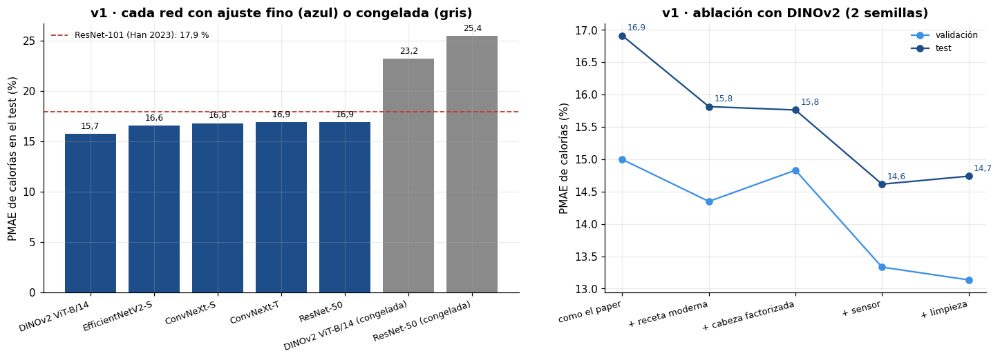

In [29]:
if V1R is not None:
    tb, tc = pd.DataFrame(V1R.get('tab_b', [])), pd.DataFrame(V1R.get('tab_c', []))
    fig, axs = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
    if len(tb):
        tb = tb.sort_values('test_kcal')
        cols = [COL['gris'] if 'congelada' in r else COL['azul'] for r in tb.red]
        b = axs[0].bar(np.arange(len(tb)), tb.test_kcal, color=cols)
        etiquetar_barras(axs[0], b, size=8)
        axs[0].set_xticks(np.arange(len(tb))); axs[0].set_xticklabels(tb.red, rotation=20, ha='right', fontsize=8.5)
        axs[0].axhline(17.9, color=COL['rojo'], ls='--', lw=1.2, label='ResNet-101 (Han 2023): 17,9 %')
        axs[0].set_ylabel('PMAE de calorías en el test (%)'); axs[0].legend(fontsize=8)
        axs[0].set_title('v1 · cada red con ajuste fino (azul) o congelada (gris)')
    if len(tc):
        m = tc.groupby('paso')[['val_kcal', 'test_kcal']].mean()
        etq = {'L0': 'como el paper', 'L1': '+ receta moderna', 'L2': '+ cabeza factorizada',
               'L3': '+ sensor', 'L4': '+ limpieza'}
        x = np.arange(len(m))
        axs[1].plot(x, m.val_kcal, '-o', color=COL['celeste'], label='validación')
        axs[1].plot(x, m.test_kcal, '-o', color=COL['azul'], label='test')
        for i, (v1_, v2_) in enumerate(zip(m.val_kcal, m.test_kcal)):
            axs[1].annotate(coma(v2_), (i, v2_), textcoords='offset points', xytext=(5, 5), fontsize=8, color=COL['azul'])
        axs[1].set_xticks(x); axs[1].set_xticklabels([etq.get(p, p) for p in m.index], rotation=15, ha='right', fontsize=8.5)
        axs[1].set_ylabel('PMAE de calorías (%)'); axs[1].legend(fontsize=8)
        axs[1].set_title('v1 · ablación con DINOv2 (2 semillas)')
    guardar_fig(fig, '08_v1_resumen')

**Lectura:** en la corrida previa, **ajustar la red completa fue indispensable**: DINOv2 congelada se queda en 23 % y con ajuste fino baja a 15,7 %; ResNet-50, de 25 a 17 %. DINOv2, preentrenada sin etiquetas con 142 millones de imágenes, fue la mejor de las cinco redes. En la ablación, lo que más bajó el error fue la receta moderna (de 16,9 a 15,8 %) y el sensor de profundidad (a 14,6 %). La cabeza factorizada no ayudó y la limpieza de etiquetas casi no cambió nada. Por eso este notebook se concentra en la profundidad y en entrenar más tiempo.

### Diagnóstico: sesgo de masa de cada modelo de la corrida previa

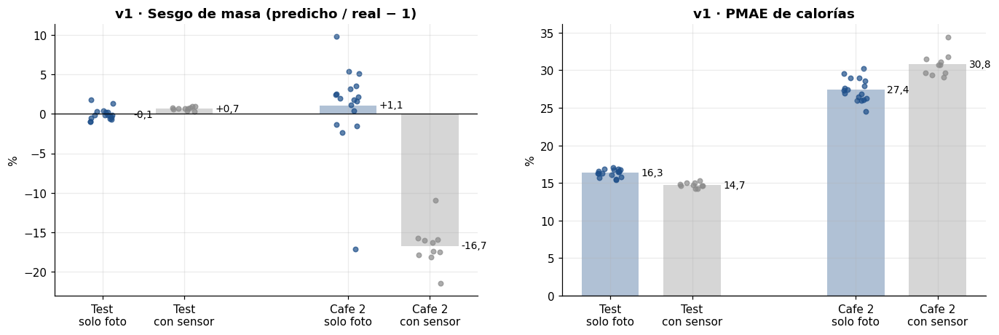

In [30]:
if V1R is not None:
    filas = []
    for n, r in RES.items():
        if not r.get('v1') or r['t'].get('fuentes') == ['lateral']:
            continue
        for g in ('TE', 'C2'):
            y, p = y_conjunto('cenital', g), r['pred'][('cenital', g)]
            filas.append(dict(modelo=n, tipo='Con sensor' if r['t']['prof'] else 'Solo foto', conjunto=g,
                              sesgo_masa=100 * (p[:, 1].sum() / y[:, 1].sum() - 1), pmae_kcal=pmae(y, p)[0]))
    SESGO_V1 = pd.DataFrame(filas)
    SESGO_V1.to_csv(TAB / '02_v1_sesgo_masa.csv', index=False)
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.4))
    for ax, col, tit in [(axs[0], 'sesgo_masa', 'Sesgo de masa (predicho / real − 1)'), (axs[1], 'pmae_kcal', 'PMAE de calorías')]:
        for k, (tipo, c) in enumerate([('Solo foto', COL['azul']), ('Con sensor', COL['gris'])]):
            for j, g in enumerate(('TE', 'C2')):
                v = SESGO_V1[(SESGO_V1.tipo == tipo) & (SESGO_V1.conjunto == g)][col]
                xpos = j * 3 + k
                ax.scatter(np.full(len(v), xpos) + np.random.default_rng(0).uniform(-0.15, 0.15, len(v)), v, color=c, s=18, alpha=0.7)
                ax.bar(xpos, v.mean(), color=c, alpha=0.35, width=0.7)
                ax.text(xpos + 0.38, v.mean(), (f'{v.mean():+.1f}' if col == 'sesgo_masa' else f'{v.mean():.1f}').replace('.', ','),
                        fontsize=9, va='center')
        ax.set_xticks([0, 1, 3, 4]); ax.set_xticklabels(['Test\nsolo foto', 'Test\ncon sensor', 'Cafe 2\nsolo foto', 'Cafe 2\ncon sensor'])
        ax.axhline(0, color='k', lw=0.8); ax.set_ylabel('%'); ax.set_title(f'v1 · {tit}')
    guardar_fig(fig, '09_v1_sesgo')

**Lectura:** cada punto es un modelo de la corrida previa (no se incluyen los entrenados solo con la vista lateral). En el test ningún grupo tiene sesgo de masa (−0,1 % solo foto y +0,7 % con sensor). En la Cafe 2 **todos** los modelos con sensor subestiman la masa, entre 11 y 21 % (−16,7 % en promedio), y su error de calorías sube a 30,8 %. Los de solo foto no tienen un sesgo sistemático (+1,1 % en promedio) y quedan en 27,4 %. Con sensor se gana en casa (14,7 frente a 16,3 %) y se pierde fuera. El sesgo es parejo en todos los tipos de comida, así que no lo explican los ingredientes nuevos sino algo geométrico: con los platos redondos y planos de la Cafe 2, la comida «mide» menos altura sobre el plano fijo de 35,9 cm. De ahí salen las dos ideas que se prueban a continuación: el aumento de altura y la profundidad estimada.

## 17. Prueba de humo

Corre todo el flujo con unos 60 platos y 2 pasos por modelo: DINOv2 y ConvNeXt-S, las tres formas de profundidad, la vista lateral, el modelo conjunto, las dos GPU a la vez, el ensamble, los intervalos, la adaptación local, el bootstrap por cadenas, Bland-Altman, la métrica oficial, el reentrenamiento con pocos platos, la prueba de estrés y Grad-CAM.
- Si falla algo esencial (DINOv2 solo con foto o la evaluación), el notebook se detiene aquí.
- Si falla algo opcional, se desactiva y la corrida sigue sin eso. Queda anotado en `outputs/reporte_corrida.json`.

In [31]:
def fuentes_humo():
    rng = np.random.default_rng(1)
    def sub(d, n):
        return {g: (np.sort(rng.choice(v, min(n if g == 'TR' else 8, len(v)), replace=False)) if len(v) else v)
                for g, v in d.items()}
    fh = {'cenital': FuenteCenital(sub(FUENTES['cenital'].g, 64))}
    if ACTIVO['lateral']:
        fl = sub(FUENTES['lateral'].g, 96)
        fh['lateral'] = FuenteLateral(fl, fl)
    return fh

def prueba_de_humo():
    t0 = time.time()
    fh = fuentes_humo()
    kw = dict(fuentes=fh, max_pasos=2, epocas=1, verbose=False)
    res = {}
    # 1) Las dos redes, solo foto (además baja sus pesos preentrenados)
    for bb in BB_V2:
        try:
            res[bb] = entrenar(receta(f'humo · {bb}', bb, **RECETA), DEVS[0], **kw)
        except Exception as e:
            traceback.print_exc()
            if bb == 'dinov2_b':
                raise
            ACTIVO[bb] = False
            aviso(f'Prueba de humo: {bb} queda desactivado ({type(e).__name__}: {e})')
    # 1b) Aumento fuerte (giros, balance de blancos y desenfoque) con DINOv2
    try:
        res['fuerte'] = entrenar(receta('humo · aumento fuerte', 'dinov2_b', **dict(RECETA, aug='fuerte')), DEVS[0], **kw)
    except Exception as e:
        traceback.print_exc()
        ACTIVO['fuerte'] = False
        aviso(f'Prueba de humo: el aumento fuerte queda desactivado ({type(e).__name__}: {e})')
    # 2) Las tres formas de profundidad
    bb_p = 'convnext_s' if ACTIVO['convnext_s'] else 'dinov2_b'
    for prof, clave in [('sensor', 'sensor'), ('sensor_aum', 'sensor'), ('estimada', 'estimada')]:
        if not ACTIVO[clave]:
            continue
        try:
            res[prof] = entrenar(receta(f'humo · {prof}', bb_p, prof=prof, **RECETA), DEVS[0], **kw)
        except Exception as e:
            traceback.print_exc()
            ACTIVO[clave] = False
            aviso(f'Prueba de humo: la profundidad «{prof}» queda desactivada ({type(e).__name__}: {e})')
    # 3) Vista lateral y modelo conjunto, en paralelo en las dos GPU (prueba también el reparto)
    if ACTIVO['lateral']:
        trab = [receta('humo · lateral', 'dinov2_b', fuentes=('lateral',), **RECETA),
                receta('humo · conjunto', 'dinov2_b', fuentes=('cenital', 'lateral'), **RECETA)]
        for h in correr_trabajos(trab, **kw):
            if 'error' in h:
                ACTIVO['lateral' if 'lateral' in h['nombre'] else 'conjunto'] = False
            else:
                res[h['nombre']] = h
        if not ACTIVO['lateral']:
            ACTIVO['conjunto'] = False
    # 4) Ensamble, intervalos, adaptación local, bootstrap y métrica oficial sobre las predicciones de humo
    r = res['dinov2_b']
    fc = fh['cenital']
    cands = {k: v['pred'][('cenital', 'VS')] for k, v in res.items() if ('cenital', 'VS') in v['pred']}
    ensamble_voraz(cands, Y_CEN[fc.rapido('VS')])
    c_ = 0.1 * MEDIAS
    p_vc = r['pred'][('cenital', 'VC')]
    q = cuantil_conformal(Y_CEN[fc.rapido('VC')], p_vc, 0.1, c_)
    s_ = np.median(np.abs(Y_CEN[fc.rapido('VC')] - p_vc) / (p_vc + c_), 0)
    intervalo(r['pred'][('cenital', 'TE')], q, c_)
    cad_c2 = PLATOS.cadena.values[CEN_PLATO[fc.rapido('C2')]]
    cad_te = PLATOS.cadena.values[CEN_PLATO[fc.rapido('TE')]]
    adaptacion_local(Y_CEN[fc.rapido('C2')], r['pred'][('cenital', 'C2')], q, s_, c_, [0, 5], 3, cad_c2)
    bootstrap_pmae(Y_CEN[fc.rapido('TE')], r['pred'][('cenital', 'TE')], ref=r['pred'][('cenital', 'TE')], B=50, grupos=cad_te)
    bland_altman(Y_CEN[fc.rapido('TE')][:, 0], r['pred'][('cenital', 'TE')][:, 0], cad_te, B=50)
    fil = fc.rapido('TE')
    evaluar_oficial(PLATOS.dish_id.values[CEN_PLATO[fil]], Y_CEN[fil], r['pred'][('cenital', 'TE')], 'humo')
    if ACTIVO['lateral'] and 'humo · lateral' in res:
        u, pp = agrupar_por_plato(res['humo · lateral']['pred'][('lateral', 'TE')], fh['lateral'].rapido('TE'))
        assert len(u) == len(pp)
    # 5) Reentrenar con pocos platos (solo la cabeza y la red completa) partiendo del modelo de humo
    try:
        fil_c2 = fc.rapido('C2')
        cal, resto = particion_local(cad_c2, 3, np.random.default_rng(0))
        trab = [dict(r['t'], nombre=f'humo · ajuste · {modo}', init=r['estado'], congelar=(modo == 'cabeza'), ajuste=True,
                     pred_lateral=False, fuentes=['cenital'], _fuentes={'cenital': fuente_local(fil_c2[cal], fil_c2[resto])})
                for modo in ('cabeza', 'completo')]
        for h in correr_trabajos(trab, registrar=False, **kw):
            if 'error' in h:
                raise RuntimeError(h['error'])
            assert len(h['pred'][('cenital', 'C2')]) == len(resto)
    except Exception as e:
        traceback.print_exc()
        ACTIVO['ajuste'] = False
        aviso(f'Prueba de humo: el reentrenamiento con pocos platos queda desactivado ({type(e).__name__}: {e})')
    # 6) Prueba de estrés con el modelo de humo
    try:
        m = modelo_desde(r, DEVS[0])
        assert len(estres(m, fc.rapido('TE')[:4], DEVS[0])) == len(PERTURBACIONES)
        del m
    except Exception as e:
        traceback.print_exc()
        ACTIVO['estres'] = False
        aviso(f'Prueba de humo: la prueba de estrés queda desactivada ({type(e).__name__}: {e})')
    # 7) Grad-CAM con la CNN (con sensor si está activo)
    try:
        k = 'sensor' if 'sensor' in res and res['sensor']['t']['bb'] == 'convnext_s' else 'convnext_s'
        m = modelo_desde(res[k], DEVS[0])
        rgb, extra, _, _ = FUENTES['cenital'].tomar(np.array([0]), DEVS[0], m.canal)
        gradcam(m, rgb, extra, 0)
        del m
    except Exception as e:
        traceback.print_exc()
        ACTIVO['gradcam'] = False
        aviso(f'Prueba de humo: Grad-CAM queda desactivado ({type(e).__name__}: {e})')
    gc.collect(); torch.cuda.empty_cache()
    print(f'\nPrueba de humo terminada en {(time.time() - t0) / 60:.1f} min. Activos: {ACTIVO}')

with fase('9. Prueba de humo'):
    prueba_de_humo()
    REPORTE['activos_tras_humo'] = dict(ACTIVO)
    if not ACTIVO['lateral']:
        FUENTES.pop('lateral', None)


9. Prueba de humo   (minuto 75, quedan 585 min)


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

→ humo · lateral en cuda:0 (minuto 77)
→ humo · conjunto en cuda:1 (minuto 77)
✓ humo · lateral: val 146.80 % en 0.1 min (1 épocas)
✓ humo · conjunto: val 103.95 % en 0.2 min (1 épocas)

Prueba de humo terminada en 1.7 min. Activos: {'dinov2_b': True, 'convnext_s': True, 'sensor': True, 'estimada': True, 'lateral': True, 'conjunto': True, 'gradcam': True, 'v1': True, 'ajuste': True, 'estres': True, 'fuerte': True}


## 18. Arquitectura del modelo e hiperparámetros

El esquema muestra el camino de un plato por la red y la tabla cuenta los parámetros de cada parte. Las modificaciones respecto a las redes originales son tres: la primera capa acepta un cuarto canal (con pesos nuevos en cero), la cabeza de clasificación de 1 000 clases se cambia por una de regresión con 5 salidas positivas, y con el sensor se agregan 4 rasgos de volumen antes de la cabeza.


10. Arquitectura y parámetros   (minuto 77, quedan 583 min)


,red,vector,parametros_red_M,parametros_cabeza_mil,preentrenamiento
0,DINOv2 ViT-B/14,768,86.27,412.84,LVD-142M (autosupervisado)
1,ConvNeXt-S,768,49.46,412.84,ImageNet-22k


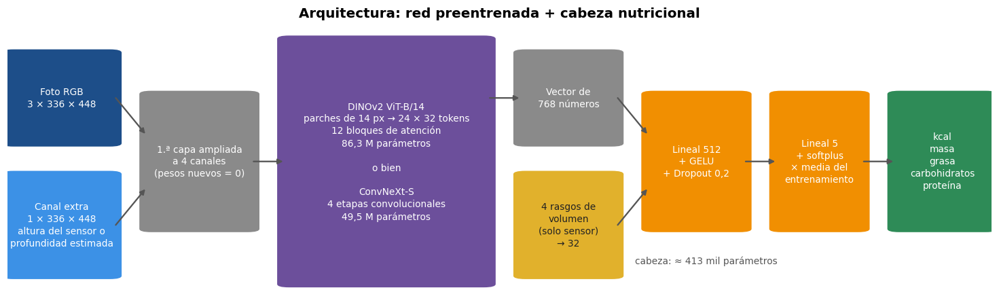

In [32]:
with fase('10. Arquitectura y parámetros', opcional=True):
    filas = []
    for clave in BB_V2:
        m = ModeloNutricion(clave, 'sensor', 'directa', pretrained=False)
        n_bb = sum(q.numel() for q in m.bb.parameters()); n_cab = sum(q.numel() for q in m.cab.parameters())
        filas.append(dict(red=BACKBONES[clave]['nombre'], vector=m.bb.num_features, parametros_red_M=n_bb / 1e6,
                          parametros_cabeza_mil=n_cab / 1e3, preentrenamiento=BACKBONES[clave]['pre']))
        del m
    TAB_PARAM = pd.DataFrame(filas)
    TAB_PARAM.to_csv(TAB / '00_parametros.csv', index=False)
    display(TAB_PARAM.round(2))
    npm = {r.red: r.parametros_red_M for r in TAB_PARAM.itertuples()}
    ncab = TAB_PARAM.parametros_cabeza_mil.max()
    fig, ax = plt.subplots(figsize=(17, 4.8))
    ax.axis('off')
    caja(ax, 0.0, 0.56, 0.11, 0.34, 'Foto RGB\n3 × 336 × 448', COL['azul'])
    caja(ax, 0.0, 0.08, 0.11, 0.38, 'Canal extra\n1 × 336 × 448\naltura del sensor o\nprofundidad estimada', COL['celeste'])
    caja(ax, 0.14, 0.25, 0.11, 0.5, '1.ª capa ampliada\na 4 canales\n(pesos nuevos = 0)', COL['gris'])
    caja(ax, 0.28, 0.05, 0.21, 0.9, f'DINOv2 ViT-B/14\nparches de 14 px → 24 × 32 tokens\n12 bloques de atención\n'
         f'{coma(npm.get("DINOv2 ViT-B/14", 0), 1)} M parámetros\n\no bien\n\nConvNeXt-S\n4 etapas convolucionales\n'
         f'{coma(npm.get("ConvNeXt-S", 0), 1)} M parámetros', COL['morado'])
    caja(ax, 0.52, 0.56, 0.1, 0.34, 'Vector de\n768 números', COL['gris'])
    caja(ax, 0.52, 0.08, 0.1, 0.38, '4 rasgos de\nvolumen\n(solo sensor)\n→ 32', COL['amarillo'], color_texto='#222222')
    caja(ax, 0.65, 0.25, 0.1, 0.5, 'Lineal 512\n+ GELU\n+ Dropout 0,2', COL['naranja'])
    caja(ax, 0.78, 0.25, 0.09, 0.5, 'Lineal 5\n+ softplus\n× media del\nentrenamiento', COL['naranja'])
    caja(ax, 0.9, 0.25, 0.1, 0.5, 'kcal\nmasa\ngrasa\ncarbohidratos\nproteína', COL['verde'])
    flecha(ax, 0.11, 0.73, 0.14, 0.6); flecha(ax, 0.11, 0.27, 0.14, 0.4)
    flecha(ax, 0.25, 0.5, 0.28, 0.5); flecha(ax, 0.49, 0.73, 0.52, 0.73)
    flecha(ax, 0.62, 0.73, 0.65, 0.6); flecha(ax, 0.62, 0.27, 0.65, 0.4)
    flecha(ax, 0.75, 0.5, 0.78, 0.5); flecha(ax, 0.87, 0.5, 0.9, 0.5)
    ax.text(0.71, 0.13, f'cabeza: ≈ {coma(ncab, 0)} mil parámetros', ha='center', fontsize=9, color='#555555',
            transform=ax.transAxes)
    ax.set_title('Arquitectura: red preentrenada + cabeza nutricional', fontsize=13)
    guardar_fig(fig, '00b_arquitectura')

**Hiperparámetros y por qué se escogieron.** Los valores salen de `CFG`, así que la tabla siempre coincide con lo que corrió.

In [33]:
HIPER = pd.DataFrame([
    ('Resolución de entrada', f'{CFG["tam_cenital"][0]} × {CFG["tam_cenital"][1]} (cenital), {CFG["tam_lateral"][0]} × {CFG["tam_lateral"][1]} (lateral)',
     'Conserva la proporción de la foto, es múltiplo de 14 (el parche del ViT) y cabe en la memoria de una T4.'),
    ('Lote', f'{CFG["lote"]} (micro-lotes si no cabe)', 'Gradiente estable; si falta memoria se acumula en trozos sin cambiar el lote efectivo.'),
    ('Tasa de aprendizaje de la red', ' · '.join(f'{BACKBONES[b]["nombre"]} {BACKBONES[b]["lr"]:.0e}' for b in BB_V2),
     'Baja para no borrar lo preentrenado; los transformers piden tasas menores que las CNN.'),
    ('Tasa de aprendizaje de la cabeza', f'{CFG["lr_cabeza"]:.0e}', 'La cabeza arranca de cero y necesita pasos más grandes.'),
    ('Optimizador', f'AdamW, weight decay {CFG["wd"]}', 'Adam con regularización L2 desacoplada; el estándar para ajustar ViT y ConvNeXt.'),
    ('Calendario', f'{CFG["warmup_epocas"]} época de calentamiento + coseno', 'Evita pasos grandes mientras la cabeza es aleatoria y termina con pasos pequeños.'),
    ('EMA de los pesos', f'decaimiento {CFG["ema"]}', f'Promedia ≈ {1 / (1 - CFG["ema"]):.0f} pasos (unas 7 épocas): un modelo más estable.'),
    ('Duración', ' · '.join(f'{BACKBONES[b]["nombre"]} {CFG["min_largo"][b]} min' for b in BB_V2)
     + f' · lateral {CFG["min_lateral"]} min · conjunto {CFG["min_conjunto"]} min',
     'En la v1 la mejor época fue casi siempre la última: faltaba entrenamiento.'),
    ('Early stopping', f'paciencia {CFG["paciencia"]} épocas sobre VS', 'Guarda la mejor época y corta si deja de mejorar.'),
    ('Pérdida', 'suma de errores absolutos divididos por la media (= suma de PMAE)', 'Optimiza la métrica que se reporta y es robusta a etiquetas atípicas.'),
    ('Dropout de la cabeza', '0,2', 'La cabeza tiene ≈ 400 mil parámetros y solo hay ≈ 2 200 platos.'),
    ('Recorte del gradiente', f'norma {CFG["clip"]}', 'Evita saltos bruscos por lotes con platos raros.'),
    ('Aumento de datos', f'volteos, ±3 % de desplazamiento, color ±15-20 %, altura ±{CFG["aum_prof_mm"]:.0f} mm y ±{CFG["aum_prof_escala"] * 100:.0f} %',
     'Nunca cambia la escala, porque el tamaño aparente de la comida es la porción.'),
    ('Aumento fuerte (un solo modelo)', 'lo anterior + giros de ±15°, balance de blancos ±10 % por canal y desenfoque leve (σ = 1 px) en el 30 % de las fotos',
     'Variante para medir si entrenar con fotos alteradas da un modelo más robusto (AugMix) y achica la brecha con la validación que se vio en la v1.'),
    ('Validación', f'{CFG["frac_val"] * 100:.0f} % del entrenamiento, por cadenas (mitad VS, mitad VC)', 'Evita la fuga por escaneos repetidos del mismo plato.'),
    ('Intervalos', f'conformal, α = {CFG["alpha"]}, c = 10 % de la media', 'Cubren el 90 % si los datos nuevos se parecen a los de calibración.'),
    ('Ensamble', f'voraz, hasta {CFG["max_ensamble"]} modelos', 'Promediar modelos distintos reduce la varianza del error.'),
    ('Bootstrap', f'{CFG["bootstrap"]} remuestreos de cadenas', 'Los escaneos repetidos del mismo plato no son independientes; remuestrear platos sueltos estrecha de más los intervalos.'),
    ('Reentrenar con pocos platos', f'{CFG["ajuste_pasos"]} pasos; red completa con 0,3 × la tasa original y cabeza con 1e-4, o solo la cabeza con 3e-4',
     'Pocos pasos y tasas bajas para no olvidar lo aprendido; sin validación, porque el lugar nuevo solo tiene esos k platos. Se fijó antes de correr.'),
], columns=['Hiperparámetro', 'Valor', 'Por qué'])
HIPER.to_csv(TAB / '00_hiperparametros.csv', index=False)
display(HIPER)

,Hiperparámetro,Valor,Por qué
0,Resolución de entrada,"336 × 448 (cenital), 252 × 448 (lateral)","Conserva la proporción de la foto, es múltiplo de 14 (el parche del ViT) y cabe en la memoria de una T4."
1,Lote,32 (micro-lotes si no cabe),Gradiente estable; si falta memoria se acumula en trozos sin cambiar el lote efectivo.
2,Tasa de aprendizaje de la red,DINOv2 ViT-B/14 3e-05 · ConvNeXt-S 1e-04,Baja para no borrar lo preentrenado; los transformers piden tasas menores que las CNN.
3,Tasa de aprendizaje de la cabeza,1e-03,La cabeza arranca de cero y necesita pasos más grandes.
4,Optimizador,"AdamW, weight decay 0.05",Adam con regularización L2 desacoplada; el estándar para ajustar ViT y ConvNeXt.
5,Calendario,1 época de calentamiento + coseno,Evita pasos grandes mientras la cabeza es aleatoria y termina con pasos pequeños.
6,EMA de los pesos,decaimiento 0.998,Promedia ≈ 500 pasos (unas 7 épocas): un modelo más estable.
7,Duración,DINOv2 ViT-B/14 80 min · ConvNeXt-S 60 min · lateral 90 min · conjunto 150 min,En la v1 la mejor época fue casi siempre la última: faltaba entrenamiento.
8,Early stopping,paciencia 12 épocas sobre VS,Guarda la mejor época y corta si deja de mejorar.
9,Pérdida,suma de errores absolutos divididos por la media (= suma de PMAE),Optimiza la métrica que se reporta y es robusta a etiquetas atípicas.


## 19. Experimento de profundidad (DINOv2, entrenamientos largos)

Cuatro modelos idénticos salvo por la entrada, cada uno con 80 minutos de entrenamiento:

| Modelo | Entrada | Pregunta que responde |
|---|---|---|
| Solo foto | RGB | ¿Cuánto mejora la corrida previa con más épocas? (antes: 45 min) |
| Sensor | RGB + altura del sensor (plano fijo) | El mismo de la corrida previa, pero más largo |
| Sensor + aumento de altura | RGB + altura con ±10 mm y ±10 % | ¿Se corrige el sesgo de la Cafe 2? |
| Profundidad estimada | RGB + Depth Anything | ¿Sirve la profundidad de una red, como la que tendría un celular? |

La validación (Cafe 1) decide cuál variante de sensor queda en la receta final: si la diferencia entre las dos es menor que 0,3 puntos (el ruido entre semillas que se vio en la v1), se prefiere el aumento de altura, porque el diagnóstico de la v1 indica que debería ser más robusto. Esta regla se fijó antes de correr. La Cafe 2 se reporta para todas las variantes, pero **no** se usa para escoger.

In [34]:
VARIANTES = [False, 'sensor', 'sensor_aum', 'estimada']
def nombre_p(prof, s, bb='dinov2_b'):
    return f'v2 · {BACKBONES[bb]["nombre"]} · {PROF_ES[prof]} · s{s}'

NOMBRE_FUERTE = f'v2 · {BACKBONES["dinov2_b"]["nombre"]} · Solo foto + aumento fuerte · s1'   # variante de la sección 21

def activa(prof):
    return prof is False or (prof == 'estimada' and ACTIVO['estimada']) or (prof in ('sensor', 'sensor_aum') and ACTIVO['sensor'])

with fase('11. Experimento de profundidad'):
    trab = [receta(nombre_p(p, 1), 'dinov2_b', 1, prof=p, etapa='P', **RECETA) for p in VARIANTES if activa(p)]
    correr_trabajos(trab)
    vals = {p: RES[nombre_p(p, 1)]['val'] for p in VARIANTES if nombre_p(p, 1) in RES}
    sens = {p: v for p, v in vals.items() if p in ('sensor', 'sensor_aum')}
    # Regla fijada antes de correr: si la diferencia en validación es menor que el ruido entre semillas de la v1
    # (≈ 0,3 puntos), se prefiere el aumento de altura, que según el diagnóstico de la v1 debería ser más robusto.
    if len(sens) == 2:
        PROF_SENSOR = 'sensor_aum' if sens['sensor_aum'] <= sens['sensor'] + 0.3 else 'sensor'
    else:
        PROF_SENSOR = next(iter(sens), None)
    print('Validación por variante:', {PROF_ES[p]: round(v, 2) for p, v in vals.items()})
    print('Variante de sensor escogida por la validación:', PROF_ES.get(PROF_SENSOR))
    REPORTE['decisiones'] = dict(prof_sensor=PROF_SENSOR, receta=RECETA)


11. Experimento de profundidad   (minuto 77, quedan 583 min)
→ v2 · DINOv2 ViT-B/14 · Solo foto · s1 en cuda:0 (minuto 77)
→ v2 · DINOv2 ViT-B/14 · Sensor (plano fijo) · s1 en cuda:1 (minuto 77)
  [v2 · DINOv2 ViT-B/14 · Sensor (plano fijo) · s1 · cuda:1] época 1/50  pérdida 3.010  val 36.27 %  (1.4 min)
  [v2 · DINOv2 ViT-B/14 · Solo foto · s1 · cuda:0] época 1/46  pérdida 3.065  val 37.03 %  (1.5 min)
  [v2 · DINOv2 ViT-B/14 · Solo foto · s1 · cuda:0] época 5/46  pérdida 1.405  val 21.61 %  (7.3 min)
  [v2 · DINOv2 ViT-B/14 · Sensor (plano fijo) · s1 · cuda:1] época 5/50  pérdida 1.342  val 19.92 %  (7.4 min)
  [v2 · DINOv2 ViT-B/14 · Solo foto · s1 · cuda:0] época 10/46  pérdida 1.072  val 19.27 %  (14.4 min)
  [v2 · DINOv2 ViT-B/14 · Sensor (plano fijo) · s1 · cuda:1] época 10/50  pérdida 0.988  val 17.35 %  (14.9 min)
  [v2 · DINOv2 ViT-B/14 · Solo foto · s1 · cuda:0] época 15/46  pérdida 0.870  val 17.90 %  (21.5 min)
  [v2 · DINOv2 ViT-B/14 · Sensor (plano fijo) · s1 · cuda:1] 

,variante,modelo,version,VS_kcal,VS_masa,VS_sesgo_masa,TE_kcal,TE_masa,TE_sesgo_masa,C2_kcal,C2_masa,C2_sesgo_masa,epocas,minutos
0,Solo foto,v2 · DINOv2 ViT-B/14 · Solo foto · s1,v2 (80 min),14.01,10.58,-0.92,15.89,11.88,0.52,26.46,21.48,3.19,46,69.08
1,Sensor (plano fijo),v2 · DINOv2 ViT-B/14 · Sensor (plano fijo) · s1,v2 (80 min),12.35,8.47,0.05,14.37,9.80,0.82,30.79,20.52,-15.16,50,76.22
2,Sensor + aumento de altura,v2 · DINOv2 ViT-B/14 · Sensor + aumento de altura · s1,v2 (80 min),13.30,9.42,-0.72,15.03,11.02,-0.42,25.80,19.30,-1.16,48,69.44
3,Profundidad estimada,v2 · DINOv2 ViT-B/14 · Profundidad estimada · s1,v2 (80 min),14.29,10.38,-0.62,15.64,11.95,0.32,26.78,21.65,3.00,46,70.15
4,Sensor (plano fijo),v1 · C · L4 · s1,v1 (45 min),12.52,8.14,-0.66,14.67,10.14,0.56,31.52,23.15,-17.80,25,45.20
5,Sensor (plano fijo),v1 · C · L4 · s2,v1 (45 min),13.75,8.73,-0.71,14.81,10.22,0.78,29.65,20.90,-15.70,22,40.36
6,Sensor (plano fijo),v1 · E · DINOv2 ViT-B/14 RGB-D · s3,v1 (45 min),13.53,8.54,-1.21,15.03,10.20,0.36,30.74,22.15,-16.28,20,38.69
7,Sensor (plano fijo),v1 · E · DINOv2 ViT-B/14 RGB-D · s4,v1 (45 min),13.31,8.55,-0.29,14.21,10.26,0.77,29.09,17.98,-10.93,21,40.48
8,Solo foto,v1 · E · DINOv2 ViT-B/14 RGB · s3,v1 (45 min),14.19,10.46,-1.27,15.42,11.73,-0.15,26.83,21.38,1.74,25,48.45
9,Solo foto,v1 · E · DINOv2 ViT-B/14 RGB · s4,v1 (45 min),14.99,11.07,-1.01,16.30,12.01,-0.13,27.38,21.07,1.91,22,43.41


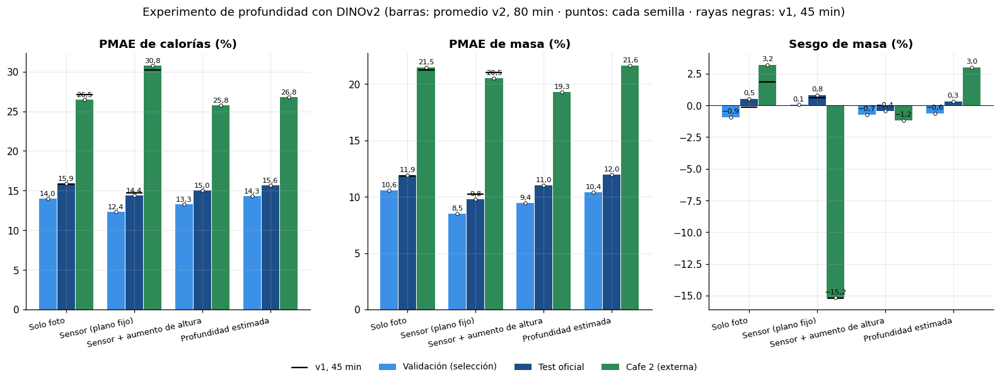

In [35]:
def resumen_variante(n):
    r = RES[n]
    f = {}
    for g in ('VS', 'TE', 'C2'):
        y, p = y_conjunto('cenital', g), r['pred'][('cenital', g)]
        f[f'{g}_kcal'] = pmae(y, p)[0]
        f[f'{g}_masa'] = pmae(y, p)[1]
        f[f'{g}_sesgo_masa'] = 100 * (p[:, 1].sum() / y[:, 1].sum() - 1)
    f.update(epocas=r.get('epocas'), minutos=r.get('min'))
    return f

filas = []
for p in VARIANTES:
    for n in [k for k in RES if k.startswith(nombre_p(p, 1)[:-1])]:
        filas.append(dict(variante=PROF_ES[p], prof=p, modelo=n, version='v2 (80 min)', **resumen_variante(n)))
# Equivalentes de la v1 (45 min): DINOv2 con la misma receta
for n, r in RES.items():
    if r.get('v1') and r['t'].get('bb') == 'dinov2_b' and r['t'].get('fuentes') == ['cenital'] \
            and r['t'].get('cabeza') == RECETA['cabeza'] and r['t'].get('limpiar') == RECETA['limpiar']:
        filas.append(dict(variante=PROF_ES[r['t']['prof']], prof=r['t']['prof'], modelo=n, version='v1 (45 min)', **resumen_variante(n)))
TAB_P = pd.DataFrame(filas)
if len(TAB_P):
    TAB_P.to_csv(TAB / '03_profundidad.csv', index=False)
    display(TAB_P.drop(columns='prof').round(2))
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))
    orden_v = [PROF_ES[p] for p in VARIANTES if PROF_ES[p] in set(TAB_P.variante)]
    for ax, col, tit in [(axs[0], 'kcal', 'PMAE de calorías (%)'), (axs[1], 'masa', 'PMAE de masa (%)'),
                         (axs[2], 'sesgo_masa', 'Sesgo de masa (%)')]:
        x = np.arange(len(orden_v))
        for j, (g, c, desp) in enumerate([('VS', COL['celeste'], -0.27), ('TE', COL['azul'], 0), ('C2', COL['verde'], 0.27)]):
            sub = TAB_P[TAB_P.version.str.startswith('v2')].groupby('variante')[f'{g}_{col}'].mean().reindex(orden_v)
            b = ax.bar(x + desp, sub.values, 0.26, color=c, label=GRUPO_ES[g])
            etiquetar_barras(ax, b, '{:.1f}', dy=0.2, size=7.5)
            ind = TAB_P[TAB_P.version.str.startswith('v2')]
            for xi, var in enumerate(orden_v):                 # cada semilla, como un punto
                vals_ = ind[ind.variante == var][f'{g}_{col}'].values
                ax.scatter(np.full(len(vals_), xi + desp), vals_, s=12, color='white', edgecolor='k', lw=0.6, zorder=4)
            if g in ('TE', 'C2'):
                sub1 = TAB_P[TAB_P.version.str.startswith('v1')].groupby('variante')[f'{g}_{col}'].mean().reindex(orden_v)
                ax.scatter(x + desp, sub1.values, marker='_', s=300, color='k', zorder=3,
                           label='v1, 45 min' if g == 'TE' else None)
        ax.set_xticks(x); ax.set_xticklabels(orden_v, rotation=12, ha='right', fontsize=8.5)
        ax.axhline(0, color='k', lw=0.6); ax.set_title(tit)
    h_, l_ = axs[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc='lower center', ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.1))
    fig.suptitle('Experimento de profundidad con DINOv2 (barras: promedio v2, 80 min · puntos: cada semilla · rayas negras: v1, 45 min)', y=1.02)
    guardar_fig(fig, '10_profundidad')

**Lectura:** con una semilla por variante, el error en calorías (validación VS · test · Cafe 2) es: solo foto 14,0 · 15,9 · 26,5 %; sensor 12,4 · 14,4 · 30,8 %; sensor con aumento de altura 13,3 · 15,0 · 25,8 %; profundidad estimada 14,3 · 15,6 · 26,8 %. El sensor mejora en casa y empeora fuera, con un sesgo de masa de −15,2 % en la Cafe 2. El aumento de altura lo deja en −1,2 % y es la variante con menos error en la Cafe 2, a costa de 0,7 puntos en el test. La profundidad estimada queda a la par de la foto sola. La regla fijada de antemano (preferir el aumento de altura si la diferencia en VS es menor que 0,3 puntos) no se cumplió, porque la diferencia fue de 1,0 punto, y la variante escogida por la validación fue el sensor sin aumento. Son modelos individuales; la comparación pareada con las semillas promediadas está en la sección 23.

### Curvas de aprendizaje

Como la pérdida es la suma de los errores relativos de las 5 salidas, `100 · pérdida / 5` es el PMAE promedio en el entrenamiento: la misma unidad que la validación. Así se ve directo si hay sobreajuste (el entrenamiento sigue bajando y la validación sube) o subajuste (las dos se quedan altas). Cabe tener en cuenta que la curva de entrenamiento se mide con aumento de datos y *dropout*, mientras los pesos cambian, y la de validación con el modelo EMA al final de cada época; por eso la validación puede quedar por debajo del entrenamiento sin que haya un error.

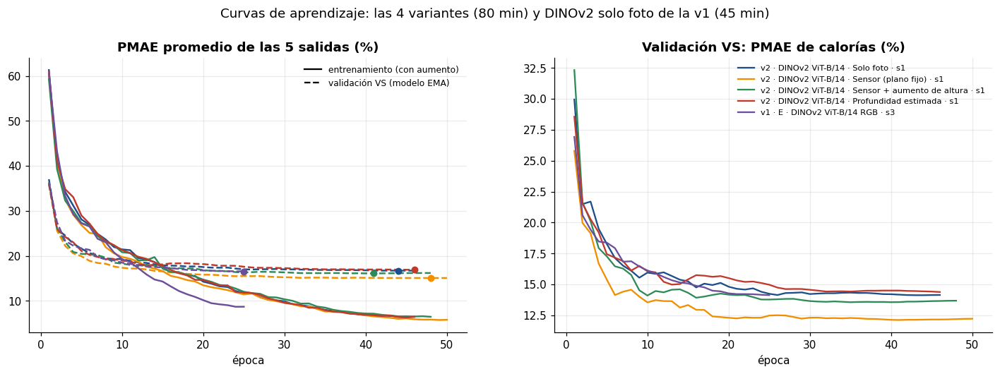

In [36]:
def curvas(nombres, archivo, titulo):
    fig, axs = plt.subplots(1, 2, figsize=(16, 4.6))
    for i, n in enumerate(nombres):
        if n not in RES or RES[n]['t'].get('perdida') == 'paper':
            continue
        h = pd.DataFrame(RES[n]['hist'])
        c = PALETA[i % len(PALETA)]
        axs[0].plot(h.epoca, 100 * h.perdida / 5, color=c, ls='-', lw=1.6)
        axs[0].plot(h.epoca, h.val, color=c, ls='--', lw=1.6)
        axs[0].scatter(RES[n]['mejor_epoca'], h.val.min(), color=c, s=30, zorder=3)
        col = 'val_cenital_kcal' if 'val_cenital_kcal' in h else 'val_lateral_kcal'
        axs[1].plot(h.epoca, h[col], color=c, label=n)
    axs[0].plot([], [], color='k', ls='-', label='entrenamiento (con aumento)')
    axs[0].plot([], [], color='k', ls='--', label='validación VS (modelo EMA)')
    axs[0].set_title('PMAE promedio de las 5 salidas (%)'); axs[0].set_xlabel('época'); axs[0].legend(fontsize=8)
    axs[1].set_title('Validación VS: PMAE de calorías (%)'); axs[1].set_xlabel('época'); axs[1].legend(fontsize=7.5)
    fig.suptitle(titulo, y=1.02)
    guardar_fig(fig, archivo)

v1_rgb = [n for n in RES if n.startswith('v1 · E · DINOv2 ViT-B/14 RGB · ')][:1]
curvas([nombre_p(p, 1) for p in VARIANTES] + v1_rgb, '11_curvas_profundidad',
       'Curvas de aprendizaje: las 4 variantes (80 min) y DINOv2 solo foto de la v1 (45 min)')

**Lectura:** la pérdida de entrenamiento baja hasta ≈ 6 % mientras la validación se estanca en 15–17 % desde la época 20 aproximadamente, así que hay una brecha grande entre ambas: las redes se ajustan al entrenamiento más de lo que generalizan. Entrenar más no la cierra; la validación casi no cambia entre la época 25 y la 50, y la corrida previa de 45 minutos (línea morada) ya había llegado a un nivel parecido. En calorías, la variante con sensor es la que queda más abajo en la validación (≈ 12,2 %), seguida por la de aumento de altura (≈ 13,5 %), la de solo foto (≈ 14,2 %) y la de profundidad estimada (≈ 14,4 %).

## 20. ConvNeXt-S: una CNN para el ensamble y para Grad-CAM

Dos modelos de 60 minutos: solo foto y con la variante de sensor escogida. Además de servir para Grad-CAM, aportan diversidad al ensamble: una CNN se equivoca en platos distintos que un transformer.

In [37]:
with fase('12. ConvNeXt-S', opcional=True):
    if not ACTIVO['convnext_s']:
        raise RuntimeError('ConvNeXt-S quedó desactivada en la prueba de humo')
    trab = [receta(nombre_p(False, 1, 'convnext_s'), 'convnext_s', 1, etapa='G', **RECETA)]
    if PROF_SENSOR:
        trab.insert(0, receta(nombre_p(PROF_SENSOR, 1, 'convnext_s'), 'convnext_s', 1, prof=PROF_SENSOR, etapa='G', **RECETA))
    correr_trabajos(trab)


12. ConvNeXt-S   (minuto 224, quedan 436 min)
→ v2 · ConvNeXt-S · Sensor (plano fijo) · s1 en cuda:0 (minuto 224)
→ v2 · ConvNeXt-S · Solo foto · s1 en cuda:1 (minuto 224)
  [v2 · ConvNeXt-S · Sensor (plano fijo) · s1 · cuda:0] época 1/36  pérdida 2.981  val 35.10 %  (1.5 min)
  [v2 · ConvNeXt-S · Solo foto · s1 · cuda:1] época 1/27  pérdida 2.982  val 35.15 %  (1.9 min)
  [v2 · ConvNeXt-S · Sensor (plano fijo) · s1 · cuda:0] época 5/36  pérdida 1.141  val 19.88 %  (4.7 min)
  [v2 · ConvNeXt-S · Solo foto · s1 · cuda:1] época 5/27  pérdida 1.167  val 21.06 %  (5.2 min)
  [v2 · ConvNeXt-S · Sensor (plano fijo) · s1 · cuda:0] época 10/36  pérdida 0.799  val 17.17 %  (8.8 min)
  [v2 · ConvNeXt-S · Solo foto · s1 · cuda:1] época 10/27  pérdida 0.869  val 19.26 %  (9.4 min)
  [v2 · ConvNeXt-S · Sensor (plano fijo) · s1 · cuda:0] época 15/36  pérdida 0.618  val 16.21 %  (12.8 min)
  [v2 · ConvNeXt-S · Solo foto · s1 · cuda:1] época 15/27  pérdida 0.586  val 18.39 %  (13.5 min)
  [v2 · ConvN

## 21. Aumento fuerte, vista lateral, modelo para las dos vistas y semillas extra

- **Aumento fuerte** (80 min, primero en la cola): DINOv2 solo foto con giros, balance de blancos y desenfoque (sección 6), con la misma semilla que «solo foto» para compararlos uno a uno.
- **Especialista lateral** (90 min): DINOv2 entrenada con fotogramas laterales. Es el protocolo del 26,1 % del paper.
- **Modelo conjunto** (150 min): DINOv2 entrenada con las dos vistas a la vez. En la corrida previa solo alcanzó 3 o 4 épocas; ahora tiene el doble de tiempo.
- **Semillas extra:** con el tiempo que sobra, hasta las 9,75 h, se entrenan más semillas de las configuraciones finales, en orden de prioridad. Todo va en una sola cola, así ninguna GPU queda esperando a la otra, y cada entrenamiento empieza solo si alcanza a terminar antes del corte.

In [38]:
def lista_extra():
    lista = []
    for s in range(2, 6):
        for bb, p in [('dinov2_b', False), ('dinov2_b', PROF_SENSOR), ('dinov2_b', 'estimada'),
                      ('convnext_s', PROF_SENSOR), ('convnext_s', 'estimada'), ('convnext_s', False)]:
            if p is None or not activa(p) or not ACTIVO[bb]:
                continue
            if bb == 'convnext_s' and p == 'estimada' and s > 2:
                continue
            ss = s - 1 if (bb == 'convnext_s' and p == 'estimada') else s     # la CNN con estimada no tiene semilla 1
            lista.append(receta(nombre_p(p, ss, bb), bb, ss, prof=p, etapa='E', **RECETA))
    return lista

with fase('13. Aumento fuerte, vista lateral, modelo conjunto y semillas extra', opcional=True):
    trab = []
    if ACTIVO['fuerte']:
        trab.append(receta(NOMBRE_FUERTE, 'dinov2_b', 1, etapa='A', **dict(RECETA, aug='fuerte')))
    if ACTIVO['lateral']:
        if ACTIVO['conjunto']:
            trab.append(receta('v2 · Conjunto · s1', 'dinov2_b', 1, fuentes=('cenital', 'lateral'),
                               minutos_=CFG['min_conjunto'], etapa='D', **RECETA))
        trab.append(receta('v2 · Lateral · s1', 'dinov2_b', 1, fuentes=('lateral',), minutos_=CFG['min_lateral'],
                           etapa='D', **RECETA))
    trab += [t for t in lista_extra() if t['nombre'] not in RES]
    print(f'{len(trab)} entrenamientos en cola; corren mientras alcance el tiempo '
          f'(corte a los {CFG["corte_entreno_horas"] * 60:.0f} min, ahora minuto {minutos():.0f})')
    correr_trabajos(trab)
    print(f'Modelos disponibles en total: {len(RES)} ({sum(1 for r in RES.values() if r.get("v1"))} de la v1)')


13. Aumento fuerte, vista lateral, modelo conjunto y semillas extra   (minuto 255, quedan 405 min)
24 entrenamientos en cola; corren mientras alcance el tiempo (corte a los 585 min, ahora minuto 255)
→ v2 · DINOv2 ViT-B/14 · Solo foto + aumento fuerte · s1 en cuda:0 (minuto 255)
→ v2 · Conjunto · s1 en cuda:1 (minuto 255)
  [v2 · DINOv2 ViT-B/14 · Solo foto + aumento fuerte · s1 · cuda:0] época 1/47  pérdida 2.985  val 35.21 %  (1.5 min)
  [v2 · DINOv2 ViT-B/14 · Solo foto + aumento fuerte · s1 · cuda:0] época 5/47  pérdida 1.393  val 21.06 %  (7.3 min)
  [v2 · Conjunto · s1 · cuda:1] época 1/9  pérdida 1.944  val 26.09 %  (13.8 min)
  [v2 · DINOv2 ViT-B/14 · Solo foto + aumento fuerte · s1 · cuda:0] época 10/47  pérdida 1.052  val 19.24 %  (14.4 min)
  [v2 · DINOv2 ViT-B/14 · Solo foto + aumento fuerte · s1 · cuda:0] época 15/47  pérdida 0.932  val 17.95 %  (21.6 min)
  [v2 · DINOv2 ViT-B/14 · Solo foto + aumento fuerte · s1 · cuda:0] época 20/47  pérdida 0.715  val 17.35 %  (28.7 mi

### ¿El aumento fuerte achica la brecha entre entrenamiento y validación?

Son las mismas curvas de la sección 19, para «solo foto» con el aumento normal y con el fuerte (misma semilla y mismos 80 min). Con el aumento fuerte, la curva de entrenamiento sube por construcción, porque las fotos son más difíciles; lo que importa es si la validación baja. La comparación en el test y en la Cafe 2 está en la sección 23, y la robustez, en la prueba de estrés.

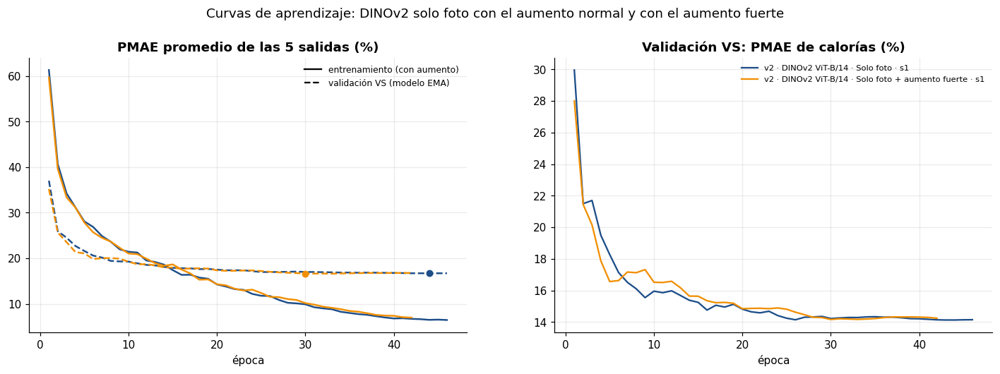

In [39]:
curvas([nombre_p(False, 1), NOMBRE_FUERTE], '11b_curvas_aumento',
       'Curvas de aprendizaje: DINOv2 solo foto con el aumento normal y con el aumento fuerte')

**Lectura:** las curvas de «solo foto» con el aumento normal y con el fuerte son casi idénticas: la validación termina en 16,7 % y 16,6 % respectivamente, y la curva de entrenamiento del aumento fuerte queda solo un poco más arriba. El aumento fuerte no achica la brecha entre entrenamiento y validación de forma apreciable.

## 22. Ensamble y evaluación final

Cuatro ensambles, siempre escogidos con la validación VS. Los candidatos son los modelos de la corrida previa («v1») y de este notebook («v2») que usan esa entrada:
- **Solo foto:** modelos RGB, incluidos el lateral y el conjunto aplicados a la foto cenital.
- **Foto + profundidad estimada:** lo anterior más los modelos con Depth Anything; es lo que tendría un celular.
- **Foto + sensor:** todos los modelos.
- **Vista lateral:** modelos aplicados a los fotogramas laterales, promediados por plato.

**Control.** El ensamble voraz escoge entre decenas de modelos con unas 140 cadenas de validación, así que podría ajustarse a esa validación. Para comprobarlo se reporta al lado el **ensamble de semillas**: el promedio de todas las semillas de DINOv2 con la misma entrada, sin escoger nada. Si los dos dan parecido, la selección no infló el resultado.

Los intervalos del 95 % remuestrean **cadenas** (sección 10). Al lado se muestra, solo como comparación, el intervalo que saldría remuestreando platos sueltos.

**Corrección del sesgo.** Con las predicciones de la corrida previa se vio que los ensambles se quedan cortos también en la validación: en VC, sus predicciones de calorías, grasa, carbohidratos y proteína suman entre 2 y 7 % menos que lo real, mientras que la masa casi no tiene sesgo. La causa probable es la pérdida de error absoluto (ver «Bland-Altman»). Por eso se fijó, antes de correr este notebook, una corrección: multiplicar cada salida por el factor que deja sin sesgo a VC. Se reporta como fila aparte («corregido con VC»), y el ensamble sin corregir sigue siendo el resultado principal.

El test, la Cafe 2 y la vista lateral se miden **una sola vez**, con todo ya decidido.

In [40]:
TIPOS_ENS = {'Solo foto': (False,), 'Foto + profundidad estimada': (False, 'estimada'),
             'Foto + sensor': (False, 'estimada', 'sensor', 'sensor_aum')}

def candidatos(vista, profs):
    c = {}
    for n, r in RES.items():
        if r.get('smoke') or r['t'].get('prof', False) not in profs:
            continue
        p = pred_conjunto(r, vista, 'VS')
        if p is not None:
            c[n] = p
    return c

def promedio(miembros, vista, g, por_plato=True):
    return np.mean([pred_conjunto(RES[n], vista, g, por_plato) for n in miembros], 0)

with fase('14. Ensamble y evaluación final'):
    ENS = {}
    pedidos = [(k, 'cenital', v) for k, v in TIPOS_ENS.items()]
    if ACTIVO['lateral']:
        pedidos.append(('Vista lateral', 'lateral', (False,)))
    for clave, vista, profs in pedidos:
        cands = candidatos(vista, profs)
        if not cands:
            continue
        miembros, v = ensamble_voraz(cands, y_conjunto(vista, 'VS'))
        ENS[clave] = dict(vista=vista, miembros=miembros, val=v,
                          pred={g: promedio(miembros, vista, g) for g in ('VS', 'VC', 'TE', 'C2')})
        if vista == 'lateral':
            ENS[clave]['pred_frames'] = {g: promedio(miembros, vista, g, por_plato=False) for g in ('TE', 'C2')}
        print(f'{clave}: {len(miembros)} miembros, val {v:.2f} %  →  {miembros}')
    # Control del ensamble voraz: el promedio de todas las semillas de la configuración final, sin escoger con VS
    ENS_SEM = {}
    for clave, prof in [('Solo foto', False), ('Foto + profundidad estimada', 'estimada'), ('Foto + sensor', PROF_SENSOR)]:
        ms = [n for n in RES if prof is not None and n.startswith(nombre_p(prof, 1)[:-1]) and ('cenital', 'VS') in RES[n]['pred']]
        if len(ms) >= 2:
            ENS_SEM[clave] = dict(miembros=ms, pred={g: promedio(ms, 'cenital', g) for g in ('VS', 'VC', 'TE', 'C2')})
            print(f'Ensamble de semillas · {clave}: {len(ms)} semillas')
    def mejor_ind(vista, profs):
        c = candidatos(vista, profs)
        return min(c, key=lambda n: pmae(y_conjunto(vista, 'VS'), c[n]).mean()) if c else None
    ref_v1 = [n for n in RES if n == 'v1 · C · L0 · s1']
    filas = []
    for clave, e in ENS.items():
        vista = e['vista']
        for g in ('TE', 'C2'):
            y = y_conjunto(vista, g)
            if len(y) == 0:
                continue
            cg = cadenas_de(vista, g)
            ref = pred_conjunto(RES[ref_v1[0]], vista, g) if (vista == 'cenital' and ref_v1) else None
            ic, icd = bootstrap_pmae(y, e['pred'][g], ref=ref, grupos=cg)
            ic_plato, _ = bootstrap_pmae(y, e['pred'][g])          # como si cada plato fuera independiente
            f = tabla_metricas(f'Ensamble · {clave}', y, e['pred'][g])
            f.update(conjunto=GRUPO_ES[g], kcal_ic_bajo=ic[0, 0], kcal_ic_alto=ic[1, 0],
                     kcal_ic_plato_bajo=ic_plato[0, 0], kcal_ic_plato_alto=ic_plato[1, 0],
                     sesgo_masa=100 * (e['pred'][g][:, 1].sum() / y[:, 1].sum() - 1))
            if icd is not None:                      # mejora frente a «como el paper» (v1, L0), en puntos de PMAE
                f.update(mejora_vs_paper_bajo=-icd[1, 0], mejora_vs_paper_alto=-icd[0, 0])
            filas.append(f)
            fil_g = filas_de(vista, g)
            pl = CEN_PLATO[fil_g] if vista == 'cenital' else np.unique(LAT_PLATO[fil_g])
            ok = ~SOSP[pl]
            if (~ok).any():                          # sensibilidad: sin las etiquetas imposibles
                f2 = tabla_metricas(f'Ensamble · {clave} (sin {int((~ok).sum())} etiquetas imposibles)', y[ok], e['pred'][g][ok])
                f2.update(conjunto=GRUPO_ES[g])
                filas.append(f2)
            n_ind = mejor_ind(vista, TIPOS_ENS.get(clave, (False,)))
            if n_ind:
                pi = pred_conjunto(RES[n_ind], vista, g)
                fi = tabla_metricas(f'Mejor individual · {clave} ({n_ind})', y, pi)
                ici, _ = bootstrap_pmae(y, pi, grupos=cg)
                fi.update(conjunto=GRUPO_ES[g], kcal_ic_bajo=ici[0, 0], kcal_ic_alto=ici[1, 0])
                filas.append(fi)
        if vista == 'lateral':                       # protocolo del paper: cada fotograma cuenta
            for g in ('TE', 'C2'):
                yf = y_conjunto('lateral', g, por_plato=False)
                if len(yf):
                    f = tabla_metricas(f'Ensamble · {clave} (por fotograma)', yf, e['pred_frames'][g])
                    f.update(conjunto=GRUPO_ES[g])
                    filas.append(f)
    for clave, e in ENS_SEM.items():
        for g in ('TE', 'C2'):
            y = y_conjunto('cenital', g)
            ic, _ = bootstrap_pmae(y, e['pred'][g], grupos=cadenas_de('cenital', g))
            f = tabla_metricas(f'Ensamble de semillas · {clave} ({len(e["miembros"])} semillas)', y, e['pred'][g])
            f.update(conjunto=GRUPO_ES[g], kcal_ic_bajo=ic[0, 0], kcal_ic_alto=ic[1, 0],
                     sesgo_masa=100 * (e['pred'][g][:, 1].sum() / y[:, 1].sum() - 1))
            filas.append(f)
    # Corrección del sesgo (sección «Bland-Altman»): un factor por salida que deja sin sesgo a VC; decidido antes de correr
    for clave, e in ENS.items():
        if e['vista'] != 'cenital':
            continue
        f_vc = y_conjunto('cenital', 'VC').sum(0) / e['pred']['VC'].sum(0)
        for g in ('TE', 'C2'):
            y, pc = y_conjunto('cenital', g), e['pred'][g] * f_vc
            ic, _ = bootstrap_pmae(y, pc, grupos=cadenas_de('cenital', g))
            f = tabla_metricas(f'Ensamble · {clave} · corregido con VC', y, pc)
            f.update(conjunto=GRUPO_ES[g], kcal_ic_bajo=ic[0, 0], kcal_ic_alto=ic[1, 0],
                     sesgo_masa=100 * (pc[:, 1].sum() / y[:, 1].sum() - 1))
            filas.append(f)
    TAB_FINAL = pd.DataFrame(filas)
    TAB_FINAL.to_csv(TAB / '04_final.csv', index=False)
    cols = ['modelo', 'conjunto', 'n'] + [f'PMAE_{o}' for o in OBJ] + ['MAE_kcal', 'kcal_ic_bajo', 'kcal_ic_alto',
                                                                       'kcal_ic_plato_bajo', 'kcal_ic_plato_alto']
    display(TAB_FINAL[[c for c in cols if c in TAB_FINAL]].round(2))
    print('IC 95 % por cadenas (kcal_ic_*) y, solo como comparación, remuestreando platos sueltos (kcal_ic_plato_*).')
    # Precisión práctica: qué fracción de platos queda cerca del valor real
    filas = []
    for clave, e in ENS.items():
        if e['vista'] != 'cenital':
            continue
        for g in ('TE', 'C2'):
            y, p = y_conjunto('cenital', g), e['pred'][g]
            err = np.abs(p[:, 0] - y[:, 0])
            filas.append(dict(ensamble=clave, conjunto=GRUPO_ES[g], n=len(y),
                              a_50_kcal=100 * np.mean(err <= 50), a_100_kcal=100 * np.mean(err <= 100),
                              a_20_pct=100 * np.mean(err <= 0.2 * np.maximum(y[:, 0], 1)),
                              carb_a_10g=100 * np.mean(np.abs(p[:, 3] - y[:, 3]) <= 10)))
    TAB_PRACT = pd.DataFrame(filas)
    TAB_PRACT.to_csv(TAB / '04b_precision_practica.csv', index=False)
    print('Porcentaje de platos con el error dentro de cada margen (±50 kcal, ±100 kcal, ±20 %, ±10 g de carbohidratos):')
    display(TAB_PRACT.round(1))
    for clave, e in ENS.items():                     # verificación con el script oficial
        if e['vista'] == 'cenital':
            for g in ('TE', 'C2'):
                fil = FUENTES['cenital'].indices(g)
                of, dif = evaluar_oficial(PLATOS.dish_id.values[CEN_PLATO[fil]], Y_CEN[fil], e['pred'][g],
                                          nombre_archivo(f'{clave}_{g}'))
                print(f'Script oficial · {clave} · {GRUPO_ES[g]}: calorías {of["calories_MAE"]:.1f} kcal '
                      f'({of["calories_MAE_%"]:.1f} %), diferencia con nuestro cálculo {dif:.1e}')
                pd.DataFrame({'dish_id': PLATOS.dish_id.values[CEN_PLATO[fil]],
                              **{o: e['pred'][g][:, j] for j, o in enumerate(['calories', 'mass', 'fat', 'carb', 'protein'])}}
                             ).to_csv(PRED / f'oficial_{nombre_archivo(clave)}_{g}.csv', index=False, header=False)


14. Ensamble y evaluación final   (minuto 547, quedan 113 min)
Solo foto: 4 miembros, val 15.77 %  →  ['v2 · Conjunto · s1', 'v1 · E · DINOv2 ViT-B/14 RGB · s3', 'v1 · E · EfficientNetV2-S RGB · s2', 'v1 · D · Conjunto · s2']
Foto + profundidad estimada: 5 miembros, val 15.71 %  →  ['v2 · Conjunto · s1', 'v2 · ConvNeXt-S · Profundidad estimada · s1', 'v1 · D · Conjunto · s2', 'v1 · E · DINOv2 ViT-B/14 RGB · s3', 'v1 · E · EfficientNetV2-S RGB · s2']
Foto + sensor: 5 miembros, val 14.28 %  →  ['v2 · DINOv2 ViT-B/14 · Sensor (plano fijo) · s2', 'v1 · E · ConvNeXt-S RGB-D · s2', 'v1 · C · L4 · s1', 'v1 · D · Conjunto · s2', 'v1 · E · EfficientNetV2-S RGB-D · s2']
Vista lateral: 2 miembros, val 16.65 %  →  ['v2 · Conjunto · s1', 'v2 · Lateral · s1']
Ensamble de semillas · Solo foto: 2 semillas
Ensamble de semillas · Foto + profundidad estimada: 2 semillas
Ensamble de semillas · Foto + sensor: 2 semillas


,modelo,conjunto,n,PMAE_kcal,PMAE_masa,PMAE_grasa,PMAE_carb,PMAE_prot,MAE_kcal,kcal_ic_bajo,kcal_ic_alto,kcal_ic_plato_bajo,kcal_ic_plato_alto
0,Ensamble · Solo foto,Test oficial,507,15.39,11.50,23.15,21.43,20.94,39.33,13.75,17.04,14.11,16.85
1,Mejor individual · Solo foto (v2 · Conjunto · s1),Test oficial,507,16.57,11.95,24.46,22.01,21.18,42.33,14.96,18.19,NaN,NaN
2,Ensamble · Solo foto,Cafe 2 (externa),228,26.00,19.71,36.04,52.64,43.95,65.59,22.54,29.81,23.27,28.79
3,Mejor individual · Solo foto (v2 · Conjunto · s1),Cafe 2 (externa),228,26.46,20.91,36.95,54.35,41.24,66.75,23.05,30.50,NaN,NaN
4,Ensamble · Foto + profundidad estimada,Test oficial,507,15.18,11.36,22.74,21.28,21.02,38.77,13.52,16.86,13.91,16.61
5,Mejor individual · Foto + profundidad estimada (v2 · Conjunto · s1),Test oficial,507,16.57,11.95,24.46,22.01,21.18,42.33,14.96,18.19,NaN,NaN
6,Ensamble · Foto + profundidad estimada,Cafe 2 (externa),228,26.15,19.75,36.08,53.02,44.73,65.96,22.72,29.94,23.45,28.90
7,Mejor individual · Foto + profundidad estimada (v2 · Conjunto · s1),Cafe 2 (externa),228,26.46,20.91,36.95,54.35,41.24,66.75,23.05,30.50,NaN,NaN
8,Ensamble · Foto + sensor,Test oficial,507,13.78,9.50,21.15,20.88,19.94,35.19,12.30,15.35,12.55,15.15
9,Mejor individual · Foto + sensor (v2 · DINOv2 ViT-B/14 · Sensor (plano fijo) · s2),Test oficial,507,14.47,9.82,21.65,21.52,20.75,36.96,13.03,16.05,NaN,NaN


IC 95 % por cadenas (kcal_ic_*) y, solo como comparación, remuestreando platos sueltos (kcal_ic_plato_*).
Porcentaje de platos con el error dentro de cada margen (±50 kcal, ±100 kcal, ±20 %, ±10 g de carbohidratos):


,ensamble,conjunto,n,a_50_kcal,a_100_kcal,a_20_pct,carb_a_10g
0,Solo foto,Test oficial,507,75.9,89.0,66.7,89.9
1,Solo foto,Cafe 2 (externa),228,55.7,77.2,44.3,71.1
2,Foto + profundidad estimada,Test oficial,507,76.1,89.3,68.8,89.9
3,Foto + profundidad estimada,Cafe 2 (externa),228,53.5,78.5,44.3,71.5
4,Foto + sensor,Test oficial,507,77.3,91.9,72.6,90.7
5,Foto + sensor,Cafe 2 (externa),228,48.7,74.1,38.6,72.4


Script oficial · Solo foto · Test oficial: calorías 39.3 kcal (15.4 %), diferencia con nuestro cálculo 2.3e-07
Script oficial · Solo foto · Cafe 2 (externa): calorías 65.6 kcal (26.0 %), diferencia con nuestro cálculo 3.6e-07
Script oficial · Foto + profundidad estimada · Test oficial: calorías 38.8 kcal (15.2 %), diferencia con nuestro cálculo 3.6e-07
Script oficial · Foto + profundidad estimada · Cafe 2 (externa): calorías 66.0 kcal (26.1 %), diferencia con nuestro cálculo 2.8e-07
Script oficial · Foto + sensor · Test oficial: calorías 35.2 kcal (13.8 %), diferencia con nuestro cálculo 2.6e-07
Script oficial · Foto + sensor · Cafe 2 (externa): calorías 74.5 kcal (29.5 %), diferencia con nuestro cálculo 8.0e-07


### Comparación con lo publicado

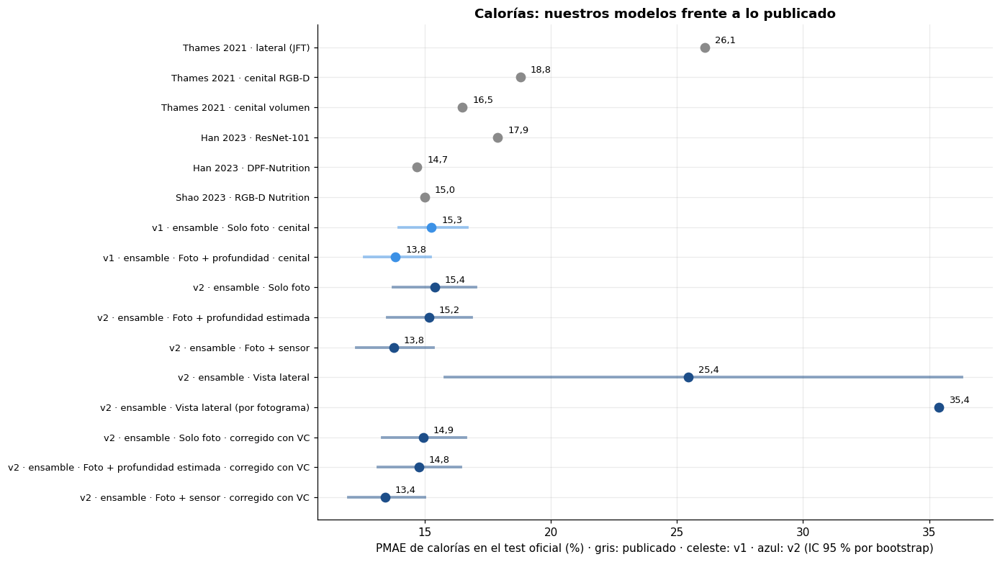

In [41]:
def fila_final(modelo, conjunto='TE'):
    t_ = TAB_FINAL[(TAB_FINAL.modelo == modelo) & (TAB_FINAL.conjunto == GRUPO_ES[conjunto])]
    return t_.iloc[0] if len(t_) else None

filas_g = [(l['nombre'], l['pmae'][0], None, COL['gris']) for l in LITERATURA]
v1_ens = {k: v for k, v in (V1R or {}).get('ensambles', {}).items()}
for f in (V1R or {}).get('final', []):
    if f['modelo'].startswith('Ensamble') and f['conjunto'] == GRUPO_ES['TE'] and 'cenital' in f['modelo'] and 'sin ' not in f['modelo']:
        filas_g.append((f['modelo'].replace('Ensamble · ', 'v1 · ensamble · '), f['PMAE_kcal'],
                        (f.get('kcal_ic_bajo'), f.get('kcal_ic_alto')), COL['celeste']))
for _, f in TAB_FINAL[(TAB_FINAL.conjunto == GRUPO_ES['TE']) & TAB_FINAL.modelo.str.startswith('Ensamble')].iterrows():
    if 'sin ' in f.modelo or f.modelo.startswith('Ensamble de semillas'):     # el control de semillas va solo en la tabla
        continue
    filas_g.append((f.modelo.replace('Ensamble · ', 'v2 · ensamble · '), f.PMAE_kcal,
                    (f.get('kcal_ic_bajo'), f.get('kcal_ic_alto')), COL['azul']))
fig, ax = plt.subplots(figsize=(11, 0.42 * len(filas_g) + 1.4))
y_ = np.arange(len(filas_g))[::-1]
for yi, (n, v, ic, c) in zip(y_, filas_g):
    if ic is not None and ic[0] is not None and np.isfinite(ic[0]):
        ax.plot(ic, [yi, yi], color=c, lw=2.5, alpha=0.5)
    ax.plot(v, yi, 'o', color=c, ms=8)
    ax.text(v + 0.4, yi + 0.15, coma(v), fontsize=8.5)
ax.set_yticks(y_); ax.set_yticklabels([f[0] for f in filas_g], fontsize=8.5)
ax.set_xlabel('PMAE de calorías en el test oficial (%) · gris: publicado · celeste: v1 · azul: v2 (IC 95 % por bootstrap)')
ax.set_title('Calorías: nuestros modelos frente a lo publicado')
guardar_fig(fig, '12_literatura')

**Lectura:** el ensamble con sensor (13,8 %, intervalo 12,3–15,4 %) queda por debajo de los 18,8 % de Thames con foto cenital y de los 17,9 % de ResNet-101, y a la par de DPF-Nutrition (14,7 %) y Shao (15,0 %), cuyos valores caen dentro del intervalo. El ensamble solo foto (15,4 %, intervalo 13,8–17,0 %) empata con DPF-Nutrition y con Shao. La corrección con VC baja el error unos 0,4 puntos (14,9, 14,8 y 13,4 %). El ensamble de esta ejecución no se distingue del de la corrida previa (13,8 % en ambos). La vista lateral queda en 25,4 % por plato, con un intervalo muy ancho (15,8–36,3 %) porque dos platos con etiquetas imposibles pesan mucho: sin ellos baja a 16,5 %. Por fotograma es 35,4 %, frente al 26,1 % del artículo; no son comparables, porque aquí se usan 20 fotogramas por plato y el artículo muestrea otros.

### Predicción contra valor real

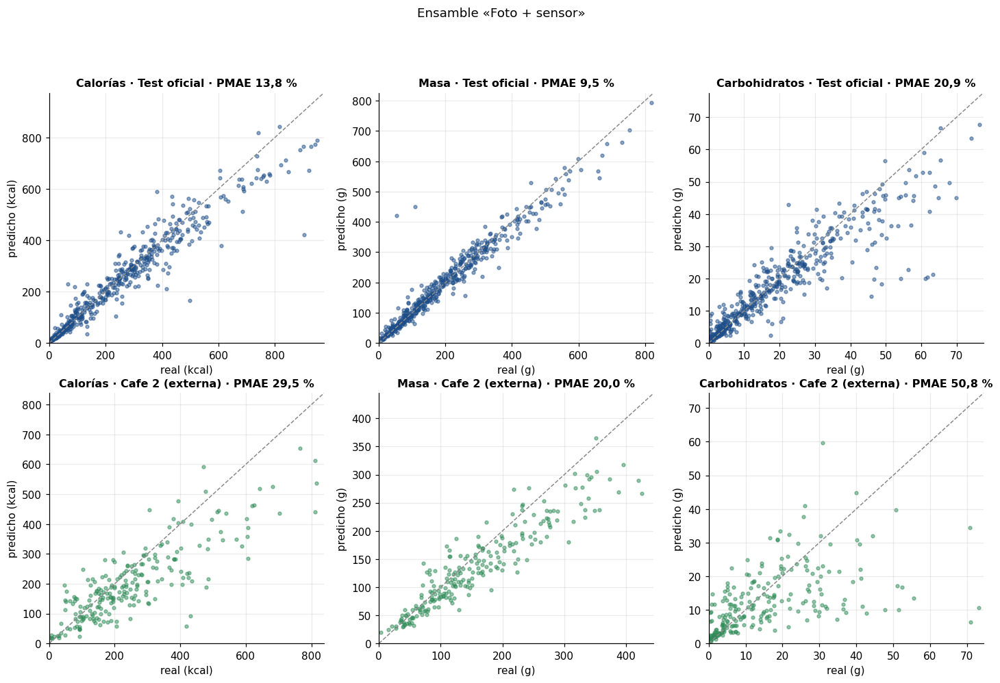

In [42]:
clave_p = 'Foto + sensor' if 'Foto + sensor' in ENS else 'Solo foto'
E_P = ENS[clave_p]                                  # ensamble principal para el análisis
fig, axs = plt.subplots(2, 3, figsize=(16, 9.5))
for fila_ax, g in zip(axs, ('TE', 'C2')):
    y, p = y_conjunto('cenital', g), E_P['pred'][g]
    for ax, j in zip(fila_ax, (0, 1, 3)):
        lim = np.percentile(np.r_[y[:, j], p[:, j]], 99.5) * 1.05
        ax.scatter(y[:, j], p[:, j], s=10, alpha=0.5, color=COL['azul'] if g == 'TE' else COL['verde'])
        ax.plot([0, lim], [0, lim], color=COL['gris'], ls='--', lw=1)
        ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_xlabel(f'real ({UNID[j]})'); ax.set_ylabel(f'predicho ({UNID[j]})')
        ax.set_title(f'{OBJ_ES[j]} · {GRUPO_ES[g]} · PMAE {coma(pmae(y, p)[j])} %', fontsize=10.5)
fig.suptitle(f'Ensamble «{clave_p}»', y=1.0)
guardar_fig(fig, '13_pred_vs_real')

**Lectura:** en el test, las predicciones siguen la diagonal en las tres variables (error de 13,8 % en calorías, 9,5 % en masa y 20,9 % en carbohidratos); la dispersión crece con el tamaño del plato y se ven unos pocos platos muy mal estimados (por ejemplo, uno de ≈ 900 kcal predicho en ≈ 420). En la Cafe 2 (29,5 %, 20,0 % y 50,8 %) los puntos quedan por debajo de la diagonal en los platos grandes, es decir, el modelo subestima, y en los carbohidratos la nube es muy dispersa.

### ¿Subestima o sobreestima? Sesgo y límites de acuerdo (Bland-Altman)

Es el mismo análisis que usó el NIH con las cuatro apps comerciales, que subestimaron cerca de un tercio de las calorías y unos 30 g de grasa por comida (resultados preliminares, con comidas distintas a las de Nutrition5k). Un buen modelo tiene el sesgo cerca de 0 y los límites de acuerdo estrechos. Si la tendencia (pendiente) no es plana, el sesgo cambia con el tamaño del plato. El IC del sesgo remuestrea cadenas.

**¿Por qué importa el sesgo?** Para el total de un día o de una semana, los errores de cada plato se compensan en parte entre sí, pero el sesgo se acumula. Hay una causa probable de sesgo aun en casa: la pérdida usa el error absoluto, que lleva al modelo hacia la *mediana* de lo posible para cada foto, y con platos sesgados a la derecha la mediana queda por debajo de la media, así que la suma de las predicciones se queda corta. Por eso se prueba la corrección más simple: multiplicar cada salida por el factor que deja sin sesgo la validación de calibración (VC), y medir qué pasa con el sesgo y con el error en el test y en la Cafe 2.


14b. Sesgo (Bland-Altman)   (minuto 547, quedan 113 min)


,ensamble,conjunto,objetivo,unidad,sesgo,sesgo_pct,lim_bajo,lim_alto,pendiente,sesgo_pct_bajo,sesgo_pct_alto,pmae,factor_vc,sesgo_pct_corr,pmae_corr
0,Solo foto,Test oficial,Calorías,kcal,-14.82,-5.80,-139.10,109.46,-0.15,-8.28,-3.03,15.39,1.04,-1.93,14.93
1,Solo foto,Test oficial,Masa,g,-1.42,-0.72,-74.99,72.15,-0.08,-2.72,1.60,11.50,1.00,-0.77,11.51
2,Solo foto,Test oficial,Grasa,g,-0.84,-6.55,-10.51,8.83,-0.16,-10.71,-2.09,23.15,1.07,-0.10,22.52
3,Solo foto,Test oficial,Carbohidratos,g,-1.81,-9.22,-16.13,12.50,-0.24,-13.35,-4.98,21.43,1.04,-5.72,20.88
4,Solo foto,Test oficial,Proteína,g,-0.75,-4.30,-14.87,13.36,-0.14,-8.38,0.66,20.94,1.05,0.80,20.35
5,Solo foto,Cafe 2 (externa),Calorías,kcal,-21.83,-8.65,-197.30,153.65,-0.25,-14.34,-2.81,26.00,1.04,-4.90,25.94
6,Solo foto,Cafe 2 (externa),Masa,g,3.54,2.21,-77.30,84.38,-0.18,-1.82,6.62,19.71,1.00,2.15,19.70
7,Solo foto,Cafe 2 (externa),Grasa,g,-2.83,-19.71,-16.22,10.56,-0.37,-25.53,-12.57,36.04,1.07,-14.17,34.69
8,Solo foto,Cafe 2 (externa),Carbohidratos,g,-1.94,-12.16,-26.77,22.88,-0.51,-23.66,0.44,52.64,1.04,-8.77,53.27
9,Solo foto,Cafe 2 (externa),Proteína,g,2.84,19.12,-14.84,20.52,-0.05,6.02,32.14,43.95,1.05,25.47,47.57


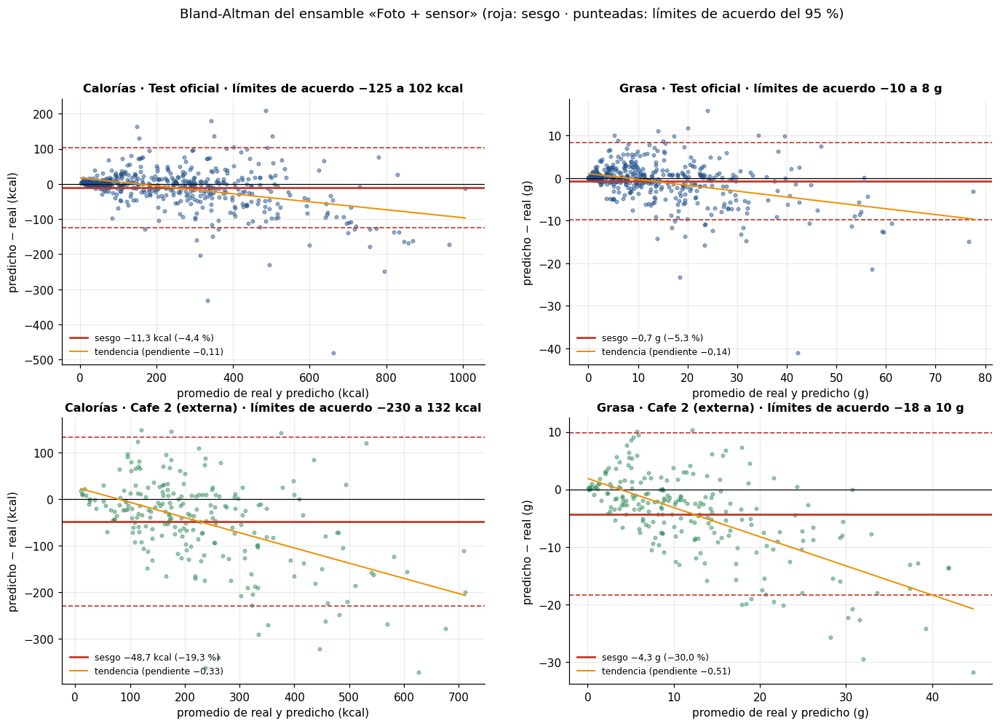

In [43]:
with fase('14b. Sesgo (Bland-Altman)', opcional=True):
    filas = []
    for clave, e in ENS.items():
        if e['vista'] != 'cenital':
            continue
        f_vc = y_conjunto('cenital', 'VC').sum(0) / e['pred']['VC'].sum(0)     # factor que deja sin sesgo a VC
        for g in ('TE', 'C2'):
            y, p, cg = y_conjunto('cenital', g), e['pred'][g], cadenas_de('cenital', g)
            pc = p * f_vc
            pm, pmc = pmae(y, p), pmae(y, pc)
            for j in range(5):
                filas.append(dict(ensamble=clave, conjunto=GRUPO_ES[g], objetivo=OBJ_ES[j], unidad=UNID[j],
                                  **bland_altman(y[:, j], p[:, j], cg), pmae=pm[j], factor_vc=f_vc[j],
                                  sesgo_pct_corr=100 * (pc[:, j].sum() / y[:, j].sum() - 1), pmae_corr=pmc[j]))
    TAB_BA = pd.DataFrame(filas)
    TAB_BA.to_csv(TAB / '04d_bland_altman.csv', index=False)
    display(TAB_BA.round(2))
    fig, axs = plt.subplots(2, 2, figsize=(15, 9.5))
    for fila_ax, g in zip(axs, ('TE', 'C2')):
        y, p = y_conjunto('cenital', g), E_P['pred'][g]
        for ax, j in zip(fila_ax, (0, 2)):
            d, m = p[:, j] - y[:, j], (p[:, j] + y[:, j]) / 2
            b = TAB_BA[(TAB_BA.ensamble == clave_p) & (TAB_BA.conjunto == GRUPO_ES[g]) & (TAB_BA.objetivo == OBJ_ES[j])].iloc[0]
            ax.scatter(m, d, s=9, alpha=0.45, color=COL['azul'] if g == 'TE' else COL['verde'])
            ax.axhline(0, color='k', lw=0.8)
            ax.axhline(b.sesgo, color=COL['rojo'], lw=1.8, label=f'sesgo {coma(b.sesgo)} {UNID[j]} ({coma(b.sesgo_pct)} %)')
            for lim in (b.lim_bajo, b.lim_alto):
                ax.axhline(lim, color=COL['rojo'], ls='--', lw=1.1)
            xs_ = np.linspace(m.min(), m.max(), 20)
            ax.plot(xs_, np.polyval(np.polyfit(m, d, 1), xs_), color=COL['naranja'], lw=1.3,
                    label=f'tendencia (pendiente {coma(b.pendiente, 2)})')
            ax.set_xlabel(f'promedio de real y predicho ({UNID[j]})'); ax.set_ylabel(f'predicho − real ({UNID[j]})')
            ax.set_title(f'{OBJ_ES[j]} · {GRUPO_ES[g]} · límites de acuerdo {coma(b.lim_bajo, 0)} a {coma(b.lim_alto, 0)} {UNID[j]}',
                         fontsize=10.5)
            ax.legend(fontsize=8, loc='lower left')
    fig.suptitle(f'Bland-Altman del ensamble «{clave_p}» (roja: sesgo · punteadas: límites de acuerdo del 95 %)', y=1.0)
    guardar_fig(fig, '13a_bland_altman')

**Lectura:** en el test, los dos ensambles subestiman las calorías en promedio: −5,8 % con solo foto (IC 95 %: −8,3 a −3,0 %) y −4,4 % con sensor (−11,3 kcal; IC −6,7 a −1,9 %), con límites de acuerdo de −125 a +102 kcal para el sensor. La masa casi no tiene sesgo (−0,7 y +0,3 %). La pendiente negativa (−0,11 a −0,15 en calorías) indica que el modelo sobreestima los platos pequeños y subestima los grandes. En la Cafe 2, el ensamble con sensor subestima las calorías en 19,3 % (−48,8 kcal; IC −24,1 a −14,0 %) y la masa en 13,8 %, mientras que con solo foto el sesgo en calorías es de −8,7 % y el de masa de +2,2 %. La corrección con el factor de VC (entre 0,98 y 1,07) lleva el sesgo del test de −4,4 a −1,4 % y el error de 13,8 a 13,4 %; en la Cafe 2 el sesgo pasa de −19,3 a −16,8 % y el error de 29,5 a 28,6 %, de modo que lo calibrado en casa casi no corrige fuera. Como referencia, las cuatro apps del estudio del NIH subestimaron cerca de un tercio de las calorías (con otras comidas y resultados preliminares).

## 23. ¿Las diferencias son reales? Comparaciones pareadas

Con 507 platos de test, una diferencia de medio punto puede ser solo ruido. Para cada par de modelos se remuestrean las cadenas 2 000 veces (**bootstrap pareado**: los dos modelos se evalúan en los mismos platos de cada remuestreo) y se obtiene un intervalo del 95 % para la diferencia de PMAE. Si el intervalo no cruza el 0, la diferencia es real con estos datos. En las comparaciones de un modelo individual se promedian sus semillas.


15. Comparaciones pareadas   (minuto 547, quedan 113 min)


,comparacion,conjunto,A,B,delta,bajo,alto
0,Ensamble: con sensor − solo foto,Test oficial,13.78,15.39,-1.62,-2.42,-0.84
1,Ensamble: con sensor − solo foto,Cafe 2 (externa),29.54,26.00,3.53,1.09,5.82
2,Ensamble: con profundidad estimada − solo foto,Test oficial,15.18,15.39,-0.22,-0.41,-0.02
3,Ensamble: con profundidad estimada − solo foto,Cafe 2 (externa),26.15,26.00,0.15,-0.33,0.66
4,DINOv2: sensor − solo foto,Test oficial,14.23,15.77,-1.54,-2.47,-0.60
5,DINOv2: sensor − solo foto,Cafe 2 (externa),30.86,26.01,4.85,1.57,7.99
6,DINOv2: sensor + aumento de altura − sensor,Test oficial,15.03,14.23,0.80,0.02,1.63
7,DINOv2: sensor + aumento de altura − sensor,Cafe 2 (externa),25.80,30.86,-5.06,-7.53,-2.34
8,DINOv2: profundidad estimada − solo foto,Test oficial,15.40,15.77,-0.37,-0.83,0.09
9,DINOv2: profundidad estimada − solo foto,Cafe 2 (externa),26.40,26.01,0.39,-0.63,1.49


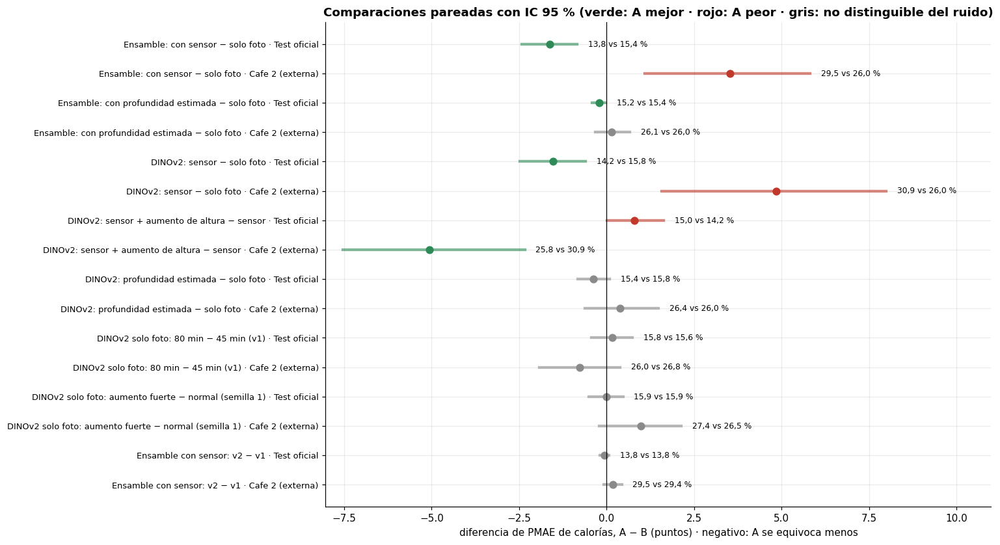

In [44]:
def prom_semillas(prefijo):
    """Promedio de las predicciones cenitales de todas las semillas cuyo nombre empieza con el prefijo."""
    ns = [n for n in RES if n.startswith(prefijo) and ('cenital', 'TE') in RES[n]['pred']]
    if not ns:
        return None
    return {g: np.mean([RES[n]['pred'][('cenital', g)] for n in ns], 0) for g in ('TE', 'C2')}

with fase('15. Comparaciones pareadas', opcional=True):
    filas = []
    def comparar(nombre, pa, pb):
        if pa is None or pb is None:
            return
        for g in ('TE', 'C2'):
            y = y_conjunto('cenital', g)
            _, icd = bootstrap_pmae(y, pa[g], ref=pb[g], semilla=1, grupos=cadenas_de('cenital', g))
            a, b = pmae(y, pa[g])[0], pmae(y, pb[g])[0]
            filas.append(dict(comparacion=nombre, conjunto=GRUPO_ES[g], A=a, B=b, delta=a - b, bajo=icd[0, 0], alto=icd[1, 0]))
    def ens(k):
        return {g: ENS[k]['pred'][g] for g in ('TE', 'C2')} if k in ENS else None
    def distintos(a, b):
        return a in ENS and b in ENS and set(ENS[a]['miembros']) != set(ENS[b]['miembros'])
    sem = lambda pr: prom_semillas(nombre_p(pr, 1)[:-1])
    if distintos('Foto + sensor', 'Solo foto'):
        comparar('Ensamble: con sensor − solo foto', ens('Foto + sensor'), ens('Solo foto'))
    if distintos('Foto + profundidad estimada', 'Solo foto'):
        comparar('Ensamble: con profundidad estimada − solo foto', ens('Foto + profundidad estimada'), ens('Solo foto'))
    comparar('DINOv2: sensor − solo foto', sem('sensor'), sem(False))
    comparar('DINOv2: sensor + aumento de altura − sensor', sem('sensor_aum'), sem('sensor'))
    comparar('DINOv2: profundidad estimada − solo foto', sem('estimada'), sem(False))
    comparar('DINOv2 solo foto: 80 min − 45 min (v1)', sem(False), prom_semillas('v1 · E · DINOv2 ViT-B/14 RGB · '))
    if NOMBRE_FUERTE in RES and nombre_p(False, 1) in RES:          # misma semilla, mismos minutos: solo cambia el aumento
        comparar('DINOv2 solo foto: aumento fuerte − normal (semilla 1)',
                 {g: RES[NOMBRE_FUERTE]['pred'][('cenital', g)] for g in ('TE', 'C2')},
                 {g: RES[nombre_p(False, 1)]['pred'][('cenital', g)] for g in ('TE', 'C2')})
    if V1R is not None:
        m_v1 = ['v1 · ' + x for x in V1R.get('ensambles', {}).get('Foto + profundidad · cenital', {}).get('miembros', [])]
        if m_v1 and all(x in RES for x in m_v1):
            v1e = {g: np.mean([RES[x]['pred'][('cenital', g)] for x in m_v1], 0) for g in ('TE', 'C2')}
            comparar('Ensamble con sensor: v2 − v1', ens('Foto + sensor'), v1e)
    TAB_COMP = pd.DataFrame(filas)
    TAB_COMP.to_csv(TAB / '04c_comparaciones.csv', index=False)
    display(TAB_COMP.round(2))
    if len(TAB_COMP):
        fig, ax = plt.subplots(figsize=(12, 0.45 * len(TAB_COMP) + 1.6))
        yy = np.arange(len(TAB_COMP))[::-1]
        rango = max(1.0, TAB_COMP.alto.max() - TAB_COMP.bajo.min())
        for yi, (_, f) in zip(yy, TAB_COMP.iterrows()):
            c = COL['verde'] if f.alto < 0 else (COL['rojo'] if f.bajo > 0 else COL['gris'])
            ax.plot([f.bajo, f.alto], [yi, yi], color=c, lw=2.8, alpha=0.6)
            ax.plot(f.delta, yi, 'o', color=c, ms=7)
            ax.text(f.alto + 0.02 * rango, yi, f'{coma(f.A)} vs {coma(f.B)} %', va='center', fontsize=8)
        ax.axvline(0, color='k', lw=0.8)
        ax.set_xlim(TAB_COMP.bajo.min() - 0.5, TAB_COMP.alto.max() + 3)
        ax.set_yticks(yy); ax.set_yticklabels([f'{f.comparacion} · {f.conjunto}' for _, f in TAB_COMP.iterrows()], fontsize=8.5)
        ax.set_xlabel('diferencia de PMAE de calorías, A − B (puntos) · negativo: A se equivoca menos')
        ax.set_title('Comparaciones pareadas con IC 95 % (verde: A mejor · rojo: A peor · gris: no distinguible del ruido)')
        guardar_fig(fig, '13b_comparaciones')

**Lectura:** en el test, agregar el sensor reduce el error del ensamble en 1,6 puntos (IC −2,4 a −0,8), diferencia real; en la Cafe 2 lo aumenta en 3,5 (IC 1,1 a 5,8), también real. Con DINOv2 solo, el efecto es −1,5 en el test y +4,9 en la Cafe 2. El aumento de altura sube el error del test en 0,8 puntos (IC 0,0 a 1,6) y lo baja en la Cafe 2 en 5,1 (IC −7,5 a −2,3). La profundidad estimada mejora el ensamble en 0,2 puntos en el test (IC −0,4 a −0,02) y no cambia la Cafe 2 (+0,15; IC −0,3 a 0,7). Entrenar 80 minutos en lugar de 45 (+0,2 en el test, −0,8 en la Cafe 2), el aumento fuerte (0,0 y +1,0) y el ensamble de esta ejecución frente al de la corrida previa (−0,07 y +0,18) no se distinguen del ruido: los intervalos cruzan el 0.

## 24. ¿Dónde falla?

El error de calorías se separa por número de ingredientes, por tamaño del plato, por cuánto pesan el aceite y los aderezos (que casi no se ven) y, en la Cafe 2, por si el plato tiene ingredientes nunca vistos.


16. Análisis de errores   (minuto 547, quedan 113 min)


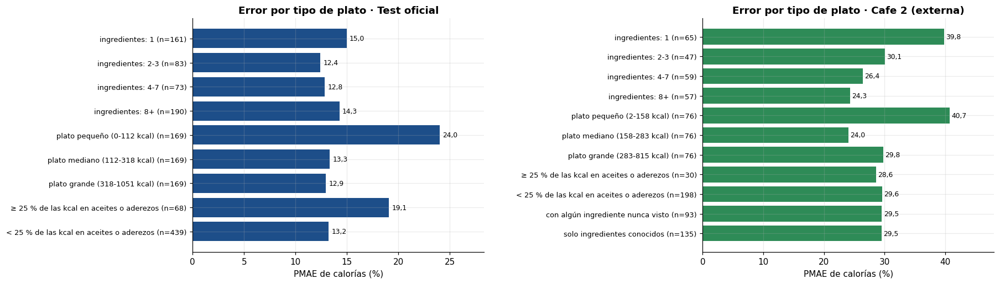

In [45]:
with fase('16. Análisis de errores', opcional=True):
    filas = []
    def agregar(g, nombre, m, y, err):
        if m.sum() >= 5:
            filas.append(dict(conjunto=GRUPO_ES[g], grupo=nombre, n=int(m.sum()),
                              PMAE_kcal=100 * err[m].mean() / y[m, 0].mean(), MAE_kcal=err[m].mean()))
    for g in ('TE', 'C2'):
        fil = FUENTES['cenital'].indices(g)
        pl = CEN_PLATO[fil]
        y, p = Y_CEN[fil], E_P['pred'][g]
        err = np.abs(p[:, 0] - y[:, 0])
        n_ingr = PLATOS.n_ingr.values[pl]
        for nb, m in [('1', n_ingr == 1), ('2-3', (n_ingr >= 2) & (n_ingr <= 3)), ('4-7', (n_ingr >= 4) & (n_ingr <= 7)),
                      ('8+', n_ingr >= 8)]:
            agregar(g, f'ingredientes: {nb}', m, y, err)
        q = np.quantile(y[:, 0], [0, 1 / 3, 2 / 3, 1])
        for k, nb in enumerate(['plato pequeño', 'plato mediano', 'plato grande']):
            agregar(g, f'{nb} ({q[k]:.0f}-{q[k + 1]:.0f} kcal)', (y[:, 0] >= q[k]) & (y[:, 0] <= q[k + 1]), y, err)
        fi = PLATOS.frac_invisible.values[pl]
        agregar(g, '≥ 25 % de las kcal en aceites o aderezos', fi >= 0.25, y, err)
        agregar(g, '< 25 % de las kcal en aceites o aderezos', fi < 0.25, y, err)
        if g == 'C2':
            nuevo = PLATOS.ingr_nuevo.values[pl].astype(bool)
            agregar(g, 'con algún ingrediente nunca visto', nuevo, y, err)
            agregar(g, 'solo ingredientes conocidos', ~nuevo, y, err)
    TAB_ERR = pd.DataFrame(filas)
    TAB_ERR.to_csv(TAB / '05_errores_por_grupo.csv', index=False)
    fig, axs = plt.subplots(1, 2, figsize=(17, 5))
    fig.subplots_adjust(wspace=0.75)
    for ax, g in zip(axs, ('TE', 'C2')):
        t_ = TAB_ERR[TAB_ERR.conjunto == GRUPO_ES[g]]
        yy = np.arange(len(t_))[::-1]
        ax.barh(yy, t_.PMAE_kcal, color=COL['azul'] if g == 'TE' else COL['verde'])
        ax.set_yticks(yy); ax.set_yticklabels([f'{a} (n={n})' for a, n in zip(t_.grupo, t_.n)], fontsize=8.5)
        for yi, v in zip(yy, t_.PMAE_kcal):
            ax.text(v + 0.3, yi, coma(v), va='center', fontsize=8)
        ax.set_xlim(0, t_.PMAE_kcal.max() * 1.18)
        ax.set_xlabel('PMAE de calorías (%)'); ax.set_title(f'Error por tipo de plato · {GRUPO_ES[g]}')
    guardar_fig(fig, '14_errores_por_grupo')

**Lectura:** en el test, el error es mayor en los platos pequeños (24,0 % en los de hasta 112 kcal, contra 12,9–13,3 % en los medianos y grandes) y en los platos donde el aceite o los aderezos aportan al menos un cuarto de las calorías (19,1 % frente a 13,2 %). Por número de ingredientes, el error va de 12,4 a 15,0 %. En la Cafe 2, el error baja a medida que el plato tiene más ingredientes (39,8 % con uno, 24,3 % con ocho o más) y es de 40,7 % en los platos pequeños; en cambio no cambia entre los platos con algún ingrediente nunca visto y los demás (29,5 % en ambos), ni entre los de mucho aceite y los demás. El fallo de la Cafe 2 es por tanto general, y no se explica por los ingredientes nuevos.

### Cambio de vista: ¿sirve un modelo entrenado con una vista en la otra?

Cada fila es con qué se entrenó y cada columna con qué se evalúa. Simula qué pasa si el usuario toma la foto desde otro ángulo.


17. Cruce de vistas   (minuto 547, quedan 113 min)


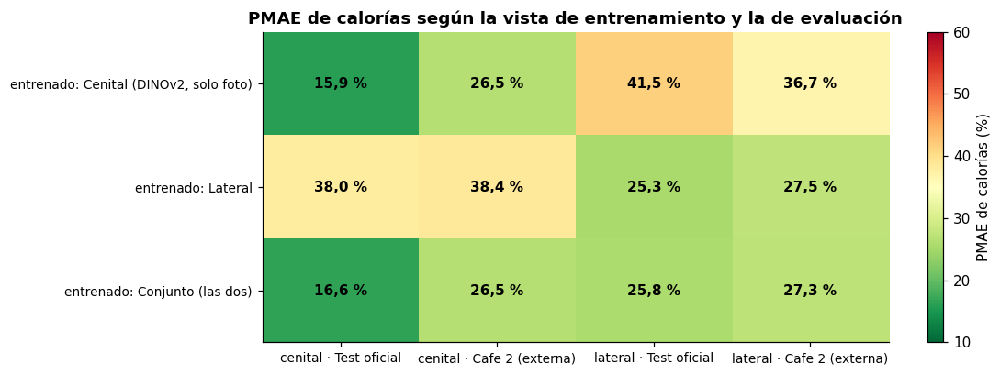

In [46]:
with fase('17. Cruce de vistas', opcional=True):
    if not ACTIVO['lateral']:
        raise RuntimeError('no hay datos laterales')
    filas_m = {}
    for etiqueta, n in [('Cenital (DINOv2, solo foto)', nombre_p(False, 1)), ('Lateral', 'v2 · Lateral · s1'),
                        ('Conjunto (las dos)', 'v2 · Conjunto · s1')]:
        if n not in RES:
            continue
        fila = {}
        for vista in ('cenital', 'lateral'):
            for g in ('TE', 'C2'):
                p = pred_conjunto(RES[n], vista, g)
                if p is not None and len(p):
                    fila[f'{vista} · {GRUPO_ES[g]}'] = pmae(y_conjunto(vista, g), p)[0]
        filas_m[etiqueta] = fila
    TAB_VISTAS = pd.DataFrame(filas_m).T
    TAB_VISTAS.to_csv(TAB / '06_cruce_de_vistas.csv')
    fig, ax = plt.subplots(figsize=(10, 0.8 * len(TAB_VISTAS) + 1.6))
    im = ax.imshow(TAB_VISTAS.values, cmap='RdYlGn_r', vmin=10, vmax=60, aspect='auto')
    for i in range(TAB_VISTAS.shape[0]):
        for j in range(TAB_VISTAS.shape[1]):
            v = TAB_VISTAS.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f'{coma(v)} %', ha='center', va='center', fontsize=10, fontweight='bold')
    ax.set_xticks(range(TAB_VISTAS.shape[1])); ax.set_xticklabels(TAB_VISTAS.columns, fontsize=9)
    ax.set_yticks(range(TAB_VISTAS.shape[0])); ax.set_yticklabels([f'entrenado: {i}' for i in TAB_VISTAS.index], fontsize=9)
    ax.grid(False); fig.colorbar(im, ax=ax, label='PMAE de calorías (%)')
    ax.set_title('PMAE de calorías según la vista de entrenamiento y la de evaluación')
    guardar_fig(fig, '15_cruce_vistas')

**Lectura:** cada modelo funciona bien solo en la vista donde se entrenó. El modelo entrenado con foto cenital tiene 15,9 % de error en el test cenital y 41,5 % en el lateral; el entrenado con fotogramas laterales, 25,3 % en el lateral y 38,0 % en el cenital. El modelo entrenado con las dos vistas casi no pierde frente al especialista en cada una (16,6 % en cenital y 25,8 % en lateral). En la Cafe 2, las dos vistas dan entre 26,5 y 27,5 % con los modelos de una vista que corresponde a su entrenamiento, y 36,7 y 38,4 % cuando la vista no coincide.

## 25. Intervalos del 90 % y adaptación a una cafetería nueva

Primero, la cobertura de los intervalos calibrados en la Cafe 1 (VC). Una buena cobertura está cerca del 90 %; si cae mucho, el modelo está demasiado confiado con esos datos.


18. Intervalos conformales   (minuto 547, quedan 113 min)


,ensamble,conjunto,objetivo,cobertura,ancho_medio
0,Solo foto,Test oficial,Calorías,94.7,221.6
1,Solo foto,Test oficial,Carbohidratos,88.4,17.4
2,Solo foto,Cafe 2 (externa),Calorías,80.7,213.0
3,Solo foto,Cafe 2 (externa),Carbohidratos,57.5,14.0
4,Foto + profundidad estimada,Test oficial,Calorías,95.3,224.4
5,Foto + profundidad estimada,Test oficial,Carbohidratos,88.6,17.6
6,Foto + profundidad estimada,Cafe 2 (externa),Calorías,80.3,215.9
7,Foto + profundidad estimada,Cafe 2 (externa),Carbohidratos,58.8,14.3
8,Foto + sensor,Test oficial,Calorías,94.5,200.5
9,Foto + sensor,Test oficial,Carbohidratos,88.0,16.6


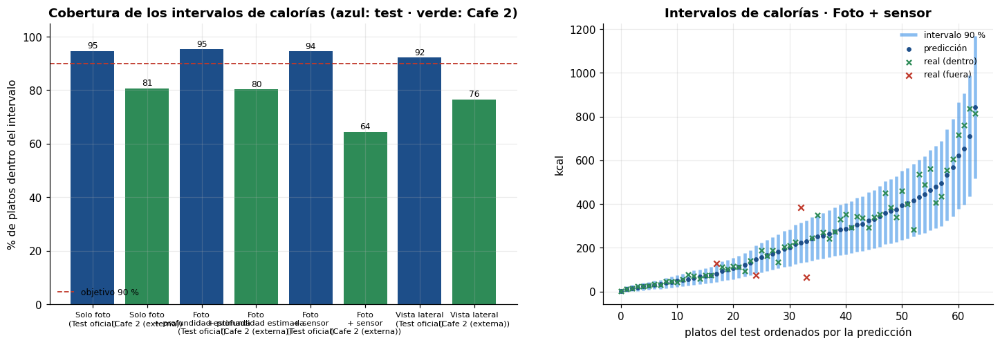

In [47]:
with fase('18. Intervalos conformales', opcional=True):
    c_ = 0.1 * MEDIAS
    filas, EJ_INT, Q_VC, S_VC = [], {}, {}, {}
    for clave, e in ENS.items():
        vista = e['vista']
        ycal, pcal = y_conjunto(vista, 'VC'), e['pred']['VC']
        Q_VC[clave] = q_rel = cuantil_conformal(ycal, pcal, CFG['alpha'], c_)
        S_VC[clave] = np.median(np.abs(ycal - pcal) / (pcal + c_), 0)     # error típico en casa (para escalar el intervalo)
        for g in ('TE', 'C2'):
            y = y_conjunto(vista, g)
            if len(y) == 0:
                continue
            p = e['pred'][g]
            lo, hi = intervalo(p, q_rel, c_)
            for j in (0, 3):
                filas.append(dict(ensamble=clave, conjunto=GRUPO_ES[g], objetivo=OBJ_ES[j],
                                  cobertura=100 * np.mean((y[:, j] >= lo[:, j]) & (y[:, j] <= hi[:, j])),
                                  ancho_medio=np.mean(hi[:, j] - lo[:, j])))
            EJ_INT[(clave, g)] = (y, p, lo, hi)
    TAB_INT = pd.DataFrame(filas)
    TAB_INT.to_csv(TAB / '07_intervalos.csv', index=False)
    display(TAB_INT.round(1))
    t_ = TAB_INT[TAB_INT.objetivo == 'Calorías']
    fig, axs = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.2, 1]})
    x = np.arange(len(t_))
    b = axs[0].bar(x, t_.cobertura, color=[COL['azul'] if c == GRUPO_ES['TE'] else COL['verde'] for c in t_.conjunto])
    etiquetar_barras(axs[0], b, '{:.0f}', size=8)
    axs[0].axhline(90, color=COL['rojo'], ls='--', lw=1.2, label='objetivo 90 %')
    axs[0].set_xticks(x)
    axs[0].set_xticklabels([f'{a.replace(" + ", chr(10) + "+ ")}\n({b_})' for a, b_ in zip(t_.ensamble, t_.conjunto)], fontsize=7.5)
    axs[0].set_ylabel('% de platos dentro del intervalo'); axs[0].set_ylim(0, 105)
    axs[0].set_title('Cobertura de los intervalos de calorías (azul: test · verde: Cafe 2)'); axs[0].legend(fontsize=8, loc='lower left')
    y, p, lo, hi = EJ_INT[(clave_p, 'TE')]
    o = np.argsort(p[:, 0])[::max(1, len(p) // 60)]
    xs = np.arange(len(o))
    dentro = (y[o, 0] >= lo[o, 0]) & (y[o, 0] <= hi[o, 0])
    axs[1].vlines(xs, lo[o, 0], hi[o, 0], color=COL['celeste'], lw=3, alpha=0.6, label='intervalo 90 %')
    axs[1].scatter(xs, p[o, 0], color=COL['azul'], s=12, label='predicción', zorder=3)
    axs[1].scatter(xs[dentro], y[o, 0][dentro], color=COL['verde'], marker='x', s=22, label='real (dentro)', zorder=4)
    axs[1].scatter(xs[~dentro], y[o, 0][~dentro], color=COL['rojo'], marker='x', s=30, label='real (fuera)', zorder=4)
    axs[1].set_xlabel('platos del test ordenados por la predicción'); axs[1].set_ylabel('kcal')
    axs[1].set_title(f'Intervalos de calorías · {clave_p}'); axs[1].legend(fontsize=8)
    guardar_fig(fig, '16_intervalos')

**Lectura:** los intervalos del 90 % cubren entre 92 y 95 % de los platos del test en calorías (94,7 % solo foto, 95,3 % con profundidad estimada, 94,5 % con sensor, 92,2 % en la vista lateral), un poco por encima de lo nominal. En carbohidratos cubren 88–89 %, apenas por debajo. En la Cafe 2 la cobertura en calorías cae a 80,7 % (solo foto), 80,3 % (profundidad estimada), 76,5 % (lateral) y 64,5 % (con sensor); en carbohidratos, a 53–59 %. Los anchos medios en calorías son de 165 a 224 kcal en el test.

### Adaptación con pocos platos de la Cafe 2

¿Qué pasa si la cafetería nueva pesa unos pocos platos para calibrar el sistema? Con *k* platos de *k* cadenas distintas se corrige el sesgo y el intervalo, y luego se mide el error en las demás cadenas de la Cafe 2. *k* = 0 es usar el modelo tal cual. Aquí sí se usan etiquetas de la Cafe 2, pero solo las de esos *k* platos, y siempre se evalúa en platos que no se usaron ni son escaneos del mismo plato.

En la cobertura y el ancho, la línea continua es el cuantil conformal recalculado con los *k* platos y la punteada es el intervalo de la Cafe 1 escalado (sección 10).


19. Adaptación con pocos platos locales   (minuto 547, quedan 113 min)


pmae_kcal       pmae_masa       pmae_carb  \
                                    mean   std      mean   std      mean   
ensamble                    k                                              
Foto + profundidad estimada 0      26.15   NaN     19.75   NaN     53.02   
                            5      26.66  0.74     19.87  0.51     53.41   
                            10     26.71  0.77     19.91  0.61     53.40   
                            20     26.69  0.93     19.90  0.65     52.96   
                            40     26.58  1.29     19.79  0.80     52.73   
Foto + sensor               0      29.54   NaN     19.96   NaN     50.79   
                            5      28.79  1.83     18.63  1.53     51.53   
                            10     28.28  1.59     17.81  1.26     51.75   
                            20     27.77  1.44     17.12  1.00     51.48   
                            40     27.33  1.49     16.72  0.89     51.33   
Solo foto                   0      26.00   NaN     19.71   NaN     52.64   
                            5      26.50  0.73     19.80  0.51     53.14   
                            10     26.53  0.73     19.83  0.60     53.14   
                            20     26.51  0.90     19.83  0.63     52.74   
                            40     26.41  1.24     19.72  0.83     52.53   

                                     cobertura_kcal       ancho_kcal          \
                                 std           mean   std       mean     std   
ensamble                    k                                                  
Foto + profundidad estimada 0    NaN          80.26   NaN     215.94     NaN   
                            5   2.48          79.35  3.18     215.69   12.02   
                            10  2.57          91.03  9.27     422.22  169.53   
                            20  2.18          90.07  7.37     366.20  117.77   
                            40  2.57          90.67  5.37     349.91   79.70   
Foto + sensor               0    NaN          64.47   NaN     169.89     NaN   
                            5   1.24          65.49  4.60     176.14   10.11   
                            10  1.65          90.28  9.19     430.27  199.53   
                            20  1.50          89.57  7.25     366.92   97.16   
                            40  2.15          89.94  5.42     348.64   64.24   
Solo foto                   0    NaN          80.70   NaN     213.05     NaN   
                            5   2.45          79.14  3.37     213.16   11.73   
                            10  2.52          91.35  9.02     423.28  164.40   
                            20  2.11          90.37  7.24     370.06  116.20   
                            40  2.51          90.88  5.17     355.67   81.73   

                               cobertura_esc_kcal        ancho_esc_kcal  \
                                             mean    std           mean   
ensamble                    k                                             
Foto + profundidad estimada 0               80.26    NaN         215.94   
                            5               92.41   6.36         428.79   
                            10              93.11   5.70         427.76   
                            20              94.35   3.91         444.91   
                            40              95.48   2.35         468.27   
Foto + sensor               0               64.47    NaN         169.89   
                            5               89.82  10.36         423.56   
                            10              92.51   6.70         434.37   
                            20              94.07   4.10         441.30   
                            40              95.36   2.68         459.39   
Solo foto                   0               80.70    NaN         213.05   
                            5               91.37   7.01         407.52   
                            10              92.13   6.23         404.69   
                     

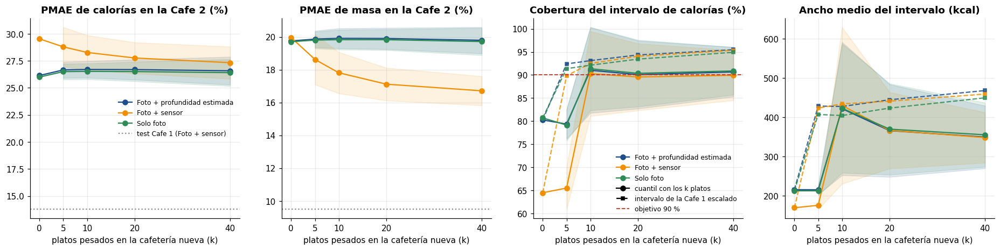

In [48]:
with fase('19. Adaptación con pocos platos locales', opcional=True):
    c_ = 0.1 * MEDIAS
    ad = []
    for clave, e in ENS.items():
        if e['vista'] != 'cenital':
            continue
        y, p = y_conjunto('cenital', 'C2'), e['pred']['C2']
        d = adaptacion_local(y, p, Q_VC[clave], S_VC[clave], c_, CFG['k_local'], CFG['rep_local'], cadenas_de('cenital', 'C2'))
        d['ensamble'] = clave
        ad.append(d)
    AD = pd.concat(ad)
    TAB_ADAPT = AD.groupby(['ensamble', 'k']).agg(['mean', 'std']).round(2)
    TAB_ADAPT.to_csv(TAB / '08_adaptacion_local.csv')
    display(TAB_ADAPT)
    fig, axs = plt.subplots(1, 4, figsize=(21, 4.4))
    for i, (clave, d) in enumerate(AD.groupby('ensamble')):
        d = d.drop(columns='ensamble')
        m, s = d.groupby('k').mean(), d.groupby('k').std()
        c = PALETA[i]
        for ax, col in zip(axs, ('pmae_kcal', 'pmae_masa', 'cobertura_kcal', 'ancho_kcal')):
            ax.plot(m.index, m[col], '-o', color=c, label=clave)
            ax.fill_between(m.index, m[col] - s[col], m[col] + s[col], color=c, alpha=0.12)
        for ax, col in ((axs[2], 'cobertura_esc_kcal'), (axs[3], 'ancho_esc_kcal')):
            ax.plot(m.index, m[col], '--s', color=c, ms=4, alpha=0.85)
    axs[2].plot([], [], 'k-o', label='cuantil con los k platos')
    axs[2].plot([], [], 'k--s', ms=4, label='intervalo de la Cafe 1 escalado')
    te = TAB_FINAL[(TAB_FINAL.conjunto == GRUPO_ES['TE']) & (TAB_FINAL.modelo == f'Ensamble · {clave_p}')]
    if len(te):
        axs[0].axhline(te.PMAE_kcal.iloc[0], color=COL['gris'], ls=':', label=f'test Cafe 1 ({clave_p})')
        axs[1].axhline(te.PMAE_masa.iloc[0], color=COL['gris'], ls=':')
    axs[2].axhline(90, color=COL['rojo'], ls='--', lw=1.2, label='objetivo 90 %')
    for ax, tit in zip(axs, ('PMAE de calorías en la Cafe 2 (%)', 'PMAE de masa en la Cafe 2 (%)',
                             'Cobertura del intervalo de calorías (%)', 'Ancho medio del intervalo (kcal)')):
        ax.set_xlabel('platos pesados en la cafetería nueva (k)'); ax.set_title(tit); ax.set_xticks(CFG['k_local'])
    axs[0].legend(fontsize=8); axs[2].legend(fontsize=8)
    guardar_fig(fig, '17_adaptacion_local')

**Lectura:** con el ensamble de foto y sensor, corregir la escala con *k* platos de la Cafe 2 baja el error de calorías de 29,5 % (*k* = 0) a 28,8 % (*k* = 5), 27,8 % (20) y 27,3 % (40), y el de masa de 20,0 a 17,1 % con 20 platos. Con solo foto, el error casi no cambia (26,0 a 26,5 %). Si el cuantil conformal se recalcula con los *k* platos, la cobertura sube de 64,5 % a 90 % con 10 platos o más, a cambio de intervalos mucho más anchos (de 170 a 367 kcal con 20 platos). Si en cambio se escala el cuantil de la Cafe 1, la cobertura sube a 94 % con 20 platos y a 95 % con 40, con intervalos de ≈ 440–460 kcal. Con 5 platos el cuantil recalculado no alcanza a corregir la cobertura (65,5 %). Pesar unos 10 a 20 platos corrige entonces el sesgo y la cobertura, pero no el error de cada plato.

### Reentrenar con pocos platos de la Cafe 2

Corregir la escala arregla el sesgo, pero no el error de cada plato. Aquí se prueba si sirve **reentrenar** con los mismos *k* platos pesados (10, 20 o 40, de cadenas distintas), de dos maneras:
- **Solo la cabeza**, con la red congelada: unos 400 mil parámetros. Es lo más seguro con tan pocos datos.
- **La red completa**, con el 30 % de la tasa de aprendizaje original: 86 M parámetros. Puede aprender más, pero también deformar lo que ya sabía (Kumar et al., 2022).

Cada reajuste son 40 pasos con aumento de datos, a partir del mejor DINOv2 de este notebook (solo foto y con sensor). Se repite con 3 particiones distintas y se compara, en los mismos platos, con no hacer nada y con el factor de escala. No hay validación para escoger épocas: la cafetería nueva solo tiene esos *k* platos. Es el mismo problema de adaptar un modelo entrenado en un lugar con muy pocos datos del lugar nuevo.


19b. Reentrenar con pocos platos   (minuto 547, quedan 113 min)
36 reajustes cortos en cola (minuto 547); modelos base: {'Solo foto': 'v2 · DINOv2 ViT-B/14 · Solo foto + aumento fuerte · s1', 'Foto + sensor': 'v2 · DINOv2 ViT-B/14 · Sensor (plano fijo) · s2'}
36 de 36 reajustes terminados (minuto 558)


pmae_kcal       pmae_masa        \
                                                 mean   std      mean   std   
modelo        metodo                     k                                    
Foto + sensor Factor de escala           10     27.45  1.18     18.07  0.28   
                                         20     27.57  1.07     19.32  1.01   
                                         40     28.30  2.85     17.85  0.61   
              Reentrenar la cabeza       10     29.96  1.88     19.63  1.22   
                                         20     26.14  0.36     18.62  0.29   
                                         40     25.58  2.98     18.74  1.33   
              Reentrenar la red completa 10     29.38  2.94     19.50  0.11   
                                         20     25.94  1.06     17.43  1.58   
                                         40     23.79  1.99     16.07  1.07   
              Sin ajuste                 10     30.54  0.63     22.09  0.25   
                                         20     31.12  0.95     22.54  0.39   
                                         40     29.91  0.25     21.91  0.41   
Solo foto     Factor de escala           10     26.58  0.40     20.52  0.72   
                                         20     27.62  0.97     22.04  1.19   
                                         40     27.11  1.62     21.19  0.55   
              Reentrenar la cabeza       10     29.17  1.36     21.79  1.40   
                                         20     27.49  0.59     24.44  1.16   
                                         40     27.04  2.49     21.85  0.59   
              Reentrenar la red completa 10     28.62  1.56     22.76  1.22   
                                         20     26.29  0.96     22.87  0.28   
                                         40     25.54  1.79     21.40  0.51   
              Sin ajuste                 10     26.64  0.49     20.49  0.62   
                                         20     27.19  0.63     21.47  0.27   
                                         40     26.08  0.24     21.26  0.52   

                                            pmae_carb       sesgo_kcal         
                                                 mean   std       mean    std  
modelo        metodo                     k                                     
Foto + sensor Factor de escala           10     52.64  2.80      -4.39   7.16  
                                         20     52.76  0.68      -6.94   3.15  
                                         40     50.26  2.37     -13.71  11.64  
              Reentrenar la cabeza       10     54.60  1.54       2.13  11.01  
                                         20     52.36  1.34      -6.70   2.70  
                                         40     50.35  3.28      -9.26   9.85  
              Reentrenar la red completa 10     55.59  5.29       6.26   8.98  
                                         20     50.90  1.28      -0.76   1.64  
                                         40     47.66  4.11      -5.13  10.54  
              Sin ajuste                 10     50.49  1.59     -19.43   1.23  
                                         20     51.15  0.79     -20.33   0.64  
                                         40     49.17  1.60     -20.44   3.33  
Solo foto     Factor de escala           10     53.88  2.96      -1.63   2.83  
                                         20     55.89  3.43       2.43   4.15  
                                         40     53.40  2.35      -9.99  11.91  
              Reentrenar la cabeza       10     54.34  3.31      -0.19   6.63  
                                         20     56.41  3.31       2.51   0.17  
                                         40     50.86  4.77      -6.18  12.34  
              Reentrenar la red completa 10     54.98  3.07       1.28   5.59  
                                         20     53.90  1.65       2.21   3.04  
                                         40     49.42  2.00      -4.51

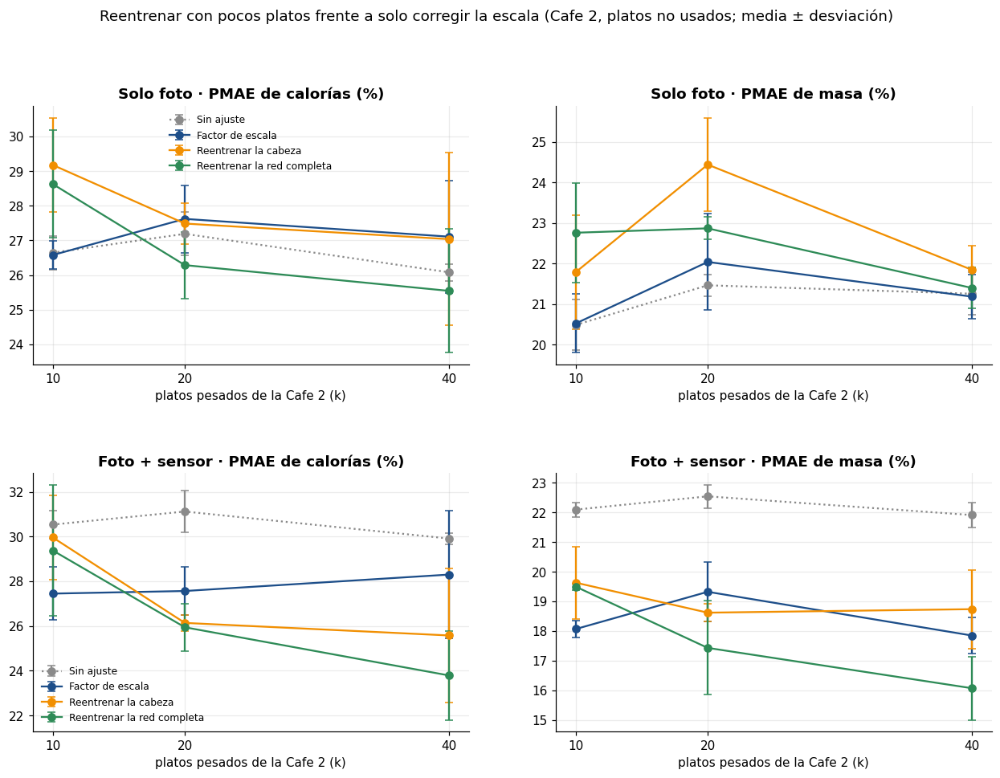

In [49]:
def bases_ajuste():
    """Mejor DINOv2 de la v2 (por validación) de cada entrada, con sus pesos en memoria."""
    out = {}
    for etiqueta, prof in [('Solo foto', False), ('Foto + sensor', PROF_SENSOR)]:
        c = [n for n, r in RES.items() if r.get('estado') is not None and r['t']['bb'] == 'dinov2_b'
             and r['t']['fuentes'] == ['cenital'] and r['t'].get('prof', False) == prof]
        if prof is not None and c:
            out[etiqueta] = min(c, key=lambda n: RES[n]['val'])
    return out

def receta_ajuste(n, modo, cal, resto, rep, fil):
    """Reajuste corto del modelo n con los platos cal; predice en resto (índices dentro de fil)."""
    base = RES[n]['t']
    return dict(base, nombre=f'ajuste · {modo} · {n} · k{len(cal)} · r{rep}', semilla=100 + rep, init=RES[n]['estado'],
                congelar=(modo == 'cabeza'), ajuste=True, pred_lateral=False, fuentes=['cenital'],
                micro=RES[n].get('micro') or CFG['lote'], lr=BACKBONES[base['bb']]['lr'] * 0.3,
                lr_cab=3e-4 if modo == 'cabeza' else 1e-4, _fuentes={'cenital': fuente_local(fil[cal], fil[resto])})

AJ = None
with fase('19b. Reentrenar con pocos platos', opcional=True):
    if not ACTIVO['ajuste']:
        raise RuntimeError('desactivado en la prueba de humo')
    bases = bases_ajuste()
    if not bases:
        raise RuntimeError('no hay un DINOv2 de la v2 con sus pesos en memoria')
    fil_c2 = FUENTES['cenital'].indices('C2')
    y_c2, cad_c2 = Y_CEN[fil_c2], cadenas_de('cenital', 'C2')
    rng_a = np.random.default_rng(11)
    PARTS = [(k, rep, *particion_local(cad_c2, k, rng_a)) for k in CFG['k_ajuste'] for rep in range(CFG['rep_ajuste'])]
    trab = [receta_ajuste(n, modo, cal, resto, rep, fil_c2) for k, rep, cal, resto in PARTS
            for n in bases.values() for modo in ('cabeza', 'completo')]
    print(f'{len(trab)} reajustes cortos en cola (minuto {minutos():.0f}); modelos base: {bases}')
    hechos = {h['nombre']: h for h in correr_trabajos(trab, registrar=False, epocas=CFG['ajuste_pasos'], verbose=False)
              if 'error' not in h}
    print(f'{len(hechos)} de {len(trab)} reajustes terminados (minuto {minutos():.0f})')
    c_ = 0.1 * MEDIAS
    filas = []
    for etiqueta, n in bases.items():
        p_c2 = RES[n]['pred'][('cenital', 'C2')]
        for k, rep, cal, resto in PARTS:
            y_r = y_c2[resto]
            metodos = {'Sin ajuste': p_c2[resto], 'Factor de escala': p_c2[resto] * factor_local(y_c2[cal], p_c2[cal], c_)}
            for modo, et in (('cabeza', 'Reentrenar la cabeza'), ('completo', 'Reentrenar la red completa')):
                h = hechos.get(f'ajuste · {modo} · {n} · k{len(cal)} · r{rep}')
                if h is not None:
                    metodos[et] = h['pred'][('cenital', 'C2')]
            for et, pr in metodos.items():
                pm = pmae(y_r, pr)
                filas.append(dict(modelo=etiqueta, k=k, rep=rep, metodo=et, pmae_kcal=pm[0], pmae_masa=pm[1],
                                  pmae_carb=pm[3], sesgo_kcal=100 * (pr[:, 0].sum() / y_r[:, 0].sum() - 1)))
    AJ = pd.DataFrame(filas)
    TAB_AJUSTE = AJ.groupby(['modelo', 'metodo', 'k'])[['pmae_kcal', 'pmae_masa', 'pmae_carb', 'sesgo_kcal']].agg(['mean', 'std'])
    TAB_AJUSTE.round(2).to_csv(TAB / '08b_reentrenar_pocos_platos.csv')
    display(TAB_AJUSTE.round(2))
    METODOS_AJ = {'Sin ajuste': (COL['gris'], ':'), 'Factor de escala': (COL['azul'], '-'),
                  'Reentrenar la cabeza': (COL['naranja'], '-'), 'Reentrenar la red completa': (COL['verde'], '-')}
    mods = list(bases)
    fig, axs = plt.subplots(len(mods), 2, figsize=(14, 4.6 * len(mods)), squeeze=False)
    fig.subplots_adjust(hspace=0.42)
    for i, etq in enumerate(mods):
        d = AJ[AJ.modelo == etq]
        for jcol, (col, tit) in enumerate([('pmae_kcal', 'PMAE de calorías (%)'), ('pmae_masa', 'PMAE de masa (%)')]):
            ax = axs[i, jcol]
            for met, (c, ls) in METODOS_AJ.items():
                g_ = d[d.metodo == met].groupby('k')[col]
                if len(d[d.metodo == met]):
                    ax.errorbar(g_.mean().index, g_.mean().values, yerr=g_.std().fillna(0).values, color=c, ls=ls,
                                marker='o', capsize=3, label=met)
            ax.set_xticks(CFG['k_ajuste']); ax.set_xlabel('platos pesados de la Cafe 2 (k)')
            ax.set_title(f'{etq} · {tit}')
        axs[i, 0].legend(fontsize=8)
    fig.suptitle('Reentrenar con pocos platos frente a solo corregir la escala (Cafe 2, platos no usados; media ± desviación)', y=1.0)
    guardar_fig(fig, '17b_reentrenar_pocos_platos')

**Lectura:** el error de calorías en el resto de la Cafe 2 (promedio de 3 particiones) con *k* = 10, 20 y 40 platos reentrenados. Con el modelo de foto y sensor: sin ajuste, 30,5, 31,1 y 29,9 %; con factor de escala, 27,5, 27,6 y 28,3 %; reentrenando solo la cabeza, 30,0, 26,1 y 25,6 %; reentrenando la red completa, 29,4, 25,9 y 23,8 %. Con el modelo de solo foto: sin ajuste, 26,6, 27,2 y 26,1 %; factor de escala, 26,6, 27,6 y 27,1 %; cabeza, 29,2, 27,5 y 27,0 %; red completa, 28,6, 26,3 y 25,5 %. Con 10 platos reentrenar no ayuda; con 20 platos la red completa gana algo (25,9 % frente a 27,6 % del factor, en el modelo con sensor); con 40 platos es la mejor opción en ambos modelos, y corrige además el sesgo del modelo con sensor (de −20 % sin ajuste a −5 % con 40 platos). La desviación entre particiones va de 0,2 a 3 puntos, así que las diferencias de 1 punto o menos no son concluyentes. La red completa no salió peor que la cabeza sola, a diferencia de lo que Kumar et al. (2022) observaron al cambiar de dominio.

### Los platos con más error

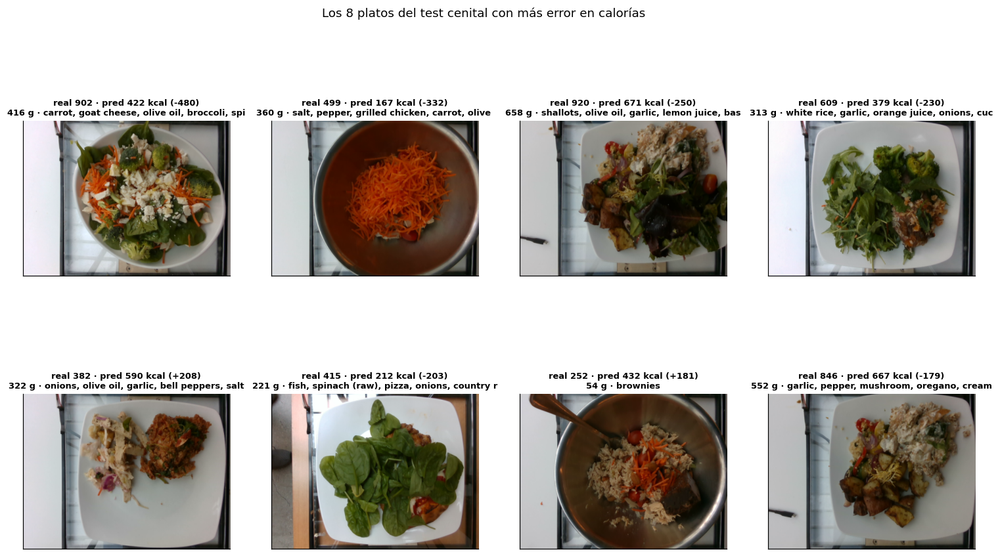

In [50]:
fil = FUENTES['cenital'].indices('TE')
y, p = Y_CEN[fil], E_P['pred']['TE']
err = p[:, 0] - y[:, 0]
peores = np.argsort(-np.abs(err))[:8]
fig, axs = plt.subplots(2, 4, figsize=(17, 9))
for ax, k in zip(axs.ravel(), peores):
    c = fil[k]; pl = CEN_PLATO[c]
    ax.imshow(CEN_RGB[c].transpose(1, 2, 0)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ingr = ', '.join(PLATOS.ingredientes.iat[pl][:5])
    ax.set_title(f'real {y[k, 0]:.0f} · pred {p[k, 0]:.0f} kcal ({err[k]:+.0f})\n{y[k, 1]:.0f} g · {ingr[:45]}', fontsize=8.5)
fig.suptitle('Los 8 platos del test cenital con más error en calorías', y=1.0)
guardar_fig(fig, '18_peores')

**Lectura:** seis de los ocho platos con más error son subestimaciones, entre −179 y −480 kcal. El peor (902 kcal reales, 422 predichas) es una ensalada con queso de cabra y aceite de oliva; el segundo (499 kcal, 167 predichas) es zanahoria rallada en un bol cuya etiqueta incluye pollo, aceite y otros ingredientes que no se ven. En los platos grandes y mezclados se acumulan ingredientes ocultos. El plato de 252 kcal que el modelo sobreestima en 181 kcal figura como brownies de 54 g, pero la foto muestra arroz con verduras: la etiqueta parece no corresponder a la imagen.

### Grad-CAM: dónde mira el modelo

Se usa el mejor ConvNeXt-S en la validación. Para cada plato se muestran las zonas que usa para las calorías y para la masa.


20. Grad-CAM   (minuto 558, quedan 102 min)


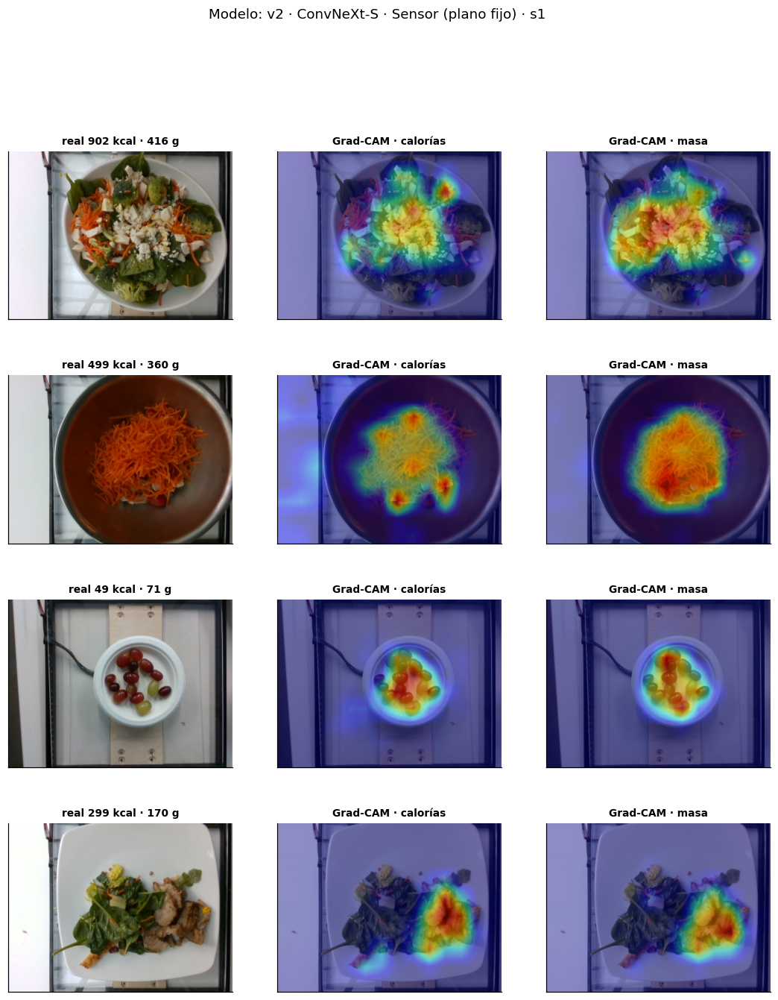

In [51]:
with fase('20. Grad-CAM', opcional=True):
    if not ACTIVO['gradcam']:
        raise RuntimeError('desactivado en la prueba de humo')
    cands_g = [n for n, r in RES.items() if r.get('estado') is not None and r['t']['bb'] == 'convnext_s']
    if not cands_g:
        raise RuntimeError('no hay un ConvNeXt-S cenital entrenado')
    n_g = min(cands_g, key=lambda n: RES[n]['val'])
    m = modelo_desde(RES[n_g], DEV)
    sel = fil[np.r_[peores[:2], np.argsort(np.abs(err))[:2]]]
    fig, axs = plt.subplots(len(sel), 3, figsize=(12, 3.4 * len(sel)))
    for i, c in enumerate(sel):
        rgb, extra, _, _ = FUENTES['cenital'].tomar(np.array([c]), DEV, m.canal)
        img = CEN_RGB[c].transpose(1, 2, 0)
        axs[i, 0].imshow(img); axs[i, 0].set_title(f'real {Y_CEN[c, 0]:.0f} kcal · {Y_CEN[c, 1]:.0f} g', fontsize=9)
        for k, (j, nom) in enumerate([(0, 'calorías'), (1, 'masa')]):
            cam = gradcam(m, rgb, extra, j)[0]
            axs[i, 1 + k].imshow(img); axs[i, 1 + k].imshow(cam, cmap='jet', alpha=0.45)
            axs[i, 1 + k].set_title(f'Grad-CAM · {nom}', fontsize=9)
    for a in axs.ravel():
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
    fig.suptitle(f'Modelo: {n_g}', y=1.0)
    guardar_fig(fig, '19_gradcam')
    del m

**Lectura:** el modelo mira la comida y no el plato ni la mesa, y las zonas que usa para calorías y para masa casi coinciden. En el cuarto plato (299 kcal), solo se marca la porción de la derecha y se ignora la espinaca de la izquierda, que tiene menos calorías por gramo. Es una evidencia cualitativa de dónde se apoya la predicción, no una prueba de que sea correcta.

### ¿Qué tan sensible es a cómo se toma la foto? Prueba de estrés

Las fotos del test se alteran una a la vez (luz, color, desenfoque, compresión, giro y distancia de la cámara) y se vuelven a predecir con el mismo modelo, sin reentrenarlo y sin TTA. Se prueban tres modelos de solo foto: el mejor DINOv2 y el mejor ConvNeXt-S, es decir, un *transformer* y una CNN, y el DINOv2 entrenado con aumento fuerte, para ver si entrenar con fotos alteradas lo hace más robusto. A la izquierda, cuánto sube el error frente a la foto original; a la derecha, cuánto cambia en promedio la estimación de calorías del mismo plato.


20b. Prueba de estrés   (minuto 558, quedan 102 min)


,red,alteracion,pmae_kcal,pmae_masa,aumento_pmae_kcal,cambio_kcal
0,DINOv2 ViT-B/14,original,15.86,11.99,0.00,0.00
1,DINOv2 ViT-B/14,30 % más oscura,15.81,11.90,-0.04,0.23
2,DINOv2 ViT-B/14,30 % más clara,15.68,12.06,-0.18,0.42
3,DINOv2 ViT-B/14,luz cálida,15.82,12.17,-0.04,0.64
4,DINOv2 ViT-B/14,luz fría,16.06,11.93,0.20,-0.14
5,DINOv2 ViT-B/14,desenfoque (σ = 2 px),18.63,12.40,2.77,-5.00
6,DINOv2 ViT-B/14,JPEG calidad 20,18.03,12.77,2.17,0.54
7,DINOv2 ViT-B/14,girada 10°,16.20,12.25,0.34,0.07
8,DINOv2 ViT-B/14,cámara 10 % más cerca,17.04,16.18,1.19,11.35
9,DINOv2 ViT-B/14,cámara 10 % más lejos,19.73,15.08,3.88,-10.02


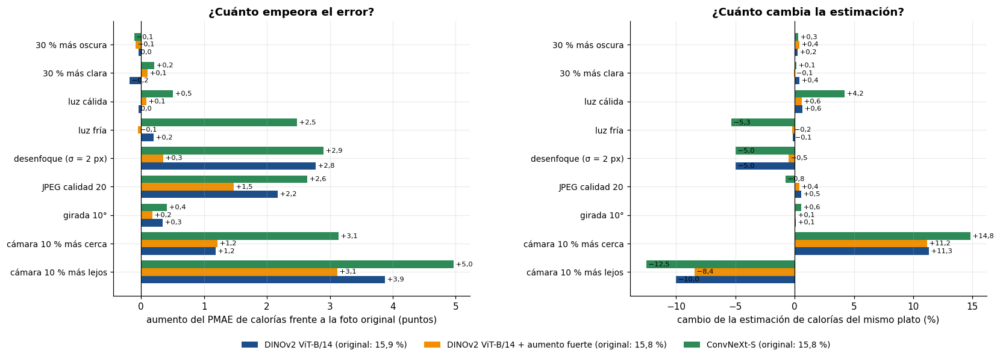

In [52]:
with fase('20b. Prueba de estrés', opcional=True):
    if not ACTIVO['estres']:
        raise RuntimeError('desactivada en la prueba de humo')
    fil_te = FUENTES['cenital'].indices('TE')
    y_te = Y_CEN[fil_te]
    filas = []
    RED_D = BACKBONES['dinov2_b']['nombre']
    grupos_e = [(RED_D, lambda t: t['bb'] == 'dinov2_b' and t.get('aug') != 'fuerte'),
                (RED_D + ' + aumento fuerte', lambda t: t['bb'] == 'dinov2_b' and t.get('aug') == 'fuerte'),
                (BACKBONES['convnext_s']['nombre'], lambda t: t['bb'] == 'convnext_s')]
    for etiqueta, cond in grupos_e:
        c = [n for n, r in RES.items() if r.get('estado') is not None and r['t']['fuentes'] == ['cenital']
             and not r['t'].get('prof') and cond(r['t'])]
        if not c:
            continue
        n = min(c, key=lambda n: RES[n]['val'])
        m = modelo_desde(RES[n], DEV)
        out = estres(m, fil_te, DEV)
        del m
        pm0 = pmae(y_te, out['original'])[0]
        for alteracion, pr in out.items():
            pm = pmae(y_te, pr)
            filas.append(dict(red=etiqueta, modelo=n, alteracion=alteracion, pmae_kcal=pm[0], pmae_masa=pm[1],
                              aumento_pmae_kcal=pm[0] - pm0,
                              cambio_kcal=100 * (pr[:, 0].sum() / out['original'][:, 0].sum() - 1)))
    if not filas:
        raise RuntimeError('no hay modelos de solo foto con sus pesos en memoria')
    TAB_ESTRES = pd.DataFrame(filas)
    TAB_ESTRES.to_csv(TAB / '11_estres.csv', index=False)
    display(TAB_ESTRES.drop(columns='modelo').round(2))
    alts = [a for a in PERTURBACIONES if a != 'original']
    redes = list(dict.fromkeys(TAB_ESTRES.red))
    fig, axs = plt.subplots(1, 2, figsize=(17, 5.4))
    fig.subplots_adjust(wspace=0.45)
    yy, h = np.arange(len(alts))[::-1], 0.8 / len(redes)
    for i, red in enumerate(redes):
        t_ = TAB_ESTRES[TAB_ESTRES.red == red].set_index('alteracion').reindex(alts)
        ys = yy + (i - (len(redes) - 1) / 2) * h
        for ax, col in ((axs[0], 'aumento_pmae_kcal'), (axs[1], 'cambio_kcal')):
            ax.barh(ys, t_[col].values, h, color=PALETA[i],
                    label=f'{red} (original: {coma(t_.pmae_kcal.iloc[0] - t_.aumento_pmae_kcal.iloc[0])} %)' if ax is axs[0] else None)
            for yi, v in zip(ys, t_[col].values):
                if np.isfinite(v):
                    ax.text(v, yi, f' {con_signo(v)}', va='center', fontsize=7.5)
    for ax in axs:
        ax.set_yticks(yy); ax.set_yticklabels(alts, fontsize=9)
        ax.axvline(0, color='k', lw=0.8)
    axs[0].set_xlabel('aumento del PMAE de calorías frente a la foto original (puntos)')
    axs[0].set_title('¿Cuánto empeora el error?')
    axs[1].set_xlabel('cambio de la estimación de calorías del mismo plato (%)'); axs[1].set_title('¿Cuánto cambia la estimación?')
    fig.legend(loc='lower center', ncol=len(redes), fontsize=9, bbox_to_anchor=(0.5, -0.06))
    guardar_fig(fig, '19b_estres')

**Lectura:** con DINOv2, la luz (±30 %, cálida o fría) cambia el error en 0,2 puntos o menos. El desenfoque (+2,8 puntos), la compresión JPEG fuerte (+2,2) y sobre todo la distancia de la cámara afectan más: con la cámara un 10 % más lejos el error sube 3,9 puntos y la estimación de calorías cambia −10,0 %, y con la cámara un 10 % más cerca sube 1,2 puntos y la estimación cambia +11,3 %. El área aparente de la comida cambia +21 % y −17 %, así que el modelo responde a la distancia casi proporcionalmente. ConvNeXt-S es más sensible: la luz fría sube 2,5 puntos, y la distancia, 3,1 y 5,0. El aumento fuerte protege del desenfoque (+0,35 en lugar de +2,8) y de la compresión (+1,5 en lugar de +2,2), pero no de la distancia (+1,2 y +3,1), lo esperable porque no incluye zoom. En la práctica, la foto debe tomarse a una distancia fija o con un objeto de referencia.

## 26. Prueba con fotos propias (opcional)

Si antes de correr se agrega un dataset de Kaggle cuyo nombre contenga **`mis-platos`**, con fotos de platos tomadas **desde arriba, a unos 35 cm y con el plato centrado** (como la cámara de Nutrition5k), aquí se estiman sus calorías con el mejor modelo de solo foto y con el mejor de profundidad estimada, cada uno con su intervalo del 90 %. Si además se incluye un `.csv` con las columnas `archivo,kcal` (el valor real, por ejemplo calculado pesando los ingredientes), se muestra al lado. Sin fotos, la sección se salta.

Al tratarse de una cocina, una vajilla y una cámara que el modelo nunca vio, cabe esperar un error al menos igual al de la Cafe 2 y que los intervalos, calibrados en la Cafe 1, se queden cortos.

In [53]:
def buscar_fotos_propias(raiz=Path('/kaggle/input')):
    """Fotos propias en un dataset cuyo nombre contenga «mis-platos» (o «fotos-propias»)."""
    exts = ('.jpg', '.jpeg', '.png', '.webp')
    claves = ('mis-platos', 'mis_platos', 'misplatos', 'fotos-propias', 'fotos_propias')
    if not Path(raiz).exists():
        return []
    for dirpath, dirnames, filenames in os.walk(raiz):
        dirnames[:] = [d for d in dirnames if not d.startswith('dish_')]
        if any(k in dirpath.lower() for k in claves):
            fotos = sorted(Path(dirpath) / f for f in filenames if f.lower().endswith(exts))
            if fotos:
                return fotos[:24]
    return []

def preparar_foto(ruta):
    """Foto de celular → uint8 (3, 336, 448): gira las verticales, recorta al centro en proporción 3:4 y reduce."""
    from PIL import Image, ImageOps
    im = ImageOps.exif_transpose(Image.open(ruta)).convert('RGB')
    if im.height > im.width:
        im = im.rotate(90, expand=True)                  # visto desde arriba, el plato no tiene «arriba»
    H, W = CFG['tam_cenital']
    w, h = im.size
    if w / h > W / H:
        nw = int(h * W / H)
        im = im.crop(((w - nw) // 2, 0, (w - nw) // 2 + nw, h))
    else:
        nh = int(w * H / W)
        im = im.crop((0, (h - nh) // 2, w, (h - nh) // 2 + nh))
    return np.asarray(im.resize((W, H), Image.BILINEAR)).transpose(2, 0, 1).copy()

@torch.no_grad()
def predecir_fotos(modelo, rgb_u8, extra_u8, dev):
    """Predicción con TTA (4 volteos) sobre arreglos de fotos ya preparados."""
    rgb = torch.from_numpy(rgb_u8).to(dev).float() / 255
    extra = torch.from_numpy(extra_u8).to(dev).float() if extra_u8 is not None else None
    acc = 0
    for dims in [(), (-1,), (-2,), (-2, -1)]:
        r = rgb.flip(dims) if dims else rgb
        a = (extra.flip(dims) if dims else extra) if extra is not None else None
        with autocast(dev):
            x, v = modelo.preparar(r, a)
            acc = acc + modelo(x, v).float()
    return (acc / 4).cpu().numpy()

In [54]:
with fase('21. Fotos propias', opcional=True):
    fotos = buscar_fotos_propias()
    if not fotos:
        print('No se agregaron fotos propias (dataset «mis-platos»): se omite esta sección.')
    else:
        X = np.stack([preparar_foto(f) for f in fotos])
        c_ = 0.1 * MEDIAS
        filas_vc = FUENTES['cenital'].indices('VC')
        modelos = []
        for etiqueta, profs in [('solo foto', (False,)), ('profundidad estimada', ('estimada',))]:
            c = [n for n, r in RES.items() if r.get('estado') is not None and r['t'].get('prof', False) in profs
                 and r['t']['fuentes'] == ['cenital']]
            if c:
                modelos.append((etiqueta, min(c, key=lambda n: RES[n]['val'])))
        EST_FOTOS = estimar_profundidad(X, DEV) if any(e == 'profundidad estimada' for e, _ in modelos) else None
        reales = None
        csvs = sorted(fotos[0].parent.glob('*.csv'))
        if csvs:
            try:
                d = pd.read_csv(csvs[0])
                d.columns = [str(c).strip().lower() for c in d.columns]
                reales = d.set_index(d.columns[0])
            except Exception as e:
                aviso(f'No se pudo leer {csvs[0].name}: {e}')
        filas = []
        res_f = {}
        for etiqueta, n in modelos:
            m = modelo_desde(RES[n], DEV)
            p = predecir_fotos(m, X, EST_FOTOS if m.canal == 'est' else None, DEV)
            q = cuantil_conformal(Y_CEN[filas_vc], RES[n]['pred'][('cenital', 'VC')], CFG['alpha'], c_)
            lo, hi = intervalo(p, q, c_)
            res_f[etiqueta] = (p, lo, hi)
            for i, f in enumerate(fotos):
                filas.append(dict(archivo=f.name, modelo=etiqueta, kcal=p[i, 0], kcal_bajo=lo[i, 0], kcal_alto=hi[i, 0],
                                  masa=p[i, 1], grasa=p[i, 2], carb=p[i, 3], prot=p[i, 4]))
            del m
        TAB_FOTOS = pd.DataFrame(filas)
        TAB_FOTOS.to_csv(TAB / '10_fotos_propias.csv', index=False)
        display(TAB_FOTOS.round(0))
        nf = len(fotos); ncol = min(4, nf); nrow = int(np.ceil(nf / ncol))
        fig, axs = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 4.3 * nrow), squeeze=False)
        for i, f in enumerate(fotos):
            ax = axs.ravel()[i]
            ax.imshow(X[i].transpose(1, 2, 0)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            lineas = [f'{et}: {p[i, 0]:.0f} kcal ({lo[i, 0]:.0f}-{hi[i, 0]:.0f}) · C {p[i, 3]:.0f} g'
                      for et, (p, lo, hi) in res_f.items()]
            if reales is not None and f.name in reales.index and 'kcal' in reales.columns:
                lineas.append(f'real: {float(reales.loc[f.name, "kcal"]):.0f} kcal')
            ax.set_title('\n'.join(lineas), fontsize=8)
        for a in axs.ravel()[nf:]:
            a.axis('off')
        fig.suptitle('Fotos propias: estimación con intervalo del 90 % (calibrado en la Cafe 1)', y=1.0)
        guardar_fig(fig, '21_fotos_propias')


21. Fotos propias   (minuto 561, quedan 99 min)
No se agregaron fotos propias (dataset «mis-platos»): se omite esta sección.


**Lectura:** no se agregaron fotos propias en esta ejecución, de modo que la sección no se ejecutó.

## 27. Recursos usados y guardado

Tiempo de cada fase y de cada entrenamiento, junto con el hardware usado. Se guardan los pesos del mejor modelo de cada tipo de entrada, para usarlos después con fotos propias.

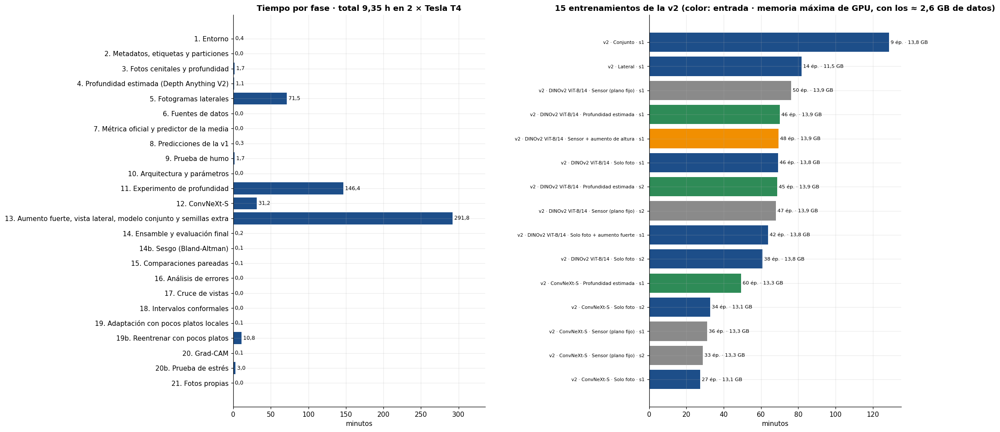


22. Guardado   (minuto 561, quedan 99 min)
Listo en 9.35 h. Archivos en /kaggle/working/outputs:
  figuras/00_metodo.png  (0.2 MB)
  figuras/00b_arquitectura.png  (0.1 MB)
  figuras/01_etiquetas.png  (0.2 MB)
  figuras/02_cafe2.png  (0.1 MB)
  figuras/03_volumen_cafes.png  (0.2 MB)
  figuras/04_profundidades.png  (1.6 MB)
  figuras/05_ejemplos.png  (1.8 MB)
  figuras/06_cadenas.png  (0.6 MB)
  figuras/07_aumento.png  (1.2 MB)
  figuras/08_v1_resumen.png  (0.1 MB)
  figuras/09_v1_sesgo.png  (0.1 MB)
  figuras/10_profundidad.png  (0.1 MB)
  figuras/11_curvas_profundidad.png  (0.2 MB)
  figuras/11b_curvas_aumento.png  (0.1 MB)
  figuras/12_literatura.png  (0.1 MB)
  figuras/13_pred_vs_real.png  (0.3 MB)
  figuras/13a_bland_altman.png  (0.3 MB)
  figuras/13b_comparaciones.png  (0.2 MB)
  figuras/14_errores_por_grupo.png  (0.2 MB)
  figuras/15_cruce_vistas.png  (0.1 MB)
  figuras/16_intervalos.png  (0.1 MB)
  figuras/17_adaptacion_local.png  (0.2 MB)
  figuras/17b_reentrenar_pocos_platos.p

In [55]:
fases = pd.DataFrame([dict(fase=k, minutos=v['min'], ok=v['ok']) for k, v in REPORTE['fases'].items()])
corr = pd.DataFrame([dict(nombre=n, etapa=r['t'].get('etapa', ''), red=BACKBONES[r['t']['bb']]['nombre'],
                          entrada=PROF_ES.get(r['t'].get('prof', False)), minutos=r['min'], epocas=r['epocas'],
                          mejor_epoca=r['mejor_epoca'], micro_lote=r.get('micro'), memoria_gpu_gb=r.get('mem_gb'), val=r['val'])
                     for n, r in RES.items() if not r.get('v1')])
corr.to_csv(TAB / '09_entrenamientos_v2.csv', index=False)
fig, axs = plt.subplots(1, 2, figsize=(18, 0.36 * max(len(fases), len(corr)) + 2))
fig.subplots_adjust(wspace=0.65)
axs[0].barh(fases.fase, fases.minutos, color=[COL['azul'] if o else COL['rojo'] for o in fases.ok])
for i, mm in enumerate(fases.minutos):
    axs[0].text(mm, i, f' {coma(mm)}', va='center', fontsize=8)
axs[0].set_xlim(0, max(1, fases.minutos.max()) * 1.15)
axs[0].invert_yaxis(); axs[0].set_xlabel('minutos')
gpu = REPORTE['entorno'].get('gpus', ['?'])
axs[0].set_title(f'Tiempo por fase · total {coma(minutos() / 60, 2)} h en {len(gpu)} × {gpu[0] if gpu else "CPU"}')
if len(corr):
    cs = corr.sort_values('minutos')
    axs[1].barh(cs.nombre, cs.minutos, color=[COL_PROF.get(next((k for k, v in PROF_ES.items() if v == e), False), COL['gris'])
                                              for e in cs.entrada])
    for i, (mm, ep, gb) in enumerate(zip(cs.minutos, cs.epocas, cs.memoria_gpu_gb)):
        axs[1].text(mm, i, f' {ep} ép. · {coma(gb or 0)} GB', va='center', fontsize=7.5)
    axs[1].set_xlabel('minutos')
    axs[1].set_title(f'{len(corr)} entrenamientos de la v2 (color: entrada · memoria máxima de GPU, con los ≈ 2,6 GB de datos)')
    axs[1].tick_params(axis='y', labelsize=7)
guardar_fig(fig, '20_tiempos')

with fase('22. Guardado', opcional=True):
    guardados = {}
    for etiqueta, profs in [('rgb', (False,)), ('estimada', ('estimada',)), ('sensor', ('sensor', 'sensor_aum'))]:
        c = [n for n, r in RES.items() if r.get('estado') is not None and r['t'].get('prof', False) in profs]
        if c:
            n = min(c, key=lambda n: RES[n]['val'])
            torch.save(dict(receta=RES[n]['t'], estado=RES[n]['estado'], medias=MEDIAS, dens_media=DENS_MEDIA,
                            tam=CFG['tam_cenital'], vol_mu=VOL_MU, vol_sd=VOL_SD), OUT / f'modelo_{etiqueta}.pt')
            guardados[etiqueta] = n
    c = [n for n, r in RES.items() if r.get('estado') is not None and len(r['t']['fuentes']) == 2]
    if c:                                              # el modelo conjunto (las dos vistas), útil para fotos en ángulo
        n = min(c, key=lambda n: RES[n]['val'])
        torch.save(dict(receta=RES[n]['t'], estado=RES[n]['estado'], medias=MEDIAS, dens_media=DENS_MEDIA,
                        tam=CFG['tam_cenital']), OUT / 'modelo_conjunto.pt')
        guardados['conjunto'] = n
    resumen = dict(entorno=REPORTE['entorno'], datos=REPORTE['datos'], decisiones=REPORTE.get('decisiones'),
                   activos=ACTIVO, avisos=REPORTE['avisos'], fases=REPORTE['fases'], modelos_guardados=guardados,
                   ensambles={k: dict(miembros=v['miembros'], val=v['val']) for k, v in ENS.items()},
                   ensambles_semillas={k: v['miembros'] for k, v in ENS_SEM.items()},
                   final=TAB_FINAL.to_dict(orient='records'), literatura=LITERATURA,
                   entrenamientos=corr.to_dict(orient='records'), minutos_totales=minutos())
    for nombre_t in ('TAB_P', 'TAB_INT', 'TAB_VISTAS', 'TAB_ERR', 'SESGO_V1', 'TAB_COMP', 'TAB_PRACT', 'TAB_PARAM', 'HIPER',
                     'TAB_BA', 'TAB_ESTRES'):
        if nombre_t in globals():
            resumen[nombre_t.lower()] = globals()[nombre_t].to_dict(orient='records')
    if 'AD' in globals():
        resumen['adaptacion_local'] = AD.groupby(['ensamble', 'k']).mean().reset_index().to_dict(orient='records')
    if AJ is not None and len(AJ):
        resumen['reentrenar_pocos_platos'] = (AJ.groupby(['modelo', 'metodo', 'k']).mean(numeric_only=True)
                                              .reset_index().to_dict(orient='records'))
    guardar_json(resumen, OUT / 'results.json')
    guardar_json(REPORTE, OUT / 'reporte_corrida.json')
    # Resumen en Markdown con las tablas clave, listo para copiar al informe
    def tabla_md(df, cols, titulos=None, dec=1):
        titulos = titulos or cols
        lineas = ['| ' + ' | '.join(titulos) + ' |', '|' + '---|' * len(cols)]
        for _, r in df[cols].iterrows():
            celdas = [('–' if np.isnan(v) else coma(v, dec)) if isinstance(v, (float, np.floating)) else str(v) for v in r.values]
            lineas.append('| ' + ' | '.join(celdas) + ' |')
        return '\n'.join(lineas)
    partes = ['# Resumen para el informe', '', f'Corrida de {coma(minutos() / 60, 1)} h en {len(gpu)} × {gpu[0] if gpu else "CPU"}.', '']
    tf = TAB_FINAL[TAB_FINAL.modelo.str.startswith('Ensamble') & ~TAB_FINAL.modelo.str.contains('sin ')]
    partes += ['## Resultados finales (PMAE en %, MAE en kcal)',
               tabla_md(tf, ['modelo', 'conjunto', 'n', 'PMAE_kcal', 'PMAE_masa', 'PMAE_grasa', 'PMAE_carb', 'PMAE_prot',
                             'MAE_kcal', 'kcal_ic_bajo', 'kcal_ic_alto'],
                        ['Modelo', 'Conjunto', 'n', 'Calorías', 'Masa', 'Grasa', 'Carb.', 'Prot.', 'MAE kcal', 'IC bajo', 'IC alto']), '']
    if 'TAB_COMP' in globals() and len(TAB_COMP):
        partes += ['## Comparaciones pareadas (PMAE de calorías)',
                   tabla_md(TAB_COMP, ['comparacion', 'conjunto', 'A', 'B', 'delta', 'bajo', 'alto'],
                            ['Comparación', 'Conjunto', 'A', 'B', 'A − B', 'IC bajo', 'IC alto']), '']
    if 'TAB_P' in globals() and len(TAB_P):
        tp = TAB_P.groupby(['version', 'variante']).mean(numeric_only=True).reset_index()
        partes += ['## Experimento de profundidad (DINOv2, promedio de semillas)',
                   tabla_md(tp, ['version', 'variante', 'TE_kcal', 'C2_kcal', 'TE_sesgo_masa', 'C2_sesgo_masa'],
                            ['Versión', 'Entrada', 'Test kcal', 'Cafe 2 kcal', 'Sesgo masa test', 'Sesgo masa Cafe 2']), '']
    if 'TAB_PRACT' in globals():
        partes += ['## Precisión práctica (% de platos)',
                   tabla_md(TAB_PRACT, ['ensamble', 'conjunto', 'a_50_kcal', 'a_100_kcal', 'a_20_pct', 'carb_a_10g'],
                            ['Ensamble', 'Conjunto', '±50 kcal', '±100 kcal', '±20 %', '±10 g carb.']), '']
    if 'TAB_INT' in globals():
        partes += ['## Intervalos del 90 %',
                   tabla_md(TAB_INT, ['ensamble', 'conjunto', 'objetivo', 'cobertura', 'ancho_medio'],
                            ['Ensamble', 'Conjunto', 'Objetivo', 'Cobertura %', 'Ancho medio']), '']
    if 'TAB_BA' in globals():
        ba_ = TAB_BA[TAB_BA.objetivo.isin(['Calorías', 'Grasa'])]
        partes += ['## Sesgo y límites de acuerdo (Bland-Altman), y corrección del sesgo con VC',
                   tabla_md(ba_, ['ensamble', 'conjunto', 'objetivo', 'sesgo', 'sesgo_pct', 'sesgo_pct_bajo', 'sesgo_pct_alto',
                                  'lim_bajo', 'lim_alto', 'pmae', 'sesgo_pct_corr', 'pmae_corr'],
                            ['Ensamble', 'Conjunto', 'Objetivo', 'Sesgo', 'Sesgo %', 'IC bajo %', 'IC alto %',
                             'Límite bajo', 'Límite alto', 'PMAE %', 'Sesgo corregido %', 'PMAE corregido %']), '']
    if 'AD' in globals():
        ad_ = AD.groupby(['ensamble', 'k']).mean(numeric_only=True).reset_index()
        partes += ['## Adaptación con k platos de la Cafe 2 (k cadenas distintas)',
                   tabla_md(ad_, ['ensamble', 'k', 'pmae_kcal', 'pmae_masa', 'cobertura_kcal', 'ancho_kcal',
                                  'cobertura_esc_kcal', 'ancho_esc_kcal'],
                            ['Ensamble', 'k', 'PMAE kcal', 'PMAE masa', 'Cobertura %', 'Ancho kcal',
                             'Cobertura escalado %', 'Ancho escalado kcal']), '']
    if AJ is not None and len(AJ):
        aj_ = AJ.groupby(['modelo', 'metodo', 'k']).mean(numeric_only=True).reset_index()
        partes += ['## Reentrenar con k platos de la Cafe 2 (promedio de las particiones)',
                   tabla_md(aj_, ['modelo', 'metodo', 'k', 'pmae_kcal', 'pmae_masa', 'pmae_carb', 'sesgo_kcal'],
                            ['Modelo', 'Método', 'k', 'PMAE kcal', 'PMAE masa', 'PMAE carb.', 'Sesgo kcal %']), '']
    if 'TAB_ESTRES' in globals():
        partes += ['## Prueba de estrés (test cenital, sin TTA)',
                   tabla_md(TAB_ESTRES, ['red', 'alteracion', 'pmae_kcal', 'aumento_pmae_kcal', 'pmae_masa', 'cambio_kcal'],
                            ['Red', 'Alteración', 'PMAE kcal', 'Aumento (puntos)', 'PMAE masa', 'Cambio de la estimación %']), '']
    (OUT / 'resumen_informe.md').write_text('\n'.join(partes), encoding='utf-8')
    print(f'Listo en {minutos() / 60:.2f} h. Archivos en {OUT}:')
    for p in sorted(OUT.rglob('*')):
        if p.is_file() and p.parent.name not in ('predicciones', 'corridas'):
            print(f'  {p.relative_to(OUT)}  ({p.stat().st_size / 1e6:.1f} MB)')

**Lectura:** la ejecución completa tardó 9,35 h en 2 × T4 (Python 3.13, torch 2.11, timm 1.0.29, transformers 5.16.1, 33,7 GB de RAM y 4 CPU). Las semillas 3 a 5 de la cola se omitieron por falta de tiempo, de modo que cada configuración final tiene 2 semillas.

## 28. Conclusiones

Se escriben con los números de esta corrida: la celda los toma de las tablas, así que cada afirmación corresponde a un resultado medido.

In [56]:
def _f(modelo, conjunto, col='PMAE_kcal'):
    r = fila_final(modelo, conjunto)
    return None if r is None or pd.isna(r.get(col)) else float(r[col])

def _comp(nombre, g='TE'):
    if 'TAB_COMP' not in globals() or not len(TAB_COMP):
        return None
    t_ = TAB_COMP[(TAB_COMP.comparacion == nombre) & (TAB_COMP.conjunto == GRUPO_ES[g])]
    return t_.iloc[0] if len(t_) else None

def _txt(c):
    """«bajó de 15,9 a 15,1 % (IC 95 % de la diferencia: −1,2 a −0,4 puntos; diferencia real)»."""
    sig = 'diferencia real' if (c.alto < 0 or c.bajo > 0) else 'no distinguible del ruido'
    if round(c.delta, 1) == 0:
        cambio = f'se mantuvo en {coma(c.A)} %'
    else:
        cambio = f'{"bajó" if c.delta < 0 else "subió"} de {coma(c.B)} a {coma(c.A)} %'
    return f'{cambio} (IC 95 % de la diferencia: {coma(c.bajo)} a {coma(c.alto)} puntos; {sig})'

def conclusiones():
    L = ['### Respuesta al problema']
    te, c2 = _f(f'Ensamble · {clave_p}', 'TE'), _f(f'Ensamble · {clave_p}', 'C2')
    if te is not None:
        mk, mm = _f(f'Ensamble · {clave_p}', 'TE', 'MAE_kcal'), _f(f'Ensamble · {clave_p}', 'TE', 'PMAE_masa')
        L.append(f'- **Sí se pueden estimar las calorías de un plato a partir de una foto cenital, con condiciones.** El ensamble '
                 f'«{clave_p}» se equivoca en promedio {coma(mk, 0)} kcal ({coma(te)} %) en platos nuevos de la misma cafetería '
                 f'y {coma(mm)} % en la masa. En el estudio original, personas sin formación se equivocaron 53 % en la masa y '
                 'nutricionistas, 41 %.')
        try:
            pr = TAB_PRACT[TAB_PRACT.ensamble == clave_p].set_index('conjunto')
            L.append(f'- En la práctica, el {coma(pr.loc[GRUPO_ES["TE"], "a_50_kcal"], 0)} % de los platos del test queda a menos '
                     f'de 50 kcal del valor real y el {coma(pr.loc[GRUPO_ES["TE"], "carb_a_10g"], 0)} % a menos de 10 g de '
                     f'carbohidratos; en la Cafe 2, el {coma(pr.loc[GRUPO_ES["C2"], "a_50_kcal"], 0)} % y el '
                     f'{coma(pr.loc[GRUPO_ES["C2"], "carb_a_10g"], 0)} %.')
        except Exception:
            pass
        rgb_te, est_te = _f('Ensamble · Solo foto', 'TE'), _f('Ensamble · Foto + profundidad estimada', 'TE')
        if rgb_te is not None and clave_p != 'Solo foto':
            frase = f'- Solo con la foto, que es lo que tendría un celular, el error es {coma(rgb_te)} %'
            if est_te is not None and round(est_te, 1) != round(rgb_te, 1):
                frase += f'; sumando la profundidad estimada desde la misma foto, {coma(est_te)} %'
            L.append(frase + '.')
        L.append(f'- **Pero solo donde se entrenó o se calibró:** en otra cafetería el error sube a {coma(c2)} %.')
    try:
        ba = TAB_BA[(TAB_BA.ensamble == clave_p) & (TAB_BA.objetivo == 'Calorías')].set_index('conjunto')
        bg = TAB_BA[(TAB_BA.ensamble == clave_p) & (TAB_BA.objetivo == 'Grasa')].set_index('conjunto')
        te_b, c2_b = ba.loc[GRUPO_ES['TE']], ba.loc[GRUPO_ES['C2']]
        L.append(f'- **Sesgo (Bland-Altman):** en el test el ensamble se desvía {con_signo(te_b.sesgo_pct)} % en calorías '
                 f'(IC 95 %: {coma(te_b.sesgo_pct_bajo)} a {coma(te_b.sesgo_pct_alto)} %) y {con_signo(bg.loc[GRUPO_ES["TE"], "sesgo"])} g '
                 f'en grasa; en la Cafe 2, {con_signo(c2_b.sesgo_pct)} % (IC {coma(c2_b.sesgo_pct_bajo)} a {coma(c2_b.sesgo_pct_alto)} %) '
                 f'y {con_signo(bg.loc[GRUPO_ES["C2"], "sesgo"])} g. Como referencia, las cuatro apps comerciales que evaluó el NIH '
                 'subestimaron cerca de un tercio de las calorías y ≈ 30 g de grasa por comida (otras comidas, resultados preliminares).')
        L.append(f'- Corregir el sesgo con un factor calculado en la validación lleva el sesgo de calorías del test a '
                 f'{con_signo(te_b.sesgo_pct_corr)} % (error {coma(te_b.pmae)} → {coma(te_b.pmae_corr)} %) y el de la Cafe 2 a '
                 f'{con_signo(c2_b.sesgo_pct_corr)} % (error {coma(c2_b.pmae)} → {coma(c2_b.pmae_corr)} %)'
                 + (': lo que se corrige con datos de casa no alcanza para otro lugar.' if abs(c2_b.sesgo_pct_corr) > 5 else '.'))
    except Exception:
        pass
    L.append('### Objetivo 1 · Transferencia')
    if V1R is not None and V1R.get('tab_b'):
        tb = pd.DataFrame(V1R['tab_b'])
        ft = tb[~tb.red.str.contains('congelada')].sort_values('val_kcal').iloc[0]
        fr = tb[tb.red.str.contains('congelada')]
        L.append(f'- De cinco redes preentrenadas, la mejor fue {ft.red} ({coma(ft.test_kcal)} % en calorías en el test, con '
                 f'ajuste fino). Congeladas, las redes se quedan entre {coma(fr.test_kcal.min())} y {coma(fr.test_kcal.max())} %: '
                 'hay que reentrenar la red completa; una cabeza nueva sobre características fijas no alcanza.')
    rgb, sen = _f('Ensamble · Solo foto', 'TE'), _f('Ensamble · Foto + sensor', 'TE')
    if rgb is not None:
        L.append(f'- Con la misma métrica y el mismo test, el ensamble solo foto queda en {coma(rgb)} % (ResNet-101 publicada: '
                 '17,9 %; DPF-Nutrition: 14,7 %)' + (f' y el ensamble con sensor en {coma(sen)} % (paper original: 18,8 %; '
                                                     'RGB-D Nutrition: 15,0 %).' if sen is not None else '.'))
    L.append('### Objetivo 2 · Qué aporta cada componente')
    try:
        tc = pd.DataFrame(V1R['tab_c']).groupby('paso').test_kcal.mean()
        L.append(f'- Ablación de la v1 (DINOv2): la receta del paper da {coma(tc["L0"])} %; la receta moderna, '
                 f'{coma(tc["L1"])} %; el sensor de profundidad, {coma(tc["L3"])} %. La cabeza factorizada ({coma(tc["L2"])} %) '
                 f'y la limpieza de etiquetas ({coma(tc["L4"])} %) no aportaron de forma clara.')
    except Exception:
        pass
    for nombre, texto in [('DINOv2 solo foto: 80 min − 45 min (v1)', 'Entrenar más tiempo (80 en vez de 45 min)'),
                          ('DINOv2: sensor − solo foto', 'Agregar el sensor de profundidad'),
                          ('DINOv2: profundidad estimada − solo foto', 'Agregar la profundidad estimada con Depth Anything'),
                          ('DINOv2: sensor + aumento de altura − sensor', 'El aumento de altura sobre el sensor'),
                          ('DINOv2 solo foto: aumento fuerte − normal (semilla 1)',
                           'El aumento fuerte (giros, balance de blancos y desenfoque), con la misma semilla'),
                          ('Ensamble con sensor: v2 − v1', 'El ensamble de la v2 frente al de la v1')]:
        a, b = _comp(nombre, 'TE'), _comp(nombre, 'C2')
        if a is not None:
            L.append(f'- {texto}: en el test, el error {_txt(a)}' + (f'; en la Cafe 2, {_txt(b)}.' if b is not None else '.'))
    for clave in ENS_SEM:
        a_ = _f(f'Ensamble · {clave}', 'TE')
        b_ = TAB_FINAL[TAB_FINAL.modelo.str.startswith(f'Ensamble de semillas · {clave} (') & (TAB_FINAL.conjunto == GRUPO_ES['TE'])]
        if a_ is not None and len(b_):
            L.append(f'- Control del ensamble «{clave}»: el voraz da {coma(a_)} % en el test y el promedio de las semillas, '
                     f'sin escoger con la validación, {coma(b_.PMAE_kcal.iloc[0])} %.')
    L.append('### Objetivo 3 · Generalización y confianza')
    for clave in TIPOS_ENS:
        te_, c2_ = _f(f'Ensamble · {clave}', 'TE'), _f(f'Ensamble · {clave}', 'C2')
        if te_ is not None and c2_ is not None:
            L.append(f'- {clave}: {coma(te_)} % en el test y {coma(c2_)} % en la Cafe 2.')
    lat, latf = _f('Ensamble · Vista lateral', 'TE'), _f('Ensamble · Vista lateral (por fotograma)', 'TE')
    if lat is not None:
        frase = (f'- Vista lateral: {coma(lat)} % por plato y {coma(latf)} % por fotograma (el paper reporta 26,1 % por '
                 'fotograma, con otro muestreo de fotogramas).')
        sin = TAB_FINAL[TAB_FINAL.modelo.str.startswith('Ensamble · Vista lateral (sin ') & (TAB_FINAL.conjunto == GRUPO_ES['TE'])]
        if len(sin):
            nimp = re.search(r'sin (\d+)', sin.modelo.iloc[0]).group(1)
            quien = 'el plato' if nimp == '1' else f'los {nimp} platos'
            frase += (f' Sin {quien} del test con etiquetas imposibles, el error por plato baja a '
                      f'{coma(sin.PMAE_kcal.iloc[0])} %: unas pocas etiquetas malas pesan mucho en esta cifra.')
        L.append(frase)
    try:
        ti = TAB_INT[(TAB_INT.objetivo == 'Calorías') & (TAB_INT.ensamble == clave_p)].set_index('conjunto').cobertura
        L.append(f'- Los intervalos del 90 % cubren el {coma(ti[GRUPO_ES["TE"]], 0)} % de los platos del test y el '
                 f'{coma(ti[GRUPO_ES["C2"]], 0)} % en la Cafe 2: la garantía solo vale si los datos nuevos se parecen a los '
                 'de calibración.')
        a = AD[AD.ensamble == clave_p].groupby('k').mean(numeric_only=True)
        k_max = max(k for k in a.index if k <= 20)
        L.append(f'- Pesando {k_max} platos de la Cafe 2 (de cadenas distintas), el error de calorías pasa de {coma(a.loc[0, "pmae_kcal"])} a '
                 f'{coma(a.loc[k_max, "pmae_kcal"])} % y el de masa de {coma(a.loc[0, "pmae_masa"])} a '
                 f'{coma(a.loc[k_max, "pmae_masa"])} %; la cobertura pasa de {coma(a.loc[0, "cobertura_kcal"], 0)} a '
                 f'{coma(a.loc[k_max, "cobertura_kcal"], 0)} %, con intervalos más anchos ({coma(a.loc[0, "ancho_kcal"], 0)} → '
                 f'{coma(a.loc[k_max, "ancho_kcal"], 0)} kcal). Si en vez de recalcular el cuantil se escala el de la Cafe 1, '
                 f'la cobertura queda en {coma(a.loc[k_max, "cobertura_esc_kcal"], 0)} % con {coma(a.loc[k_max, "ancho_esc_kcal"], 0)} kcal '
                 'de ancho.')
    except Exception:
        pass
    try:
        aj = AJ.groupby(['modelo', 'metodo', 'k']).pmae_kcal.mean()
        k_ = 20 if 20 in set(AJ.k) else int(AJ.k.max())
        for etq in AJ.modelo.unique():
            partes_ = [f'{met.lower()}, {coma(aj[(etq, met, k_)])} %' for met in
                       ('Sin ajuste', 'Factor de escala', 'Reentrenar la cabeza', 'Reentrenar la red completa') if (etq, met, k_) in aj.index]
            L.append(f'- Con {k_} platos de la Cafe 2 (modelo «{etq}», error de calorías en el resto de la Cafe 2): ' + '; '.join(partes_) + '.')
    except Exception:
        pass
    try:
        te_ = TAB_ESTRES.set_index(['red', 'alteracion'])
        red0 = BACKBONES['dinov2_b']['nombre']
        ce, pe = te_.loc[red0].cambio_kcal, te_.loc[red0].aumento_pmae_kcal.drop('original')
        L.append(f'- Prueba de estrés ({red0}): con la cámara 10 % más cerca, la estimación de calorías cambia '
                 f'{con_signo(ce["cámara 10 % más cerca"])} % y con la cámara 10 % más lejos, {con_signo(ce["cámara 10 % más lejos"])} %; '
                 'como referencia, el área aparente de la comida cambia +21 % y −17 %. La alteración que más sube el error es '
                 f'«{pe.idxmax()}» ({con_signo(pe.max())} puntos de PMAE).')
        rf_ = red0 + ' + aumento fuerte'
        if rf_ in te_.index.get_level_values(0):
            pf = te_.loc[rf_].aumento_pmae_kcal.drop('original')
            L.append(f'- Con el aumento fuerte, esa misma alteración sube el error {con_signo(pf[pe.idxmax()])} puntos en vez de '
                     f'{con_signo(pe.max())}, y en promedio las alteraciones lo suben {con_signo(pf.mean())} puntos en vez de '
                     f'{con_signo(pe.mean())}.')
    except Exception:
        pass
    try:
        te_err = TAB_ERR[TAB_ERR.conjunto == GRUPO_ES['TE']].set_index('grupo')
        peor = te_err.PMAE_kcal.idxmax()
        inv = [g for g in te_err.index if g.startswith('≥ 25 %')]
        nin = [g for g in te_err.index if g.startswith('< 25 %')]
        frase = f'- Dónde falla: el error más alto está en «{peor}» ({coma(te_err.loc[peor, "PMAE_kcal"])} %)'
        if inv and nin:
            frase += (f', y los platos donde el aceite o los aderezos aportan al menos un cuarto de las calorías llegan a '
                      f'{coma(te_err.loc[inv[0], "PMAE_kcal"])} % frente a {coma(te_err.loc[nin[0], "PMAE_kcal"])} %: lo que '
                      'no se ve en la foto no se puede estimar.')
        L.append(frase)
    except Exception:
        pass
    display(Markdown('\n'.join(L)))
    (OUT / 'conclusiones.md').write_text('\n'.join(L), encoding='utf-8')

conclusiones()

### Respuesta al problema
- **Sí se pueden estimar las calorías de un plato a partir de una foto cenital, con condiciones.** El ensamble «Foto + sensor» se equivoca en promedio 35 kcal (13,8 %) en platos nuevos de la misma cafetería y 9,5 % en la masa. En el estudio original, personas sin formación se equivocaron 53 % en la masa y nutricionistas, 41 %.
- En la práctica, el 77 % de los platos del test queda a menos de 50 kcal del valor real y el 91 % a menos de 10 g de carbohidratos; en la Cafe 2, el 49 % y el 72 %.
- Solo con la foto, que es lo que tendría un celular, el error es 15,4 %; sumando la profundidad estimada desde la misma foto, 15,2 %.
- **Pero solo donde se entrenó o se calibró:** en otra cafetería el error sube a 29,5 %.
- **Sesgo (Bland-Altman):** en el test el ensamble se desvía −4,4 % en calorías (IC 95 %: −6,7 a −1,9 %) y −0,7 g en grasa; en la Cafe 2, −19,3 % (IC −24,1 a −14,0 %) y −4,3 g. Como referencia, las cuatro apps comerciales que evaluó el NIH subestimaron cerca de un tercio de las calorías y ≈ 30 g de grasa por comida (otras comidas, resultados preliminares).
- Corregir el sesgo con un factor calculado en la validación lleva el sesgo de calorías del test a −1,4 % (error 13,8 → 13,4 %) y el de la Cafe 2 a −16,8 % (error 29,5 → 28,6 %): lo que se corrige con datos de casa no alcanza para otro lugar.
### Objetivo 1 · Transferencia
- De cinco redes preentrenadas, la mejor fue DINOv2 ViT-B/14 (15,7 % en calorías en el test, con ajuste fino). Congeladas, las redes se quedan entre 23,2 y 25,4 %: hay que reentrenar la red completa; una cabeza nueva sobre características fijas no alcanza.
- Con la misma métrica y el mismo test, el ensamble solo foto queda en 15,4 % (ResNet-101 publicada: 17,9 %; DPF-Nutrition: 14,7 %) y el ensamble con sensor en 13,8 % (paper original: 18,8 %; RGB-D Nutrition: 15,0 %).
### Objetivo 2 · Qué aporta cada componente
- Ablación de la v1 (DINOv2): la receta del paper da 16,9 %; la receta moderna, 15,8 %; el sensor de profundidad, 14,6 %. La cabeza factorizada (15,8 %) y la limpieza de etiquetas (14,7 %) no aportaron de forma clara.
- Entrenar más tiempo (80 en vez de 45 min): en el test, el error subió de 15,6 a 15,8 % (IC 95 % de la diferencia: −0,4 a 0,7 puntos; no distinguible del ruido); en la Cafe 2, bajó de 26,8 a 26,0 % (IC 95 % de la diferencia: −1,9 a 0,4 puntos; no distinguible del ruido).
- Agregar el sensor de profundidad: en el test, el error bajó de 15,8 a 14,2 % (IC 95 % de la diferencia: −2,5 a −0,6 puntos; diferencia real); en la Cafe 2, subió de 26,0 a 30,9 % (IC 95 % de la diferencia: 1,6 a 8,0 puntos; diferencia real).
- Agregar la profundidad estimada con Depth Anything: en el test, el error bajó de 15,8 a 15,4 % (IC 95 % de la diferencia: −0,8 a 0,1 puntos; no distinguible del ruido); en la Cafe 2, subió de 26,0 a 26,4 % (IC 95 % de la diferencia: −0,6 a 1,5 puntos; no distinguible del ruido).
- El aumento de altura sobre el sensor: en el test, el error subió de 14,2 a 15,0 % (IC 95 % de la diferencia: 0,0 a 1,6 puntos; diferencia real); en la Cafe 2, bajó de 30,9 a 25,8 % (IC 95 % de la diferencia: −7,5 a −2,3 puntos; diferencia real).
- El aumento fuerte (giros, balance de blancos y desenfoque), con la misma semilla: en el test, el error se mantuvo en 15,9 % (IC 95 % de la diferencia: −0,5 a 0,5 puntos; no distinguible del ruido); en la Cafe 2, subió de 26,5 a 27,4 % (IC 95 % de la diferencia: −0,2 a 2,1 puntos; no distinguible del ruido).
- El ensamble de la v2 frente al de la v1: en el test, el error bajó de 13,8 a 13,8 % (IC 95 % de la diferencia: −0,2 a 0,1 puntos; no distinguible del ruido); en la Cafe 2, subió de 29,4 a 29,5 % (IC 95 % de la diferencia: −0,1 a 0,4 puntos; no distinguible del ruido).
- Control del ensamble «Solo foto»: el voraz da 15,4 % en el test y el promedio de las semillas, sin escoger con la validación, 15,8 %.
- Control del ensamble «Foto + profundidad estimada»: el voraz da 15,2 % en el test y el promedio de las semillas, sin escoger con la validación, 15,4 %.
- Control del ensamble «Foto + sensor»: el voraz da 13,8 % en el test y el promedio de las semillas, sin escoger con la validación, 14,2 %.
### Objetivo 3 · Generalización y confianza
- Solo foto: 15,4 % en el test y 26,0 % en la Cafe 2.
- Foto + profundidad estimada: 15,2 % en el test y 26,1 % en la Cafe 2.
- Foto + sensor: 13,8 % en el test y 29,5 % en la Cafe 2.
- Vista lateral: 25,4 % por plato y 35,4 % por fotograma (el paper reporta 26,1 % por fotograma, con otro muestreo de fotogramas). Sin los 2 platos del test con etiquetas imposibles, el error por plato baja a 16,5 %: unas pocas etiquetas malas pesan mucho en esta cifra.
- Los intervalos del 90 % cubren el 94 % de los platos del test y el 64 % en la Cafe 2: la garantía solo vale si los datos nuevos se parecen a los de calibración.
- Pesando 20 platos de la Cafe 2 (de cadenas distintas), el error de calorías pasa de 29,5 a 27,8 % y el de masa de 20,0 a 17,1 %; la cobertura pasa de 64 a 90 %, con intervalos más anchos (170 → 367 kcal). Si en vez de recalcular el cuantil se escala el de la Cafe 1, la cobertura queda en 94 % con 441 kcal de ancho.
- Con 20 platos de la Cafe 2 (modelo «Solo foto», error de calorías en el resto de la Cafe 2): sin ajuste, 27,2 %; factor de escala, 27,6 %; reentrenar la cabeza, 27,5 %; reentrenar la red completa, 26,3 %.
- Con 20 platos de la Cafe 2 (modelo «Foto + sensor», error de calorías en el resto de la Cafe 2): sin ajuste, 31,1 %; factor de escala, 27,6 %; reentrenar la cabeza, 26,1 %; reentrenar la red completa, 25,9 %.
- Prueba de estrés (DINOv2 ViT-B/14): con la cámara 10 % más cerca, la estimación de calorías cambia +11,3 % y con la cámara 10 % más lejos, −10,0 %; como referencia, el área aparente de la comida cambia +21 % y −17 %. La alteración que más sube el error es «cámara 10 % más lejos» (+3,9 puntos de PMAE).
- Con el aumento fuerte, esa misma alteración sube el error +3,1 puntos en vez de +3,9, y en promedio las alteraciones lo suben +0,7 puntos en vez de +1,1.
- Dónde falla: el error más alto está en «plato pequeño (0-112 kcal)» (24,0 %), y los platos donde el aceite o los aderezos aportan al menos un cuarto de las calorías llegan a 19,1 % frente a 13,2 %: lo que no se ve en la foto no se puede estimar.

### Conclusiones frente a las preguntas

**1. ¿Se confirma el resultado publicado?** Sí, con matices. El protocolo y la métrica reproducen el script oficial (diferencia máxima de 2 × 10⁻¹³ en el test) y el predictor de la media da 65,4 % de error en calorías, cerca del 60,2 % del artículo. Con la misma métrica y el mismo test, el ensamble con sensor llega a 13,8 % y el de solo foto a 15,4 %. Eso supera a Thames (18,8 %) y a ResNet-101 (17,9 %) y empata, dentro del margen, con DPF-Nutrition (14,7 %) y con Shao (15,0 %). Los autores originales no publicaron pesos, así que su modelo no se reproduce tal cual: la comparación es con las cifras publicadas.

**2. ¿Se aporta algo?** Parcialmente. Lo que se aporta es medir con un mismo protocolo qué suma cada pieza: reentrenar la red completa es indispensable, DINOv2 es la mejor de las cinco redes, el sensor de profundidad ayuda en casa y perjudica en otro lugar (diferencias reales en ambos sentidos), y el aumento de altura corrige ese perjuicio en la Cafe 2 (de 30,9 a 25,8 %) a costa de 0,8 puntos en el test. En cambio, la profundidad estimada con Depth Anything, entrenar más tiempo, el aumento fuerte y el ensamble de esta ejecución frente al de la corrida previa no mejoran el error de forma distinguible del ruido. No se supera con claridad a los mejores resultados publicados, y la aportación principal es el diagnóstico.

**3. ¿Qué tan confiable es?** Solo donde se entrenó o se calibró. En la Cafe 2 el error es de 26 a 29,5 %, el sesgo en calorías llega a −19 % con el sensor y los intervalos del 90 % cubren entre 64 y 81 %. Corregir el sesgo con datos de casa casi no ayuda fuera; pesar de 10 a 20 platos del lugar nuevo sí corrige el sesgo y la cobertura, y reentrenar la red con 40 platos baja además el error por plato (con sensor, de 29,9 a 23,8 %). El modelo falla en platos pequeños, con aceite o aderezos que no se ven y cuando cambia la distancia de la cámara (±10 % de distancia mueve la estimación ≈ ±11 %).


### Limitaciones

- **Lo que no se ve no se estima:** el aceite, la mantequilla y los aderezos explican buena parte de los errores grandes.
- **Una sola muestra externa.** La Cafe 2 tiene 238 platos (228 con foto cenital), con etiquetas reconstruidas sumando ingredientes; la regla se verificó en la Cafe 1. Lo que se concluye sobre «otro lugar» se apoya en ese único caso.
- **La validación interna no detecta los problemas de la cafetería externa.** Escoger modelos con ella es lo correcto, pero no garantiza que funcionen en otro lugar.
- **Dos iteraciones.** Antes de esta ejecución hubo una corrida previa cuyo test ya se había visto. Todas las decisiones se tomaron con la validación, pero conviene declararlo. La corrección del sesgo con VC se propuso después de ver esos resultados; el sesgo también aparece en la validación, así que no depende del test.
- **Pocas semillas.** Cada configuración final tiene 2 semillas (las demás se omitieron por tiempo), de modo que las diferencias menores a un punto entre modelos individuales no son concluyentes.
- **Reentrenar con pocos platos** no tiene validación propia: sus hiperparámetros (40 pasos, tasas bajas) se fijaron antes de correr, y con 3 particiones por *k* las diferencias pequeñas pueden ser ruido.
- **Vista lateral:** se usan 20 fotogramas por plato y no cada quinto fotograma como el artículo, y dos etiquetas imposibles pesan mucho en la cifra por plato.
- **La prueba de estrés** simula las alteraciones sobre fotos de Nutrition5k; no reemplaza fotos reales de celular, con otra óptica y otro ángulo. No se evaluaron fotos propias.
- **La comparación con las apps del NIH** es solo una referencia: son comidas completas distintas a las de Nutrition5k y resultados preliminares.
- **No es un dispositivo médico.** Las estimaciones no sirven para dosificar insulina ni para decisiones clínicas.


## 29. Usos prácticos

- **Comedores con cámara fija** (hospitales, casinos de empresas, universidades): es el escenario más parecido a Nutrition5k. Con una cámara cenital y un sensor de profundidad sobre la bandeja se obtiene el menor error de este trabajo, muy por debajo de lo que logra un nutricionista a ojo (41 % en la masa). Sirve para registrar lo que come un paciente sin pesar la bandeja.
- **Etiquetado nutricional automático** de los platos servidos en una cafetería, en lugar de calcular cada receta a mano.
- **Apoyo en diabetes:** estimar los carbohidratos de una comida a partir de una foto, siempre con el intervalo y como apoyo, nunca para dosificar insulina sin supervisión. Con el error actual en carbohidratos (≈ 21 % en el test y 91 % de los platos a menos de 10 g) no reemplaza el conteo.
- **Seguimiento nutricional** entre consultas: el nutricionista recibe las fotos con estimaciones y márgenes en vez de un diario escrito.
- **Implantación en un lugar nuevo:** pesar unos 10 a 20 platos del sitio y recalibrar es barato y corrige el sesgo y los intervalos; reentrenar con unos 40 platos baja además el error por plato.
- **Frente a las apps comerciales:** el estudio del NIH muestra que las apps actuales subestiman de forma sistemática. Lo que aporta este trabajo es medir el sesgo (Bland-Altman) y corregirlo con unos pocos platos pesados del lugar, en vez de confiar en una cifra sin margen de error.
- **Cómo tomar la foto:** según la prueba de estrés, la distancia de la cámara cambia la estimación. Una app debería fijar la distancia (un soporte, como en los comedores) o usar un objeto de referencia de tamaño conocido.

## 30. Trabajo futuro

- Pesar y fotografiar platos de otras cocinas (por ejemplo, la colombiana: arroz, fríjoles, arepa, carne) para que el modelo sirva en otros contextos.
- Probar con fotos reales de celular, con su sensor de profundidad cuando exista (LiDAR) o con profundidad estimada.
- Segmentar cada ingrediente para estimar su porción por separado.


## Referencias

**Datos y estado del arte en Nutrition5k**
- Thames, Q., Karpur, A., Norris, W., Xia, F., Panait, L., Weyand, T. y Sim, J. (2021). *Nutrition5k: Towards Automatic Nutritional Understanding of Generic Food.* CVPR 2021. [arXiv:2103.03375](https://arxiv.org/abs/2103.03375) · [datos (CC BY 4.0)](https://github.com/google-research-datasets/nutrition5k)
- Han, Y., Cheng, Q., Wu, W. y Huang, Z. (2023). *DPF-Nutrition: Food Nutrition Estimation via Depth Prediction and Fusion.* Foods, 12(23), 4293. [arXiv:2310.11702](https://arxiv.org/abs/2310.11702)
- Shao, W., Min, W., Hou, S., Luo, M., Li, T., Zheng, Y. y Jiang, S. (2023). *Vision-based food nutrition estimation via RGB-D fusion network.* Food Chemistry, 424, 136309.
- Bianco, R., Coluccia, S., Marinoni, M., Falcon, A., Fiori, F., Serra, G., Ferraroni, M., Edefonti, V. y Parpinel, M. (2025). *2D Prediction of the Nutritional Composition of Dishes from Food Images: Deep Learning Algorithm Selection and Data Curation Beyond the Nutrition5k Project.* Nutrients, 17(13), 2196. [doi:10.3390/nu17132196](https://doi.org/10.3390/nu17132196)
- Lian, Y. (2026). *Single-Image Food Mass Estimators Do Not Transfer Their Gram Scale Across Datasets.* [arXiv:2610.29025](https://arxiv.org/abs/2610.29025)
- Charles, O., Hengist, A. et al. (2026). Exactitud de cuatro aplicaciones comerciales de estimación de calorías por foto frente a una cocina metabólica. Resumen presentado en NUTRITION 2026, American Society for Nutrition, National Harbor (25 de julio de 2026); resultados preliminares. [Reseña en ScienceDaily](https://sciencedaily.com/releases/2026/07/260726015237.htm)

**Redes y entrenamiento**
- Yang, L., Kang, B., Huang, Z., Zhao, Z., Xu, X., Feng, J. y Zhao, H. (2024). *Depth Anything V2.* NeurIPS 2024. [arXiv:2406.09414](https://arxiv.org/abs/2406.09414)
- Oquab, M., Darcet, T., Moutakanni, T., Vo, H., Szafraniec, M., Khalidov, V., … Bojanowski, P. (2023). *DINOv2: Learning Robust Visual Features without Supervision.* [arXiv:2304.07193](https://arxiv.org/abs/2304.07193) (TMLR, 2024)
- Darcet, T., Oquab, M., Mairal, J. y Bojanowski, P. (2024). *Vision Transformers Need Registers.* ICLR 2024. [arXiv:2309.16588](https://arxiv.org/abs/2309.16588)
- Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T. y Xie, S. (2022). *A ConvNet for the 2020s.* CVPR 2022. [arXiv:2201.03545](https://arxiv.org/abs/2201.03545)
- He, K., Zhang, X., Ren, S. y Sun, J. (2016). *Deep Residual Learning for Image Recognition.* CVPR 2016. [arXiv:1512.03385](https://arxiv.org/abs/1512.03385)
- Tan, M. y Le, Q. V. (2021). *EfficientNetV2: Smaller Models and Faster Training.* ICML 2021. [arXiv:2104.00298](https://arxiv.org/abs/2104.00298)
- Loshchilov, I. y Hutter, F. (2019). *Decoupled Weight Decay Regularization.* ICLR 2019. [arXiv:1711.05101](https://arxiv.org/abs/1711.05101)
- Caruana, R., Niculescu-Mizil, A., Crew, G. y Ksikes, A. (2004). *Ensemble Selection from Libraries of Models.* ICML 2004. [doi:10.1145/1015330.1015432](https://doi.org/10.1145/1015330.1015432)

**Incertidumbre, explicabilidad y robustez**
- Angelopoulos, A. N. y Bates, S. (2021). *A Gentle Introduction to Conformal Prediction and Distribution-Free Uncertainty Quantification.* [arXiv:2107.07511](https://arxiv.org/abs/2107.07511) (Foundations and Trends in Machine Learning, 2023)
- Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. y Batra, D. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization.* ICCV 2017 (IJCV, 2019). [arXiv:1610.02391](https://arxiv.org/abs/1610.02391)
- Bland, J. M. y Altman, D. G. (1986). *Statistical methods for assessing agreement between two methods of clinical measurement.* The Lancet, 327(8476), 307–310.
- Kumar, A., Raghunathan, A., Jones, R., Ma, T. y Liang, P. (2022). *Fine-Tuning can Distort Pretrained Features and Underperform Out-of-Distribution.* ICLR 2022. [arXiv:2202.10054](https://arxiv.org/abs/2202.10054)
- Hendrycks, D. y Dietterich, T. (2019). *Benchmarking Neural Network Robustness to Common Corruptions and Perturbations.* ICLR 2019. [arXiv:1903.12261](https://arxiv.org/abs/1903.12261)
- Hendrycks, D., Mu, N., Cubuk, E. D., Zoph, B., Gilmer, J. y Lakshminarayanan, B. (2020). *AugMix: A Simple Data Processing Method to Improve Robustness and Uncertainty.* ICLR 2020. [arXiv:1912.02781](https://arxiv.org/abs/1912.02781)
